# 00 — ตรวจสอบและเตรียมชุดข้อมูล (โปรโตคอลที่ทบทวนแล้ว)

**ขอบเขตปัจจุบัน:** ใช้ข้อมูลเดิมสำหรับ grouped development benchmark และ grouped CV ตามส่วน 17 โดยชุดที่โค้ดตรวจจริงคือ `data/gold_fixed_v1` ชุด test เดิมเคยถูกตรวจระหว่างพัฒนาแล้ว จึงไม่อ้างว่าเป็น untouched confirmatory test และไม่ต้องสร้างชุดยืนยันใหม่เป็นเงื่อนไขก่อน train ส่วน `gold_ws` ใช้วิเคราะห์คลิปที่เคยเห็นเท่านั้น การเก็บ metadata/เหตุการณ์/ไซต์ใหม่เลื่อนไว้ตามเจ้าของงาน; group จากชื่อไฟล์ไม่ยืนยันว่าเหตุการณ์เป็นอิสระ

เริ่มด้วยโหมด audit การสร้างชุดข้อมูลปิดไว้โดยค่าเริ่มต้นและต้องใช้ไดเรกทอรีใหม่ ไม่ลบชุดเดิม โค้ดประมวลผลอยู่ใน notebook นี้ ใช้แพ็กเกจภายนอก ไม่พึ่งโมดูล Python ภายในโครงการ

นิยามงาน: จำแนกและแบ่ง **บริเวณวัสดุที่มี annotation** เป็น gravel/sand ไม่ใช่เม็ดวัสดุรายเม็ด มวล หรือปริมาตร ต้องให้ผู้ตรวจยืนยันเกณฑ์แบ่งบริเวณ; label อัตโนมัติเป็น pseudo-GT ไม่ใช่ความจริงที่ผ่านการตรวจอิสระ

รายการตรวจ: geometry/ภาพซ้ำ, ความไวของกฎลบและคิวผู้ตรวจ, merged-group/near-duplicate, การกระจาย split, การ clip polygon หลัง augmentation, lineage/checksum, การเปรียบเทียบ contrast แบบจับคู่ และ handoff ไป notebook 16 ส่วน EDA เก่าด้านล่างเก็บไว้เป็นประวัติ ให้ยึด final audit และส่วน CV เป็นหลัก

### ดาวน์โหลดชุดข้อมูลจาก Roboflow

In [1]:
# ============================================================
# DOWNLOAD ROBOFLOW DATASET
# ============================================================

import os, json, hashlib, platform, shutil
from pathlib import Path
from datetime import datetime, timezone

candidates = [Path.cwd(), Path.cwd() / 'experiment', Path.home() / 'Desktop/Aggregate_Project/experiment']
EXP = next((p for p in candidates if (p / 'data/bronze').is_dir()), None)
if EXP is None:
    raise FileNotFoundError('Open this notebook from the experiment directory or set EXP explicitly.')
BUILD_DATASETS = False
STAMP = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
AUDIT_OUT = EXP / 'results' / 'nb00_audit' / STAMP
AUDIT_OUT.mkdir(parents=True, exist_ok=False)

def new_dataset_dir(path):
    path = Path(path)
    if path.exists():
        raise FileExistsError(f'Refusing to overwrite {path}; select a new dataset version.')
    path.mkdir(parents=True)
    return path

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------
WORKSPACE = 'ilovefoods-workspace-qd0ut'
PROJECT = 'aggregate_rock-and-sand'
VERSION = 5
DATASET_DIR = EXP / 'data' / 'bronze'

# ------------------------------------------------------------
# Idempotent: skip download when bronze already exists.
# Set ROBOFLOW_API_KEY in the environment to (re)download —
# never commit keys to the repo.
# ------------------------------------------------------------
if (DATASET_DIR / 'train' / 'images').exists():
    n = len(list((DATASET_DIR / 'train' / 'images').iterdir()))
    print(f'bronze already exists ({n} train images) — skipping download')
    dataset = None
else:
    if not BUILD_DATASETS:
        raise FileNotFoundError('bronze missing; explicitly enable BUILD_DATASETS to download.')
    from roboflow import Roboflow
    rf = Roboflow(api_key=os.environ['ROBOFLOW_API_KEY'])
    project = rf.workspace(WORKSPACE).project(PROJECT)
    dataset = project.version(VERSION).download(model_format='yolo26', location=str(DATASET_DIR), overwrite=False)

print('\n' + '=' * 70)
print('DOWNLOAD CELL DONE')
print('=' * 70)
print(f'Dataset location: {DATASET_DIR}')

bronze already exists (751 train images) — skipping download

DOWNLOAD CELL DONE
Dataset location: /home/supawich/Desktop/Aggregate_Project/experiment/data/bronze


## 2. สำรวจข้อมูลเบื้องต้นก่อนทำความสะอาด (EDA)

ตรวจชุดข้อมูล instance segmentation ตามรายการที่รายงานในงาน YOLO/segmentation ก่อน cleaning:

![ขั้นตอน EDA](assets/eda_pipeline.png)

1. **สรุปชุดข้อมูล** — จำนวนภาพ/instances แต่ละ split และจำนวนแต่ละคลาส
2. **การกระจายคลาส** — ความไม่สมดุลระหว่าง `gravel` กับ `sand`
3. **ขนาด polygon** — พื้นที่ mask, กลุ่มขนาด COCO small/medium/large, จำนวนจุดยอด และ **ภาพ crop ขยาย mask ที่เล็กที่สุด**
4. **รูปทรง bounding box** — กราฟความกว้าง × ความสูง และอัตราส่วนด้าน
5. **การกระจายเชิงพื้นที่** — ตำแหน่ง centroid ในภาพ
6. **สถิติรายภาพ** — instances ต่อภาพและความละเอียด
7. **ตรวจตัวอย่าง** — ภาพซ้อน polygon
8. **flags สำหรับ cleaning** — mask เสื่อมสภาพ/เล็กมาก/ใหญ่มาก/ยาวผิดปกติ

In [2]:
# ============================================================
# EDA SETUP — parse all YOLO-seg labels into DataFrames
# ============================================================

import importlib.util
required = ['numpy','pandas','matplotlib','seaborn','yaml','PIL','cv2','shapely']
missing = [m for m in required if importlib.util.find_spec(m) is None]
if missing: raise RuntimeError(f'Select an EDA kernel with these dependencies installed: {missing}; no automatic environment changes.')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yaml
from pathlib import Path
from PIL import Image
from matplotlib.patches import Polygon as MplPolygon

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 80   # was 110 — embedded PNGs balloon the .ipynb file

DATASET_DIR = EXP / "data" / "bronze"
SPLITS = ["train", "valid", "test"]

with open(DATASET_DIR / "data.yaml") as f:
    data_yaml = yaml.safe_load(f)
names = data_yaml["names"]
CLASS_NAMES = [names[k] for k in sorted(names, key=int)] if isinstance(names,dict) else list(names)
assert CLASS_NAMES == ['gravel','sand'], 'Unexpected class ontology/order'
CLASS_COLORS = dict(zip(CLASS_NAMES, sns.color_palette("tab10", len(CLASS_NAMES))))

def shoelace_area(xs, ys):
    """Polygon area from normalized coords (fraction of image area)."""
    return 0.5 * abs(np.dot(xs, np.roll(ys, 1)) - np.dot(ys, np.roll(xs, 1)))

records, img_records = [], []
for split in SPLITS:
    img_dir, lbl_dir = DATASET_DIR / split / "images", DATASET_DIR / split / "labels"
    for img_path in sorted(img_dir.iterdir()):
        w, h = Image.open(img_path).size
        img_records.append({"split": split, "image": img_path.name, "img_w": w, "img_h": h})
        lbl_path = lbl_dir / (img_path.stem + ".txt")
        n_lines = 0
        if lbl_path.exists():
            for line in lbl_path.read_text().splitlines():
                parts = line.split()
                cls_id = int(parts[0])
                coords = np.array(list(map(float, parts[1:])), dtype=float).reshape(-1, 2)
                xs, ys = coords[:, 0], coords[:, 1]
                x0, y0, x1, y1 = xs.min(), ys.min(), xs.max(), ys.max()
                bw, bh = x1 - x0, y1 - y0
                records.append({
                    "split": split, "image": img_path.name,
                    "class_id": cls_id, "class": CLASS_NAMES[cls_id],
                    "n_vertices": len(coords),
                    "area_norm": shoelace_area(xs, ys),
                    "area_px": shoelace_area(xs, ys) * w * h,
                    "cx": xs.mean(), "cy": ys.mean(),
                    "bbox_w": bw, "bbox_h": bh,
                    "aspect": bw / max(bh, 1e-9),
                    "poly": coords,  # normalized (N,2) — kept for mask inspection cells
                })
                n_lines += 1
        img_records[-1]["n_instances"] = n_lines

df = pd.DataFrame(records)          # one row per annotated instance
df_imgs = pd.DataFrame(img_records) # one row per image

print(f"Parsed {len(df):,} instances on {len(df_imgs):,} images "
      f"across {len(SPLITS)} splits | classes: {CLASS_NAMES}")
df.head()

Parsed 6,078 instances on 1,089 images across 3 splits | classes: ['gravel', 'sand']


,split,image,class_id,class,n_vertices,area_norm,area_px,cx,cy,bbox_w,bbox_h,aspect,poly
0,train,07451999-bdf8-4862-b869-6db57c35f0c1_mp4-0000_...,0,gravel,19,0.058305,30225.5,0.560526,0.340132,0.605556,0.194792,3.108734,"[[0.23703703703703705, 0.23958333333333334], [..."
1,train,07451999-bdf8-4862-b869-6db57c35f0c1_mp4-0001_...,0,gravel,3,0.000010,5.0,0.000617,0.550000,0.001852,0.010417,0.177778,"[[0.001851851851851852, 0.55], [0.0, 0.5447916..."
2,train,07451999-bdf8-4862-b869-6db57c35f0c1_mp4-0001_...,0,gravel,17,0.059861,31032.0,0.512745,0.337561,0.596296,0.200000,2.981481,"[[0.21481481481481482, 0.24791666666666667], [..."
3,train,07451999-bdf8-4862-b869-6db57c35f0c1_mp4-0003_...,0,gravel,25,0.063195,32760.5,0.559037,0.361250,0.601852,0.211458,2.846196,"[[0.2074074074074074, 0.2552083333333333], [0...."
4,train,07451999-bdf8-4862-b869-6db57c35f0c1_mp4-0004_...,0,gravel,21,0.065217,33808.5,0.545062,0.371974,0.609259,0.217708,2.798511,"[[0.19814814814814816, 0.259375], [0.198148148..."


In [3]:
# ============================================================
# 2.1 DATASET SUMMARY — images & instances per split / class
# ============================================================

summary = df_imgs.groupby("split").agg(images=("image", "count")).join(
    df.groupby("split").size().rename("instances")
).join(
    df.groupby("split")["image"].nunique().rename("labeled_images")
)
summary["unlabeled_images"] = summary["images"] - summary["labeled_images"]
summary["instances_per_img"] = (summary["instances"] / summary["images"]).round(2)
print("=== Split summary ===")
display(summary)

print("\n=== Instances per class per split ===")
class_counts = df.pivot_table(index="class", columns="split",
                              values="image", aggfunc="count", fill_value=0)
class_counts["total"] = class_counts.sum(axis=1)
class_counts["share_%"] = (class_counts["total"] / class_counts["total"].sum() * 100).round(1)
display(class_counts)

imbalance = class_counts["total"].max() / class_counts["total"].min()
print(f"Class imbalance ratio (major:minor) = {imbalance:.2f} : 1")

=== Split summary ===


,images,instances,labeled_images,unlabeled_images,instances_per_img
split,,,,,
test,109,577,108,1,5.29
train,751,4264,748,3,5.68
valid,229,1237,228,1,5.40



=== Instances per class per split ===


split,test,train,valid,total,share_%
class,,,,,
gravel,281,2066,561,2908,47.8
sand,296,2198,676,3170,52.2


Class imbalance ratio (major:minor) = 1.09 : 1


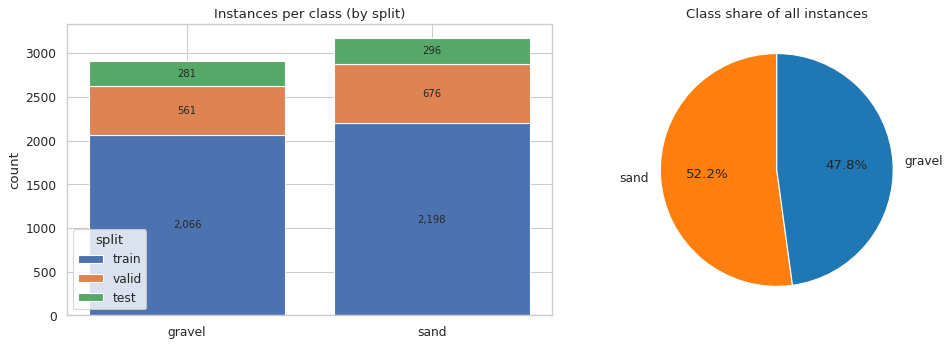

In [4]:
# ============================================================
# 2.2 CLASS DISTRIBUTION
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# (a) instance count per class, stacked by split
ct = df.groupby(["class", "split"]).size().unstack(fill_value=0)[SPLITS]
bottom = np.zeros(len(ct))
for split in SPLITS:
    axes[0].bar(ct.index, ct[split], bottom=bottom, label=split)
    for i, v in enumerate(ct[split]):
        if v:
            axes[0].text(i, bottom[i] + v / 2, f"{v:,}", ha="center", va="center", fontsize=9)
    bottom += ct[split].values
axes[0].set(title="Instances per class (by split)", ylabel="count")
axes[0].legend(title="split")

# (b) share of total — pie shows the imbalance at a glance
totals = df["class"].value_counts()
axes[1].pie(totals, labels=totals.index, autopct="%1.1f%%", startangle=90,
            colors=[CLASS_COLORS[c] for c in totals.index])
axes[1].set_title("Class share of all instances")

plt.tight_layout()
plt.show()

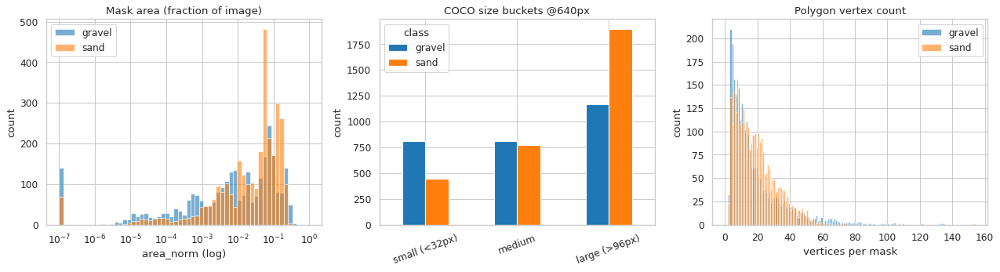

         count     mean      std  min      25%      50%      75%      max
class                                                                    
gravel  2908.0  0.04510  0.06714  0.0  0.00086  0.00922  0.06777  0.38223
sand    3170.0  0.05811  0.05863  0.0  0.00596  0.04718  0.09084  0.28432

Zero / near-zero area masks: 209


In [5]:
# ============================================================
# 2.3 POLYGON SIZE — mask area, COCO size buckets, vertex count
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# (a) mask area as fraction of image (log-x: areas span orders of magnitude)
for cls, g in df.groupby("class"):
    axes[0].hist(g["area_norm"].clip(1e-7), bins=np.logspace(-7, 0, 60),
                 alpha=0.6, label=cls, color=CLASS_COLORS[cls])
axes[0].set_xscale("log")
axes[0].set(title="Mask area (fraction of image)", xlabel="area_norm (log)", ylabel="count")
axes[0].legend()

# (b) COCO-style size buckets at 640x640 equivalent
#     small < 32^2 px, medium 32^2-96^2 px, large > 96^2 px
SIDE = 640
bucket = pd.cut(df["area_norm"] * SIDE**2,
                bins=[0, 32**2, 96**2, np.inf],
                labels=["small (<32px)", "medium", "large (>96px)"])
buckets = df.assign(size_bucket=bucket).groupby(["class", "size_bucket"], observed=True).size().unstack(fill_value=0)
bt = buckets.T
bt.plot(kind="bar", ax=axes[1], color=[CLASS_COLORS[c] for c in bt.columns])
axes[1].set(title="COCO size buckets @640px", xlabel="", ylabel="count")
axes[1].tick_params(axis="x", rotation=20)
axes[1].legend(title="class")

# (c) polygon vertex count — annotation granularity / quality proxy
for cls, g in df.groupby("class"):
    axes[2].hist(g["n_vertices"], bins=range(0, int(df["n_vertices"].max()) + 2),
                 alpha=0.6, label=cls, color=CLASS_COLORS[cls])
axes[2].set(title="Polygon vertex count", xlabel="vertices per mask", ylabel="count")
axes[2].legend()

plt.tight_layout()
plt.show()

print(df.groupby("class")["area_norm"].describe().round(5))
print("\nZero / near-zero area masks:", int((df["area_norm"] < 1e-6).sum()))

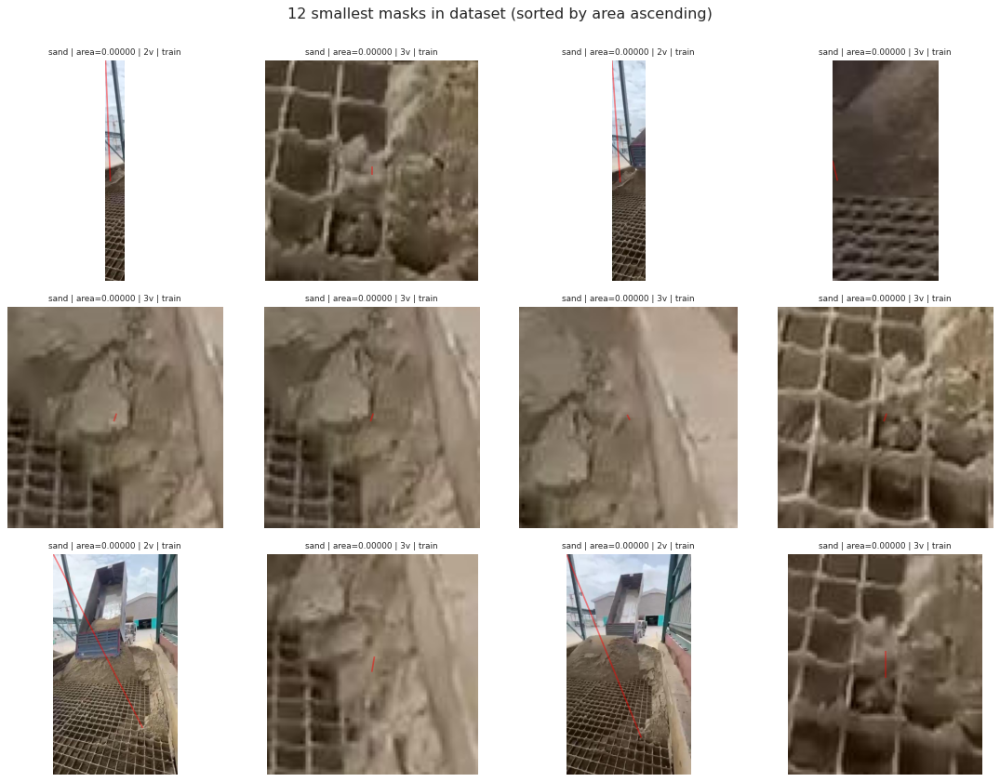

split                                                                                     image class  area_norm  n_vertices
train 0a48349e-f671-436a-8af5-de54f079109f_mp4-0002_jpg.rf.971195cad50e6197c6ad57dfa4044a80.jpg  sand        0.0           2
train 0a48349e-f671-436a-8af5-de54f079109f_mp4-0005_jpg.rf.186030c1b8d6e1044f24df2050ed52f6.jpg  sand        0.0           3
train 0a48349e-f671-436a-8af5-de54f079109f_mp4-0006_jpg.rf.7c4e859a2535edae8fd4092d40b5feb4.jpg  sand        0.0           2
train 0a48349e-f671-436a-8af5-de54f079109f_mp4-0013_jpg.rf.3e973f61e81eb803b3b353f5327e6975.jpg  sand        0.0           3
train 0a48349e-f671-436a-8af5-de54f079109f_mp4-0015_jpg.rf.d38ce010f9c0d0b35c69a2bf310dce07.jpg  sand        0.0           3
train 0a48349e-f671-436a-8af5-de54f079109f_mp4-0015_jpg.rf.d38ce010f9c0d0b35c69a2bf310dce07.jpg  sand        0.0           3
train 0a48349e-f671-436a-8af5-de54f079109f_mp4-0015_jpg.rf.d38ce010f9c0d0b35c69a2bf310dce07.jpg  sand        0.0           3


In [6]:
# ============================================================
# 2.3b SMALLEST MASKS — crop-zoom on the tiniest polygons
#     (are they real grains or annotation noise?)
# ============================================================

N_SHOW = 12          # how many of the smallest masks to show
PAD_FACTOR = 3.0     # crop window = mask bbox * this factor (context around it)

smallest = df.nsmallest(N_SHOW, "area_norm")
ncols = 4
nrows = int(np.ceil(N_SHOW / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(14, 3.5 * nrows))

for ax, (_, r) in zip(axes.flat, smallest.iterrows()):
    img = np.asarray(Image.open(DATASET_DIR / r["split"] / "images" / r["image"]))
    h, w = img.shape[:2]
    poly_px = r["poly"] * [w, h]

    x0, y0 = poly_px[:, 0].min(), poly_px[:, 1].min()
    x1, y1 = poly_px[:, 0].max(), poly_px[:, 1].max()
    pad_x = max((x1 - x0) * PAD_FACTOR, 40)   # >=40px context each way
    pad_y = max((y1 - y0) * PAD_FACTOR, 40)
    cx0, cx1 = int(max(0, x0 - pad_x)), int(min(w, x1 + pad_x))
    cy0, cy1 = int(max(0, y0 - pad_y)), int(min(h, y1 + pad_y))

    ax.imshow(img[cy0:cy1, cx0:cx1], extent=[cx0, cx1, cy1, cy0])
    ax.add_patch(MplPolygon(poly_px, closed=True, fill=True, alpha=0.45,
                            facecolor=CLASS_COLORS[r["class"]],
                            edgecolor="red", linewidth=1.5))
    ax.set_xlim(cx0, cx1); ax.set_ylim(cy1, cy0)
    ax.set_title(f'{r["class"]} | area={r["area_norm"]:.5f} | '
                 f'{r["n_vertices"]}v | {r["split"]}', fontsize=8)
    ax.axis("off")

for ax in axes.flat[N_SHOW:]:
    ax.axis("off")

plt.suptitle(f"{N_SHOW} smallest masks in dataset (sorted by area ascending)", y=1.0)
plt.tight_layout()
plt.show()

print(smallest[["split", "image", "class", "area_norm", "n_vertices"]]
      .to_string(index=False))

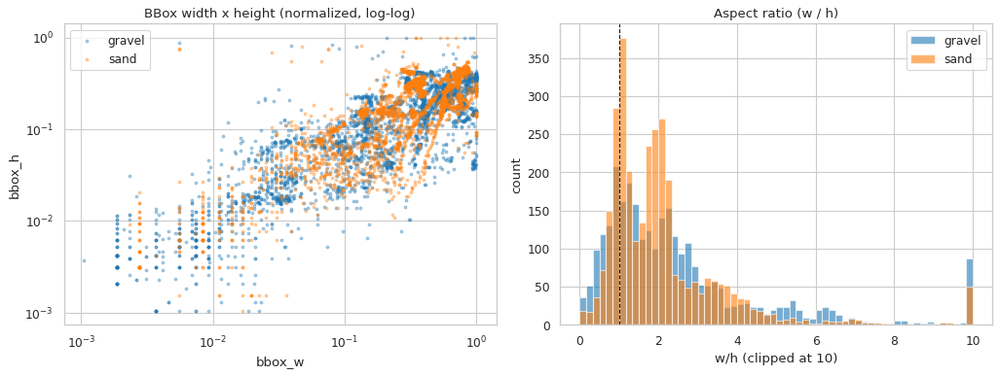

Aspect ratio > 4 (very elongated): 758
Aspect ratio < 0.25 (very tall):   78


In [7]:
# ============================================================
# 2.4 BBOX GEOMETRY — width x height scatter + aspect ratio
#     (the classic YOLO "labels" plot)
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for cls, g in df.groupby("class"):
    axes[0].scatter(g["bbox_w"], g["bbox_h"], s=6, alpha=0.35,
                    label=cls, color=CLASS_COLORS[cls])
axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set(title="BBox width x height (normalized, log-log)",
            xlabel="bbox_w", ylabel="bbox_h")
axes[0].legend()

for cls, g in df.groupby("class"):
    axes[1].hist(g["aspect"].clip(upper=10), bins=60, alpha=0.6,
                 label=cls, color=CLASS_COLORS[cls])
axes[1].axvline(1.0, color="k", ls="--", lw=1)
axes[1].set(title="Aspect ratio (w / h)", xlabel="w/h (clipped at 10)", ylabel="count")
axes[1].legend()

plt.tight_layout()
plt.show()

print("Aspect ratio > 4 (very elongated):", int((df["aspect"] > 4).sum()))
print("Aspect ratio < 0.25 (very tall):  ", int((df["aspect"] < 0.25).sum()))

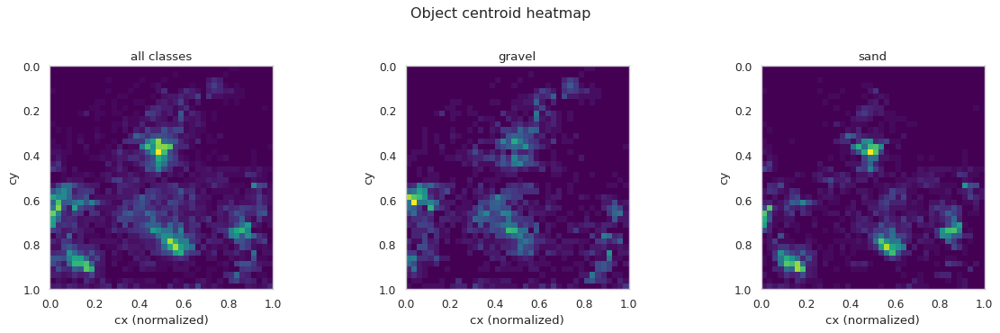

In [8]:
# ============================================================
# 2.5 SPATIAL DISTRIBUTION — where centroids sit in the image
# ============================================================

fig, axes = plt.subplots(1, len(CLASS_NAMES) + 1, figsize=(5 * (len(CLASS_NAMES) + 1), 4.5))

axes[0].hist2d(df["cx"], df["cy"], bins=40, range=[[0, 1], [0, 1]], cmap="viridis")
axes[0].set_title("all classes")

for ax, (cls, g) in zip(axes[1:], df.groupby("class")):
    ax.hist2d(g["cx"], g["cy"], bins=40, range=[[0, 1], [0, 1]], cmap="viridis")
    ax.set_title(cls)

for ax in axes:
    ax.set(xlabel="cx (normalized)", ylabel="cy", aspect="equal")
    ax.invert_yaxis()  # image coords: y=0 at top

plt.suptitle("Object centroid heatmap", y=1.02)
plt.tight_layout()
plt.show()

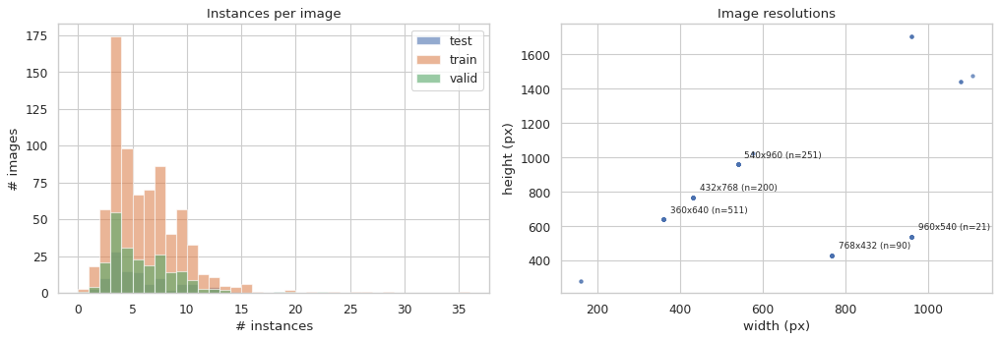

Images with ZERO instances: 5
img_w  img_h
360    640      511
540    960      251
432    768      200
768    432       90
960    540       21
       1706       5
1080   1440       4
160    284        3
576    1024       2
1108   1477       2
dtype: int64


In [9]:
# ============================================================
# 2.6 PER-IMAGE STATS — instances per image + image resolutions
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for split, g in df_imgs.groupby("split"):
    axes[0].hist(g["n_instances"], bins=range(0, int(df_imgs["n_instances"].max()) + 2),
                 alpha=0.6, label=split)
axes[0].set(title="Instances per image", xlabel="# instances", ylabel="# images")
axes[0].legend()

axes[1].scatter(df_imgs["img_w"], df_imgs["img_h"], s=8, alpha=0.4)
axes[1].set(title="Image resolutions", xlabel="width (px)", ylabel="height (px)")
for (w, h), n in df_imgs.groupby(["img_w", "img_h"]).size().nlargest(5).items():
    axes[1].annotate(f"{w}x{h} (n={n})", (w, h), textcoords="offset points",
                     xytext=(6, 6), fontsize=8)

plt.tight_layout()
plt.show()

print("Images with ZERO instances:", int((df_imgs["n_instances"] == 0).sum()))
print(df_imgs.groupby(["img_w", "img_h"]).size().sort_values(ascending=False).head(10))

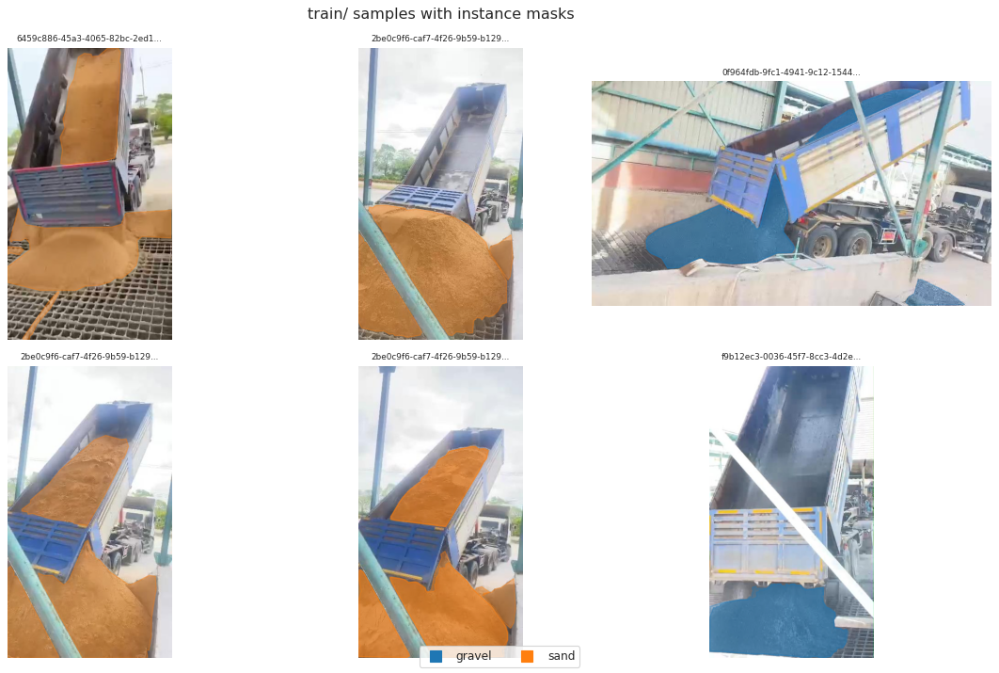

In [10]:
# ============================================================
# 2.7 SAMPLE INSPECTION — images with polygon overlays
# ============================================================

N_SHOW = 6
sample = (df_imgs[df_imgs["split"] == "train"]
          .sample(N_SHOW, random_state=42))

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (_, row) in zip(axes.flat, sample.iterrows()):
    img = np.asarray(Image.open(DATASET_DIR / "train" / "images" / row["image"]))
    h, w = img.shape[:2]
    ax.imshow(img)
    for line in (DATASET_DIR / "train" / "labels" / (Path(row["image"]).stem + ".txt")
                 ).read_text().splitlines():
        parts = line.split()
        cls = CLASS_NAMES[int(parts[0])]
        coords = np.array(list(map(float, parts[1:]))).reshape(-1, 2) * [w, h]
        ax.add_patch(MplPolygon(coords, closed=True, fill=True, alpha=0.35,
                                facecolor=CLASS_COLORS[cls],
                                edgecolor=CLASS_COLORS[cls], linewidth=1.2))
    ax.set_title(row["image"][:28] + "...", fontsize=8)
    ax.axis("off")

handles = [plt.Line2D([0], [0], marker="s", ls="", markersize=10,
                      color=CLASS_COLORS[c], label=c) for c in CLASS_NAMES]
fig.legend(handles=handles, loc="lower center", ncol=len(CLASS_NAMES))
plt.suptitle("train/ samples with instance masks")
plt.tight_layout()
plt.show()

In [11]:
# ============================================================
# 2.8 CLEANING FLAGS — auto-detected issues to fix before training
# ============================================================

flags = {
    "zero/near-zero area masks (degenerate)": df["area_norm"] < 1e-6,
    "tiny masks (<0.1% of image)":          df["area_norm"] < 0.001,
    "huge masks (>50% of image)":           df["area_norm"] > 0.5,
    "very elongated (aspect>4 or <0.25)":   (df["aspect"] > 4) | (df["aspect"] < 0.25),
    "very few vertices (<5, coarse mask)":  df["n_vertices"] < 5,
    "centroid outside image bounds":        (df["cx"] < 0) | (df["cx"] > 1) |
                                          (df["cy"] < 0) | (df["cy"] > 1),
}
flag_report = pd.DataFrame(
    {k: [int(v.sum()), f"{v.mean() * 100:.2f}%"] for k, v in flags.items()},
    index=["count", "pct_of_instances"],
).T
display(flag_report)

unlabeled = df_imgs[df_imgs["n_instances"] == 0]
print(f"Images with no labels: {len(unlabeled)}")
if len(unlabeled):
    display(unlabeled[["split", "image"]].head(20))

# per-image listing of the worst offenders for manual review
bad_idx = flags["zero/near-zero area masks (degenerate)"] | flags["tiny masks (<0.1% of image)"]
worst = df[bad_idx].groupby(["split", "image"]).size().sort_values(ascending=False)
print("\nImages containing degenerate/tiny masks:")
display(worst.head(20))

,count,pct_of_instances
zero/near-zero area masks (degenerate),209,3.44%
tiny masks (<0.1% of image),1085,17.85%
huge masks (>50% of image),0,0.00%
very elongated (aspect>4 or <0.25),836,13.75%
"very few vertices (<5, coarse mask)",705,11.60%
centroid outside image bounds,0,0.00%


Images with no labels: 5


,split,image
244,train,2be0c9f6-caf7-4f26-9b59-b1299865a721_mp4-0035_...
592,train,96ecd4fe-5910-4cd4-8a24-11ed20aab3b7_mp4-0060_...
594,train,96ecd4fe-5910-4cd4-8a24-11ed20aab3b7_mp4-0063_...
925,valid,96ecd4fe-5910-4cd4-8a24-11ed20aab3b7_mp4-0059_...
1063,test,96ecd4fe-5910-4cd4-8a24-11ed20aab3b7_mp4-0027_...



Images containing degenerate/tiny masks:


split  image                                                                                    
train  9056e676-f14d-410c-9dc7-c5686b3fca04_jpg.rf.6fc669c89bf6cb1267ccf00e86958e00.jpg             21
       b029e315-2e53-4152-a536-1adea99e32f7_mp4-0011_jpg.rf.34d70b2b31c437706f543b913d4782e9.jpg    19
       6f40fbbd-891e-434b-a1ec-365668a5ae66_mp4-0037_jpg.rf.ced76ca9b54ca7e4a8c44b7eff4f569d.jpg    15
       6f40fbbd-891e-434b-a1ec-365668a5ae66_mp4-0040_jpg.rf.5383ffa84007b489fff44eef2f5a8f25.jpg    15
       c6f16e4e-55cb-4abc-91ea-0d01ae0d6d28_jpg.rf.c194075dea18c914988161f0f09163d6.jpg             14
       6f40fbbd-891e-434b-a1ec-365668a5ae66_mp4-0044_jpg.rf.c83f54d20d9163951235283fc9ca78ac.jpg    12
test   2be0c9f6-caf7-4f26-9b59-b1299865a721_mp4-0077_jpg.rf.d9e774746ceecd84835688eccb8151ff.jpg    11
train  b029e315-2e53-4152-a536-1adea99e32f7_mp4-0015_jpg.rf.0c0bbfc5cd727794a3cd6709cb8c5132.jpg    11
test   8f435cb5-02c7-452a-a971-cef315681c19_mp4-0009_jpg.rf.ac7886e44ba21347e97

## 3. วิเคราะห์การซ้อนทับและรวม annotation ซ้ำ

Roboflow auto-labeling วาง polygon 2–5 รูปบนวัตถุเดียวกัน แนวทางจาก FiftyOne duplicate-annotation และ mask-NMS:

- ตรวจ **การซ้อนทับของ mask เป็นคู่ภายในภาพเดียวกัน** โดยเริ่มจากคลาสเดียวกัน
- **IoU** = intersection / union ใช้ตรวจรูปซ้ำที่ขนาดใกล้กัน; **IoMin** = intersection / พื้นที่รูปที่เล็กกว่า ใช้ตรวจรูปซ้อนอยู่ภายในอีกรูป
- จัดกลุ่ม polygon ด้วย union-find แล้วรวมด้วย `shapely.unary_union`

ส่วนนี้ **แสดงภาพ** โครงสร้าง overlap เท่านั้น ยังไม่แก้ label ลำดับ cleaning ที่เลือกหลังดูกราฟ:
1. ตัด mask เสื่อมสภาพและ noise เล็กมากก่อน เพื่อไม่ให้รวมกับ mask จริง
2. จัดกลุ่มและรวมรูปซ้ำที่เหลือ
3. เขียน label ที่ทำความสะอาดไป `data/silver/`

In [12]:
# ============================================================
# 3.1 OVERLAP DETECTION — pairwise mask IoU & IoMin per image
# ============================================================
# IoU   = intersection / union        -> catches equal-size duplicates
# IoMin = intersection / min(area)    -> catches nested duplicates (1 inside another)
# same_class flag separates "stacked autolabel duplicates" from
# genuine gravel-vs-sand neighbours that just touch.

import importlib.util
if importlib.util.find_spec('shapely') is None: raise RuntimeError('Polygon review requires shapely in this notebook kernel.')

from itertools import combinations
from shapely.geometry import Polygon
from shapely.validation import make_valid

def to_geom(poly):
    """Shapely geometry from normalized coords.
    Degenerate masks (<3 points) and invalid rings -> empty geometry
    (area 0, never overlaps) so they can't poison the overlap graph."""
    try:
        if len(poly) < 3:
            return Polygon()
        g = Polygon(poly)
        return g if g.is_valid else make_valid(g)
    except Exception:
        return Polygon()

GEOMS = {i: to_geom(r["poly"]) for i, r in df.iterrows()}

pairs = []
for (split, img), gdf in df.groupby(["split", "image"]):
    idxs = gdf.index.tolist()
    for a, b in combinations(idxs, 2):
        ga, gb = GEOMS[a], GEOMS[b]
        if ga.is_empty or gb.is_empty:
            continue
        # cheap bbox reject before expensive intersection
        if ga.bounds[2] < gb.bounds[0] or gb.bounds[2] < ga.bounds[0] or \
           ga.bounds[3] < gb.bounds[1] or gb.bounds[3] < ga.bounds[1]:
            continue
        inter = ga.intersection(gb).area
        min_a = min(ga.area, gb.area)
        if inter <= 0 or min_a <= 0:
            continue
        iou = inter / ga.union(gb).area
        iomin = inter / min_a
        pairs.append({
            "split": split, "image": img,
            "i": a, "j": b,
            "class_i": df.at[a, "class"], "class_j": df.at[b, "class"],
            "same_class": df.at[a, "class_id"] == df.at[b, "class_id"],
            "iou": iou, "iomin": iomin, "inter": inter,
        })

df_ov = pd.DataFrame(pairs)
print(f"Overlapping pairs found: {len(df_ov):,}")
if len(df_ov):
    print(df_ov.groupby("same_class")[["iou", "iomin"]].describe().round(3))

Overlapping pairs found: 2,089
               iou                                                 iomin  \
             count   mean   std  min    25%    50%    75%    max   count   
same_class                                                                 
True        2089.0  0.493  0.42  0.0  0.004  0.499  0.953  0.998  2089.0   

                                                        
             mean   std  min    25%    50%    75%  max  
same_class                                              
True        0.808  0.37  0.0  0.965  0.994  0.999  1.0  


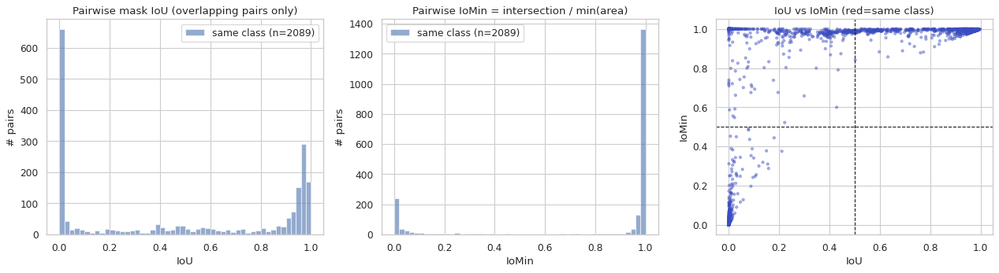

Same-class pairs above threshold:
  iou > 0.3: 1222
  iou > 0.5: 1044
  iou > 0.7: 894
  iou > 0.9: 736
  iomin > 0.3: 1711
  iomin > 0.5: 1689
  iomin > 0.7: 1678
  iomin > 0.9: 1640


In [13]:
# ============================================================
# 3.2 OVERLAP SCORE DISTRIBUTION — pick the merge threshold
# ============================================================
# Look for the elbow: autolabel duplicates cluster at high IoMin,
# real touching neighbours sit at low overlap.

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for same, g in df_ov.groupby("same_class"):
    lbl = "same class" if same else "cross class"
    axes[0].hist(g["iou"], bins=np.linspace(0, 1, 51), alpha=0.6,
                 label=f"{lbl} (n={len(g)})")
axes[0].set(title="Pairwise mask IoU (overlapping pairs only)",
            xlabel="IoU", ylabel="# pairs")
axes[0].legend()

for same, g in df_ov.groupby("same_class"):
    lbl = "same class" if same else "cross class"
    axes[1].hist(g["iomin"], bins=np.linspace(0, 1, 51), alpha=0.6,
                 label=f"{lbl} (n={len(g)})")
axes[1].set(title="Pairwise IoMin = intersection / min(area)",
            xlabel="IoMin", ylabel="# pairs")
axes[1].legend()

sc = axes[2].scatter(df_ov["iou"], df_ov["iomin"],
                     c=df_ov["same_class"], cmap="coolwarm", s=8, alpha=0.4)
axes[2].set(title="IoU vs IoMin (red=same class)", xlabel="IoU", ylabel="IoMin")
axes[2].axvline(0.5, color="k", ls="--", lw=1)
axes[2].axhline(0.5, color="k", ls="--", lw=1)

plt.tight_layout()
plt.show()

# candidate duplicate counts at common thresholds (same-class pairs)
print("Same-class pairs above threshold:")
for m in ["iou", "iomin"]:
    for t in (0.3, 0.5, 0.7, 0.9):
        n = int(((df_ov["same_class"]) & (df_ov[m] > t)).sum())
        print(f"  {m} > {t}: {n}")

Rule: iomin >= 0.5, same_class=True
Clusters: 932 | instances involved: 2356
Cluster size histogram: {2: 667, 3: 164, 4: 41, 5: 34, 6: 8, 7: 9, 8: 4, 9: 2, 10: 1, 12: 1, 13: 1}


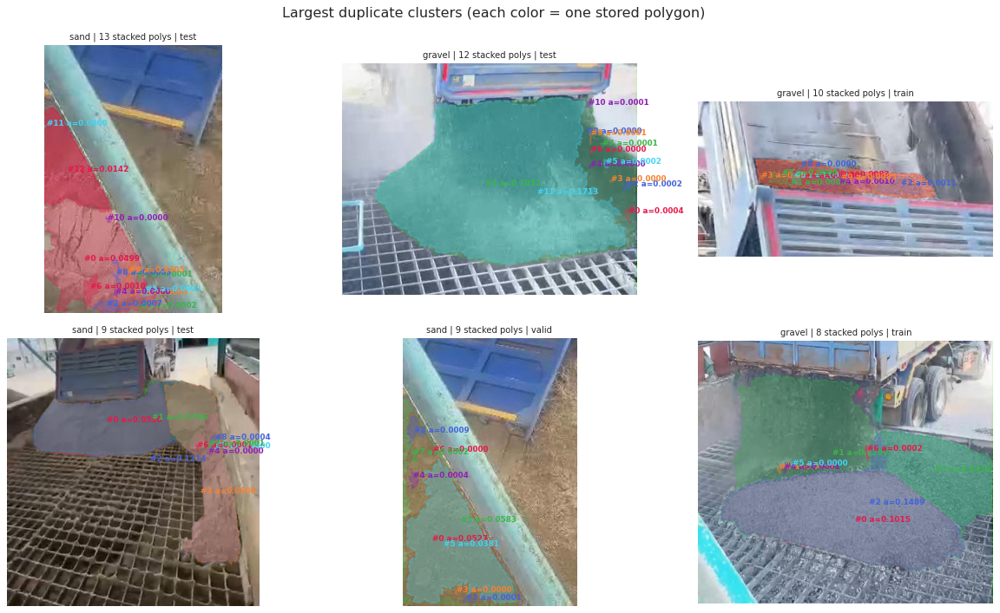

In [14]:
# ============================================================
# 3.3 OVERLAP CLUSTERS — union-find grouping + visual check
# ============================================================
# Provisional rule for VISUALIZATION ONLY: same-class pair with
# IoMin >= 0.5 links two masks -> connected components = candidate
# duplicate clusters (one physical object, 2-5 stacked polygons).

CLUSTER_METRIC = "iomin"   # "iou" or "iomin"
CLUSTER_THR    = 0.5
SAME_CLASS_ONLY = True

def union_find_clusters(edge_df):
    parent = {}
    def find(x):
        parent.setdefault(x, x)
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x
    for _, r in edge_df.iterrows():
        pa, pb = find(r["i"]), find(r["j"])
        if pa != pb:
            parent[pa] = pb
    clusters = {}
    for x in parent:
        clusters.setdefault(find(x), []).append(x)
    return [c for c in clusters.values() if len(c) > 1]

edges = df_ov[df_ov[CLUSTER_METRIC] >= CLUSTER_THR]
if SAME_CLASS_ONLY:
    edges = edges[edges["same_class"]]
clusters = union_find_clusters(edges)
clusters.sort(key=len, reverse=True)

print(f"Rule: {CLUSTER_METRIC} >= {CLUSTER_THR}, same_class={SAME_CLASS_ONLY}")
print(f"Clusters: {len(clusters)} | instances involved: {sum(len(c) for c in clusters)}")
print("Cluster size histogram:", pd.Series([len(c) for c in clusters]).value_counts().sort_index().to_dict())

# ---- visualize the biggest clusters -------------------------------
N_CLUSTERS = min(6, len(clusters))
MEMBER_COLORS = ["#e6194b", "#3cb44b", "#4363d8", "#f58231", "#911eb4", "#42d4f4"]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, members in zip(axes.flat, clusters[:N_CLUSTERS]):
    r0 = df.loc[members[0]]
    img = np.asarray(Image.open(DATASET_DIR / r0["split"] / "images" / r0["image"]))
    h, w = img.shape[:2]

    polys_px = [df.at[m, "poly"] * [w, h] for m in members]
    all_x = np.concatenate([p[:, 0] for p in polys_px])
    all_y = np.concatenate([p[:, 1] for p in polys_px])
    pad = 60
    cx0, cx1 = int(max(0, all_x.min() - pad)), int(min(w, all_x.max() + pad))
    cy0, cy1 = int(max(0, all_y.min() - pad)), int(min(h, all_y.max() + pad))

    ax.imshow(img[cy0:cy1, cx0:cx1], extent=[cx0, cx1, cy1, cy0])
    for k, (m, ppx) in enumerate(zip(members, polys_px)):
        ax.add_patch(MplPolygon(ppx, closed=True, fill=True, alpha=0.3,
                                facecolor=MEMBER_COLORS[k % len(MEMBER_COLORS)],
                                edgecolor=MEMBER_COLORS[k % len(MEMBER_COLORS)],
                                linewidth=1.8, linestyle="--"))
        ax.annotate(f"#{k} a={df.at[m,'area_norm']:.4f}",
                    (ppx[:, 0].mean(), ppx[:, 1].mean()),
                    fontsize=8, color=MEMBER_COLORS[k % len(MEMBER_COLORS)],
                    fontweight="bold")
    ax.set_xlim(cx0, cx1); ax.set_ylim(cy1, cy0)
    ax.set_title(f"{r0['class']} | {len(members)} stacked polys | {r0['split']}", fontsize=9)
    ax.axis("off")

for ax in axes.flat[N_CLUSTERS:]:
    ax.axis("off")
plt.suptitle("Largest duplicate clusters (each color = one stored polygon)")
plt.tight_layout()
plt.show()

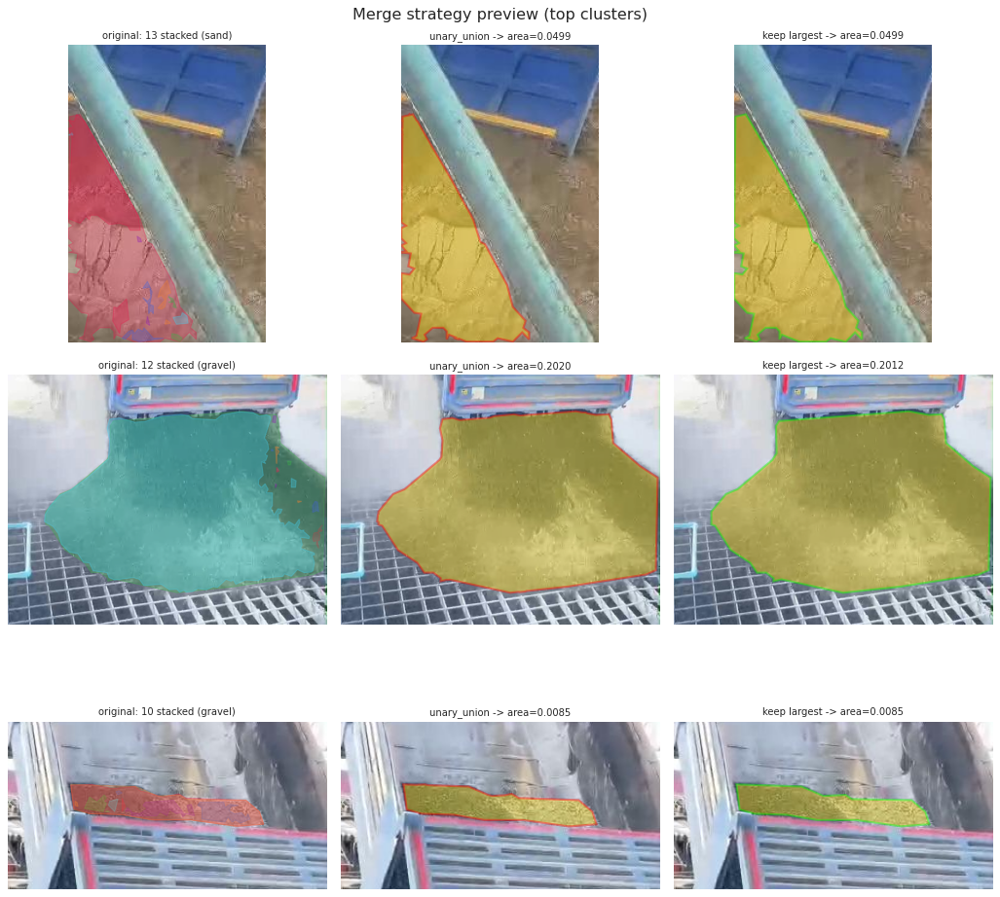

In [15]:
# ============================================================
# 3.4 MERGE STRATEGY PREVIEW — union vs keep-largest vs keep-all
# ============================================================
# For each top cluster, compare what "1 polygon" would look like:
#   (a) original stacked polys  (b) unary_union outline  (c) largest only
# union    -> preserves full extent, may "grow" the mask
# largest  -> tightest, discards extra coverage from smaller dupes

from shapely.ops import unary_union

N_PREVIEW = min(3, len(clusters))
fig, axes = plt.subplots(N_PREVIEW, 3, figsize=(13, 4.2 * N_PREVIEW))
if N_PREVIEW == 1:
    axes = axes[None, :]

for row, members in enumerate(clusters[:N_PREVIEW]):
    r0 = df.loc[members[0]]
    img = np.asarray(Image.open(DATASET_DIR / r0["split"] / "images" / r0["image"]))
    h, w = img.shape[:2]

    geoms = [GEOMS[m] for m in members]
    union_g = unary_union(geoms)
    if union_g.geom_type == "MultiPolygon":
        union_g = max(union_g.geoms, key=lambda g: g.area)
    biggest_m = max(members, key=lambda m: df.at[m, "area_norm"])

    bx0 = min(g.bounds[0] for g in geoms); by0 = min(g.bounds[1] for g in geoms)
    bx1 = max(g.bounds[2] for g in geoms); by1 = max(g.bounds[3] for g in geoms)
    pad = 60
    cx0, cx1 = int(max(0, bx0 * w - pad)), int(min(w, bx1 * w + pad))
    cy0, cy1 = int(max(0, by0 * h - pad)), int(min(h, by1 * h + pad))

    def setup(ax, title):
        ax.imshow(img[cy0:cy1, cx0:cx1], extent=[cx0, cx1, cy1, cy0])
        ax.set_xlim(cx0, cx1); ax.set_ylim(cy1, cy0)
        ax.set_title(title, fontsize=9); ax.axis("off")

    # (a) originals
    setup(axes[row, 0], f"original: {len(members)} stacked ({r0['class']})")
    for k, m in enumerate(members):
        axes[row, 0].add_patch(MplPolygon(
            df.at[m, "poly"] * [w, h], closed=True, fill=True, alpha=0.3,
            facecolor=MEMBER_COLORS[k % 6], edgecolor=MEMBER_COLORS[k % 6]))

    # (b) union
    setup(axes[row, 1], f"unary_union -> area={union_g.area:.4f}")
    ux, uy = union_g.exterior.xy
    axes[row, 1].add_patch(MplPolygon(
        np.c_[np.array(ux) * w, np.array(uy) * h], closed=True, fill=True,
        alpha=0.4, facecolor="gold", edgecolor="red", linewidth=2))

    # (c) keep largest
    setup(axes[row, 2], f"keep largest -> area={df.at[biggest_m,'area_norm']:.4f}")
    axes[row, 2].add_patch(MplPolygon(
        df.at[biggest_m, "poly"] * [w, h], closed=True, fill=True,
        alpha=0.4, facecolor="gold", edgecolor="lime", linewidth=2))

plt.suptitle("Merge strategy preview (top clusters)")
plt.tight_layout()
plt.show()

valid tiny masks (<0.001 of image): 876
  inside duplicate clusters (will merge into big mask): 303
  standalone (drop = lose them entirely):               573

by class:
class
gravel    463
sand      110
dtype: int64


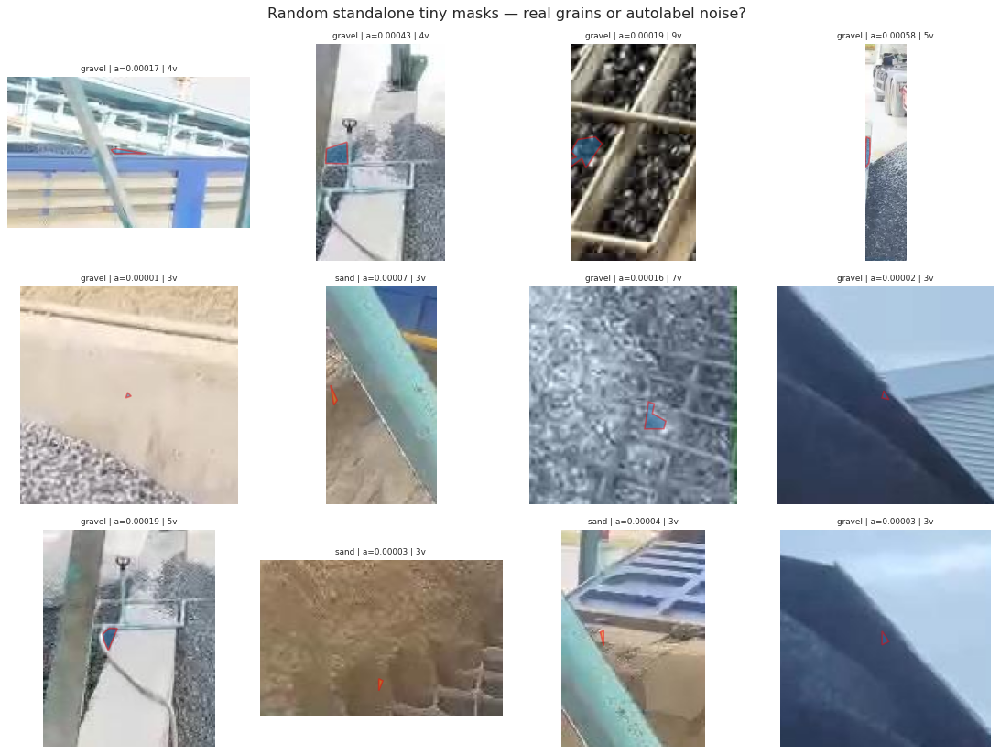

In [16]:
# ============================================================
# 3.5 TINY MASKS IN CONTEXT — standalone noise vs real small grains
# ============================================================
# Decide the tiny-mask rule from evidence:
#   - tiny AND inside a duplicate cluster -> merges into the big mask anyway
#   - tiny AND standalone                 -> candidate noise, needs eyeball check

MIN_AREA = 0.001   # 0.1% of image — same threshold as the 2.8 flag

is_deg = ((df["n_vertices"] < 3)
          | (df["area_norm"] <= 1e-9)
          | pd.Series([GEOMS[i].is_empty for i in df.index], index=df.index))
tiny_valid = (~is_deg) & (df["area_norm"] < MIN_AREA)
clustered_idx = {m for c in clusters for m in c}
tiny_in_cluster = tiny_valid & df.index.isin(clustered_idx)
tiny_standalone = tiny_valid & ~df.index.isin(clustered_idx)

print(f"valid tiny masks (<{MIN_AREA} of image): {int(tiny_valid.sum())}")
print(f"  inside duplicate clusters (will merge into big mask): {int(tiny_in_cluster.sum())}")
print(f"  standalone (drop = lose them entirely):               {int(tiny_standalone.sum())}")
print("\nby class:")
print(df[tiny_standalone].groupby("class").size())

# ---- eyeball a random sample of standalone tiny masks ---------
N_SHOW = 12
rng = np.random.default_rng(7)
pool = df[tiny_standalone].sample(min(N_SHOW, int(tiny_standalone.sum())), random_state=7)

ncols = 4
nrows = int(np.ceil(len(pool) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(14, 3.5 * nrows))
axes = np.atleast_1d(axes).ravel()

for ax, (_, r) in zip(axes, pool.iterrows()):
    img = np.asarray(Image.open(DATASET_DIR / r["split"] / "images" / r["image"]))
    h, w = img.shape[:2]
    poly_px = np.asarray(r["poly"]) * [w, h]
    x0, y0, x1, y1 = poly_px[:,0].min(), poly_px[:,1].min(), poly_px[:,0].max(), poly_px[:,1].max()
    pad_x = max((x1 - x0) * 3.0, 60); pad_y = max((y1 - y0) * 3.0, 60)
    cx0, cx1 = int(max(0, x0 - pad_x)), int(min(w, x1 + pad_x))
    cy0, cy1 = int(max(0, y0 - pad_y)), int(min(h, y1 + pad_y))
    ax.imshow(img[cy0:cy1, cx0:cx1], extent=[cx0, cx1, cy1, cy0])
    ax.add_patch(MplPolygon(poly_px, closed=True, fill=True, alpha=0.45,
                            facecolor=CLASS_COLORS[r["class"]], edgecolor="red", lw=1.5))
    ax.set_xlim(cx0, cx1); ax.set_ylim(cy1, cy0)
    ax.set_title(f'{r["class"]} | a={r["area_norm"]:.5f} | {r["n_vertices"]}v', fontsize=8)
    ax.axis("off")
for ax in axes[len(pool):]:
    ax.axis("off")

plt.suptitle("Random standalone tiny masks — real grains or autolabel noise?")
plt.tight_layout()
plt.show()

images containing >=1 tiny mask : 359 / 1089
images containing >=5 tiny masks: 60

top 10 by tiny-mask count:
split  image                                                                                    
train  9056e676-f14d-410c-9dc7-c5686b3fca04_jpg.rf.6fc669c89bf6cb1267ccf00e86958e00.jpg             21
       c6f16e4e-55cb-4abc-91ea-0d01ae0d6d28_jpg.rf.c194075dea18c914988161f0f09163d6.jpg             14
test   2be0c9f6-caf7-4f26-9b59-b1299865a721_mp4-0077_jpg.rf.d9e774746ceecd84835688eccb8151ff.jpg    11
       8f435cb5-02c7-452a-a971-cef315681c19_mp4-0009_jpg.rf.ac7886e44ba21347e97826dc8afd6926.jpg    10
valid  d56fcb3c-0531-4696-8b67-2645d89e4a7f_mp4-0014_jpg.rf.60cd05dde1aedc87fe8b13c56d12b94f.jpg    10
train  b029e315-2e53-4152-a536-1adea99e32f7_mp4-0015_jpg.rf.0c0bbfc5cd727794a3cd6709cb8c5132.jpg     8
       6f40fbbd-891e-434b-a1ec-365668a5ae66_mp4-0040_jpg.rf.5383ffa84007b489fff44eef2f5a8f25.jpg     6
       8f435cb5-02c7-452a-a971-cef315681c19_mp4-0027_jpg.rf.51ce7156ca03

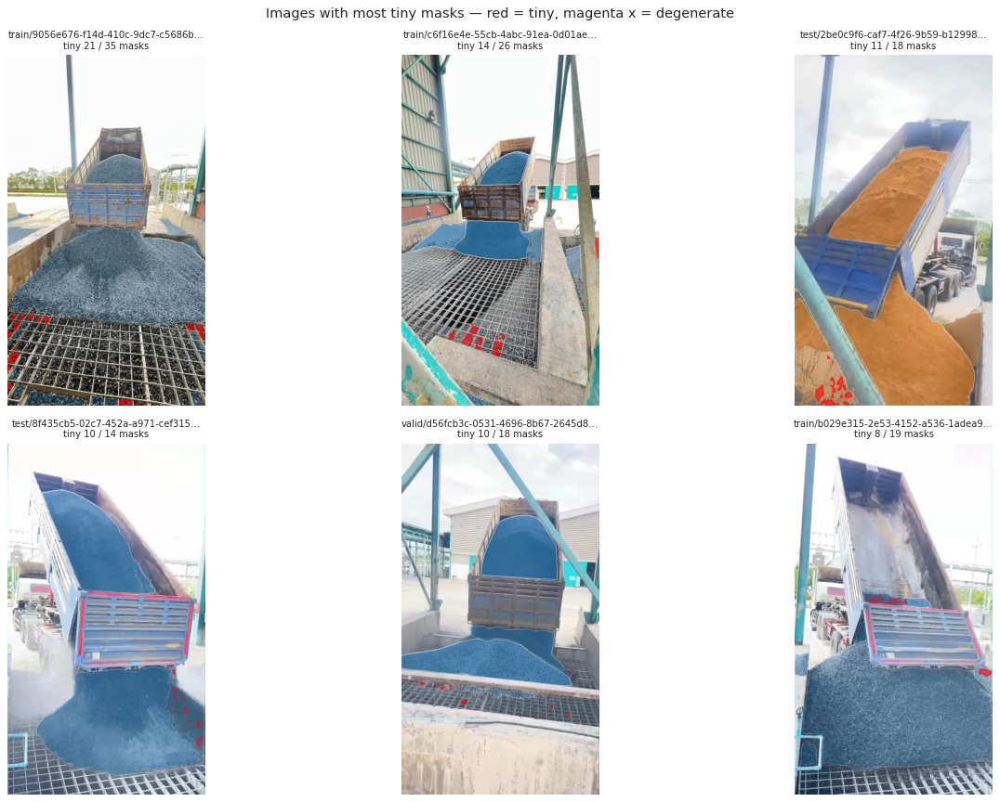

In [17]:
# ============================================================
# 3.6 NOISE HOTSPOTS — which images carry the most tiny masks
# ============================================================
# Uses `tiny_valid` / `is_deg` / `MIN_AREA` from cell 3.5.
# red fill = tiny mask (<MIN_AREA) | magenta x = degenerate point/line
# class color = normal mask

tiny_img = (df[tiny_valid].groupby(["split", "image"]).size()
            .sort_values(ascending=False))
print(f"images containing >=1 tiny mask : {(tiny_img > 0).sum()} / {len(df_imgs)}")
print(f"images containing >=5 tiny masks: {(tiny_img >= 5).sum()}")
print("\ntop 10 by tiny-mask count:")
print(tiny_img.head(10).to_string())

N_SHOW = 6
top = tiny_img.head(N_SHOW).index.tolist()
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
for ax, (split, img) in zip(axes.ravel(), top):
    im = np.asarray(Image.open(DATASET_DIR / split / "images" / img))
    h, w = im.shape[:2]
    ax.imshow(im)
    sub = df[(df["split"] == split) & (df["image"] == img)]
    n_t = 0
    for _, r in sub.iterrows():
        px = np.asarray(r["poly"]) * [w, h]
        if len(r["poly"]) < 3:
            ax.scatter(px[:, 0], px[:, 1], s=50, c="magenta", marker="x", lw=2)
            continue
        is_t = (not is_deg[r.name]) and r["area_norm"] < MIN_AREA
        n_t += is_t
        ax.add_patch(MplPolygon(px, closed=True, fill=True,
                                alpha=0.55 if is_t else 0.25,
                                facecolor="red" if is_t else CLASS_COLORS[r["class"]],
                                edgecolor="red" if is_t else "white",
                                lw=1.4 if is_t else 0.6))
    ax.set_title(f"{split}/{img[:30]}…\ntiny {n_t} / {len(sub)} masks", fontsize=9)
    ax.axis("off")
plt.suptitle("Images with most tiny masks — red = tiny, magenta x = degenerate", fontsize=13)
plt.tight_layout()
plt.show()

## 4. สูตร cleaning ในอดีต → `data/silver/`

สูตรเดิมเก็บรูปใหญ่ที่สุดใน connected component ของคลาสเดียวกันที่ IoMin≥0.5 แล้วลบ mask ที่เหลือซึ่งมีพื้นที่ต่ำกว่า 0.1% ของภาพ กฎนี้เป็น **heuristics ที่ทำซ้ำได้** ไม่ใช่การแก้ annotation ที่ผู้ตรวจอิสระยืนยันแล้ว กลุ่มที่เชื่อมต่อกันอาจรวมบริเวณจริงที่อยู่ติดกัน; การเก็บเฉพาะรูปใหญ่ที่สุดอาจทิ้งขอบเขตจริง และ mask เล็กอาจเป็นบริเวณวัสดุที่ถูกต้อง

ต้องรายงานจำนวนที่ถูกลบแยกคลาส/group และความไวต่อ threshold พื้นที่/overlap การดูตัวอย่างไม่ยืนยันทุกกรณี คิวผู้ตรวจต้องมีการตัดสิน accept/reject อย่างอิสระและ adjudication ก่อนอ้างว่า annotation ถูกต้อง โหมด audit ไม่เปลี่ยนชุดเดิม; cleaning เวอร์ชันใหม่เป็นการสำรวจที่ต้องตรวจแยก

In [18]:
# ============================================================
# 4.1 CLEAN — deduplicate + write labels to data/silver/
# ============================================================
# Order (locked):
#   1. drop degenerate  (n_vertices<3 | area=0 | invalid geom)
#   2. merge clusters   (same-class IoMin>=0.5, keep LARGEST)
#   3. drop tiny        (standalone survivors < TINY_THR — confirmed noise via 3.5)

import shutil
SILVER_DIR = EXP / 'data' / 'silver'
DROP_TINY = True
TINY_THR = 0.001

# ---------- 1. drop degenerate --------------------------------
deg = ((df['n_vertices'] < 3) | (df['area_norm'] <= 1e-9)
       | pd.Series([GEOMS[i].is_empty for i in df.index], index=df.index))
keep = ~deg
n_degenerate = int(deg.sum())

# ---------- 2. merge: keep largest member per cluster ---------
drop_merged = set()
for c in clusters:
    members = [m for m in c if keep[m]]
    if len(members) >= 2:
        biggest = max(members, key=lambda m: df.at[m, 'area_norm'])
        drop_merged.update(m for m in members if m != biggest)
keep.loc[list(drop_merged)] = False
n_merged_away = len(drop_merged)

# ---------- 3. drop standalone tiny ---------------------------
tiny = keep & (df['area_norm'] < TINY_THR) if DROP_TINY else pd.Series(False, index=df.index)
n_tiny = int(tiny.sum())
keep &= ~tiny
df_clean = df[keep].copy()

# ---------- 4. write silver ------------------------------------
if BUILD_DATASETS:
    SILVER_DIR = new_dataset_dir(EXP / 'data' / ('silver_' + STAMP))
    for split in SPLITS:
        (SILVER_DIR / split / 'images').mkdir(parents=True)
        (SILVER_DIR / split / 'labels').mkdir(parents=True)
    for _, r in df_imgs.iterrows():
        shutil.copy2(DATASET_DIR / r['split'] / 'images' / r['image'], SILVER_DIR / r['split'] / 'images' / r['image'])
    for (split, img), g in df_imgs.groupby(['split', 'image']):
        insts = df_clean[(df_clean['split'] == split) & (df_clean['image'] == img)]
        lines = [str(r['class_id']) + ' ' + ' '.join(f'{v:.6f}' for v in np.asarray(r['poly']).ravel()) for _, r in insts.iterrows()]
        (SILVER_DIR / split / 'labels' / (Path(img).stem + '.txt')).write_text('\n'.join(lines))
    (SILVER_DIR / 'data.yaml').write_text(f'path: {SILVER_DIR}\ntrain: train/images\nval: valid/images\ntest: test/images\nnames: {CLASS_NAMES}\n')
else:
    assert SILVER_DIR.is_dir(), 'Existing silver is required in audit mode.'

# ---------- cleaning report ------------------------------------
print('Proposed cleaning:', len(df), '->', len(df_clean), 'instances')
print('degenerate', n_degenerate, 'duplicates', n_merged_away, 'tiny', n_tiny)
emptied = df_imgs.merge(df_clean.groupby(['split','image']).size().rename('n').reset_index(), on=['split','image'], how='left').fillna({'n': 0})
print('Zero-label images:', int((emptied['n'] == 0).sum()), '| data writes enabled:', BUILD_DATASETS)
print('Tiny-removal correctness remains unverified until independent review.')

Proposed cleaning: 6078 -> 3861 instances
degenerate 209 duplicates 1424 tiny 584
Zero-label images: 5 | data writes enabled: False
Tiny-removal correctness remains unverified until independent review.


## 5. ตรวจสอบหลัง cleaning (`data/silver/`)

รัน audit เดิมซ้ำกับข้อมูลที่ทำความสะอาด เพื่อเช็กว่าการเปลี่ยนแปลงตรงตามกฎ:
1. **ความสมบูรณ์** — อ่าน label `silver` จากดิสก์ใหม่ ตรวจจำนวนจุดยอด ช่วงพิกัด class ID และคู่คลาสเดียวกันที่ยังมี IoMin≥0.5
2. **กราฟก่อน/หลัง** — จำนวน instances, สมดุลคลาส, การกระจายขนาด และ instances ต่อภาพ
3. **ภาพซ้อน audit** — เปรียบเทียบ polygon ที่เก็บกับที่ลบ เพื่อดูว่าข้อมูลใดหายไปจริง

In [19]:
# ============================================================
# 5.1 VALIDATE SILVER — re-parse written labels & check integrity
# ============================================================
rows = []
for _, r in df_imgs.iterrows():
    lt = SILVER_DIR / r["split"] / "labels" / (Path(r["image"]).stem + ".txt")
    for line in lt.read_text().splitlines():
        if not line.strip():
            continue
        parts = line.split()
        coords = np.array(parts[1:], dtype=float).reshape(-1, 2)
        rows.append({"split": r["split"], "image": r["image"],
                     "class_id": int(parts[0]),
                     "class": CLASS_NAMES[int(parts[0])], "poly": coords})
df_silver = pd.DataFrame(rows)
df_silver["n_vertices"] = df_silver["poly"].apply(len)
df_silver["area_norm"] = df_silver["poly"].apply(
    lambda p: Polygon(p).area if len(p) >= 3 else 0.0)

print(f"silver instances parsed from disk: {len(df_silver):,}  (expected {len(df_clean):,})")

checks = {
    "count matches df_clean":            len(df_silver) == len(df_clean),
    "all >= 3 vertices":                 bool((df_silver["n_vertices"] >= 3).all()),
    "coords within [0,1]":               bool(((df_silver["poly"].apply(lambda p: p.min()) >= -1e-6)
                                                & (df_silver["poly"].apply(lambda p: p.max()) <= 1 + 1e-6)).all()),
    "class ids in {0,1}":                df_silver["class_id"].isin([0, 1]).all(),
    "no zero-area masks left":           bool((df_silver["area_norm"] > 0).all()),
    "no tiny (<0.1%) masks left":        bool((df_silver["area_norm"] >= TINY_THR).all()),
}
for k, v in checks.items():
    print(f"  [{'PASS' if v else 'FAIL'}] {k}")

# residual duplicate check: any same-class IoMin>=0.5 pair left in silver?
silver_geoms = df_silver["poly"].apply(to_geom)
residual = 0
for (split, img), gdf in df_silver.groupby(["split", "image"]):
    idx = gdf.index.tolist()
    for a in range(len(idx)):
        ga = silver_geoms[idx[a]]
        for b in range(a + 1, len(idx)):
            gb = silver_geoms[idx[b]]
            if df_silver.at[idx[a], "class_id"] != df_silver.at[idx[b], "class_id"]:
                continue
            if not ga.intersects(gb):
                continue
            inter = ga.intersection(gb).area
            if inter > 0 and inter / min(ga.area, gb.area) >= CLUSTER_THR:
                residual += 1
print(f"  [{'PASS' if residual == 0 else 'FAIL'}] residual same-class IoMin>={CLUSTER_THR} pairs: {residual}")

silver instances parsed from disk: 3,861  (expected 3,861)
  [PASS] count matches df_clean
  [PASS] all >= 3 vertices
  [PASS] coords within [0,1]
  [PASS] class ids in {0,1}
  [PASS] no zero-area masks left
  [PASS] no tiny (<0.1%) masks left


  [PASS] residual same-class IoMin>=0.5 pairs: 0


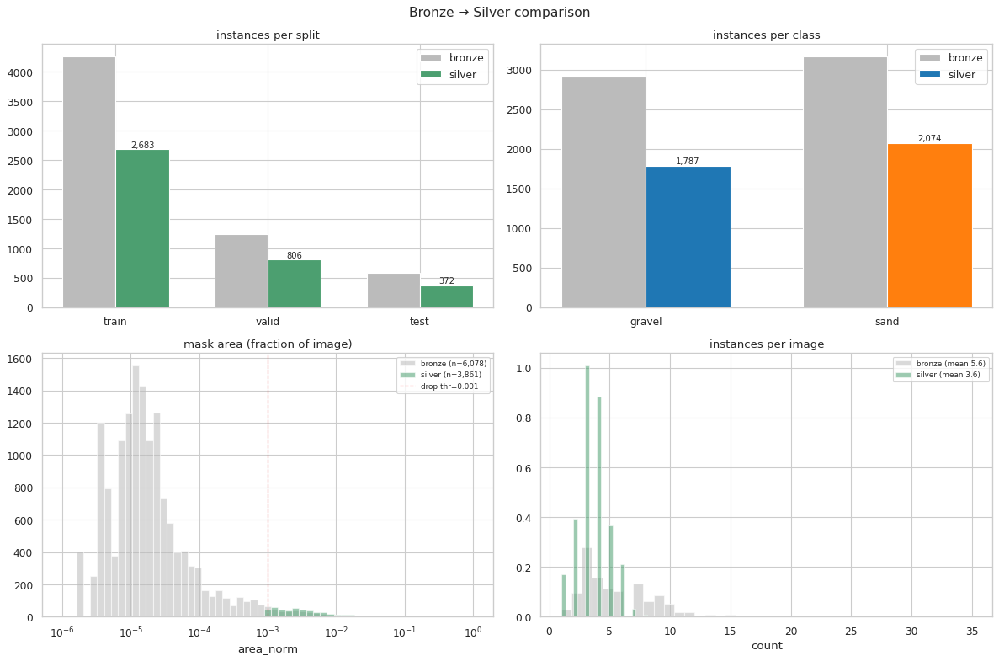

In [20]:
# ============================================================
# 5.2 BEFORE / AFTER — the same charts re-run on silver
# ============================================================
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# (a) instances per split: bronze vs silver
x = np.arange(len(SPLITS)); w = 0.35
b_counts = [len(df[df["split"] == s]) for s in SPLITS]
s_counts = [len(df_silver[df_silver["split"] == s]) for s in SPLITS]
axes[0, 0].bar(x - w/2, b_counts, w, label="bronze", color="#bbbbbb")
axes[0, 0].bar(x + w/2, s_counts, w, label="silver", color="#4c9f70")
for xi, (bv, sv) in enumerate(zip(b_counts, s_counts)):
    axes[0, 0].text(xi + w/2, sv + 30, f"{sv:,}", ha="center", fontsize=9)
axes[0, 0].set_xticks(x, SPLITS); axes[0, 0].legend()
axes[0, 0].set_title("instances per split")

# (b) per class: bronze vs silver
b_cls = [len(df[df["class"] == c]) for c in CLASS_NAMES]
s_cls = [len(df_silver[df_silver["class"] == c]) for c in CLASS_NAMES]
x = np.arange(len(CLASS_NAMES))
axes[0, 1].bar(x - w/2, b_cls, w, label="bronze", color="#bbbbbb")
axes[0, 1].bar(x + w/2, s_cls, w,
               color=[CLASS_COLORS[c] for c in CLASS_NAMES], label="silver")
for xi, sv in enumerate(s_cls):
    axes[0, 1].text(xi + w/2, sv + 30, f"{sv:,}", ha="center", fontsize=9)
axes[0, 1].set_xticks(x, CLASS_NAMES); axes[0, 1].legend()
axes[0, 1].set_title("instances per class")

# (c) mask area distribution before/after (log-x)
bins = np.logspace(-6, 0, 60)
axes[1, 0].hist(df["area_norm"].clip(1e-7), bins=bins, alpha=0.55,
                color="#bbbbbb", label=f"bronze (n={len(df):,})", density=True)
axes[1, 0].hist(df_silver["area_norm"].clip(1e-7), bins=bins, alpha=0.55,
                color="#4c9f70", label=f"silver (n={len(df_silver):,})", density=True)
axes[1, 0].axvline(TINY_THR, color="red", ls="--", lw=1, label=f"drop thr={TINY_THR}")
axes[1, 0].set_xscale("log"); axes[1, 0].legend(fontsize=8)
axes[1, 0].set_title("mask area (fraction of image)")
axes[1, 0].set_xlabel("area_norm")

# (d) instances per image before/after
b_ipi = df.groupby(["split", "image"]).size()
s_ipi = df_silver.groupby(["split", "image"]).size()
axes[1, 1].hist(b_ipi, bins=40, alpha=0.55, color="#bbbbbb",
                label=f"bronze (mean {b_ipi.mean():.1f})", density=True)
axes[1, 1].hist(s_ipi, bins=40, alpha=0.55, color="#4c9f70",
                label=f"silver (mean {s_ipi.mean():.1f})", density=True)
axes[1, 1].legend(fontsize=8)
axes[1, 1].set_title("instances per image")
axes[1, 1].set_xlabel("count")

plt.suptitle("Bronze → Silver comparison", fontsize=14)
plt.tight_layout()
plt.show()

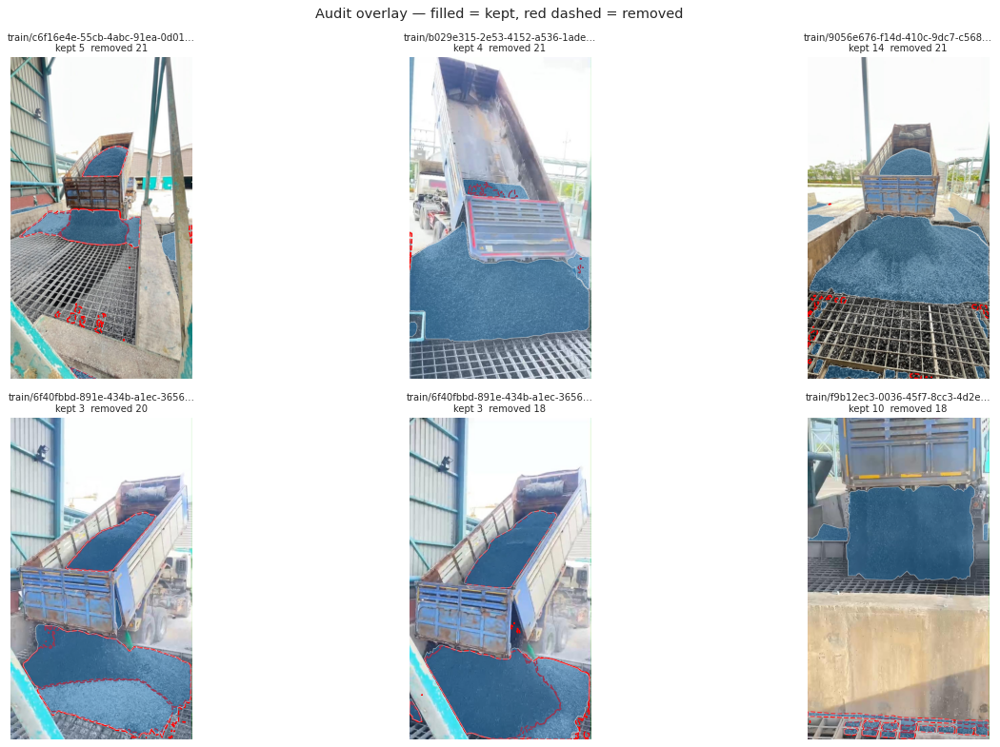

total removed: 2,217 (degenerate 209 | dupes 1424 | tiny 584)


In [21]:
# ============================================================
# 5.3 AUDIT OVERLAY — what the cleaning removed (per image)
# ============================================================
# kept   = filled polygon in class color
# removed = red dashed outline (degenerate / duplicate / tiny noise)

removed = df[~keep].copy()
removed_per_img = (removed.groupby(["split", "image"]).size()
                   .sort_values(ascending=False))

N_SHOW = 6
top_imgs = removed_per_img.head(N_SHOW).index.tolist()
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, (split, img) in zip(axes.ravel(), top_imgs):
    im = np.asarray(Image.open(DATASET_DIR / split / "images" / img))
    h, w = im.shape[:2]
    ax.imshow(im)
    kept_img = df_clean[(df_clean["split"] == split) & (df_clean["image"] == img)]
    rm_img   = removed[(removed["split"] == split) & (removed["image"] == img)]
    for _, r in rm_img.iterrows():
        if len(r["poly"]) >= 3:
            ax.add_patch(MplPolygon(np.asarray(r["poly"]) * [w, h], closed=True,
                                    fill=False, edgecolor="red", ls="--", lw=1.2))
    for _, r in kept_img.iterrows():
        ax.add_patch(MplPolygon(np.asarray(r["poly"]) * [w, h], closed=True,
                                fill=True, alpha=0.45,
                                facecolor=CLASS_COLORS[r["class"]],
                                edgecolor="white", lw=0.7))
    ax.set_title(f"{split}/{img[:28]}…\nkept {len(kept_img)}  removed {len(rm_img)}",
                 fontsize=9)
    ax.axis("off")
plt.suptitle("Audit overlay — filled = kept, red dashed = removed", fontsize=13)
plt.tight_layout()
plt.show()

print(f"total removed: {len(removed):,} "
      f"(degenerate {n_degenerate} | dupes {n_merged_away} | tiny {n_tiny})")

## 6. ตรวจ split — leakage ระดับคลิปและภาพเกือบซ้ำ

ชื่อไฟล์เป็น `<uuid>_mp4-<frame>_jpg.rf.<hash>.jpg` โดย prefix `uuid` ใช้ระบุ upload batch/คลิปต้นทาง ตาราง top-10 ในส่วน 3.6 พบ UUID เดียวกันใน **หลาย split** จึงมีเฟรมจากคลิปเดียวกันข้าม train/valid/test ซึ่งอาจทำให้คะแนนสูงเกินจริง

รายการตรวจ:
1. **6.1** จัดกลุ่ม UUID นับ group ที่ข้าม split และแสดงภาพ
2. **6.2** ตรวจ near-duplicate ด้วย dHash รวม candidate groups ด้วย **union-find** เพื่อไม่แยกเฟรมที่คล้ายกัน แม้ UUID ต่างกัน
3. **6.3** ตรวจภาพ label ว่างทั้ง 5 ภาพ ว่าเป็น background หรือขาด annotation
4. **6.4** ตรวจ mask ที่อัตราส่วนด้านสุดโต่งจาก flag ในส่วน 2.8

source groups (uuid prefix): 30
groups spanning >1 split   : 17
images in leaked groups    : 1,073 (98.5% of dataset)

worst offenders:
                                         n_imgs  n_splits                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                       

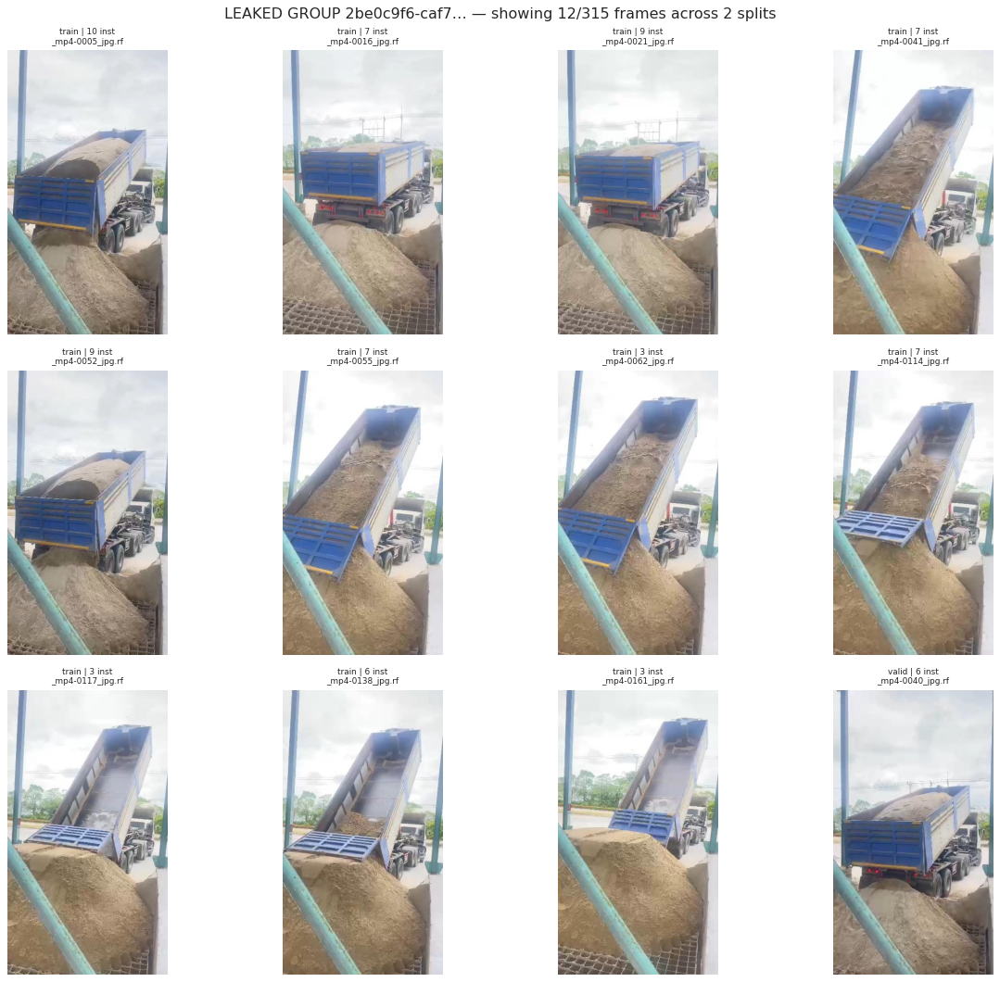

In [22]:
# ============================================================
# 6.1 VIDEO-LEVEL LEAKAGE — same uuid prefix in multiple splits?
# ============================================================
df_imgs["group"] = df_imgs["image"].str.split("_").str[0]

grp = df_imgs.groupby("group").agg(
    n_imgs=("image", "count"),
    n_splits=("split", "nunique"),
    splits=("split", lambda s: "/".join(sorted(s))))
leaky = grp[grp["n_splits"] > 1].sort_values("n_imgs", ascending=False)

print(f"source groups (uuid prefix): {len(grp):,}")
print(f"groups spanning >1 split   : {len(leaky):,}")
print(f"images in leaked groups    : {int(leaky['n_imgs'].sum()):,} "
      f"({leaky['n_imgs'].sum()/len(df_imgs)*100:.1f}% of dataset)")
print("\nworst offenders:")
print(leaky.head(15).to_string())

# ---- visualize one leaked group: same clip, different splits --
# MEMORY GUARD: a leaked clip can hold 100+ full-res frames — rendering
# them all into one figure is what caused the OOM. Cap at MAX_SHOW.
MAX_SHOW = 12
if len(leaky):
    ex = leaky.index[0]
    show = df_imgs[df_imgs["group"] == ex]
    if len(show) > MAX_SHOW:
        show = show.sample(MAX_SHOW, random_state=42).sort_index()
    show = show.reset_index(drop=True)
    n = len(show)
    ncols = min(n, 4)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 4.5 * nrows))
    for ax, (_, r) in zip(np.atleast_1d(axes).ravel(), show.iterrows()):
        ax.imshow(Image.open(DATASET_DIR / r["split"] / "images" / r["image"]))
        n_inst = len(df[(df["split"] == r["split"]) & (df["image"] == r["image"])])
        ax.set_title(f'{r["split"]} | {n_inst} inst\n{r["image"][36:52]}', fontsize=8)
        ax.axis("off")
    for ax in np.atleast_1d(axes).ravel()[n:]:
        ax.axis("off")
    plt.suptitle(f'LEAKED GROUP {ex[:13]}… — showing {n}/{len(df_imgs[df_imgs["group"] == ex])} '
                 f'frames across {show["split"].nunique()} splits')
    plt.tight_layout()
    plt.show()
    plt.close("all")

near-duplicate pairs (ham <= 6): 5,608
  same uuid-group (adjacent frames, expected): 5,572
  cross-split                                : 2,730
  cross-GROUP (uuid misses these!)           : 36

groups after near-dup merging: 26 (was 30)


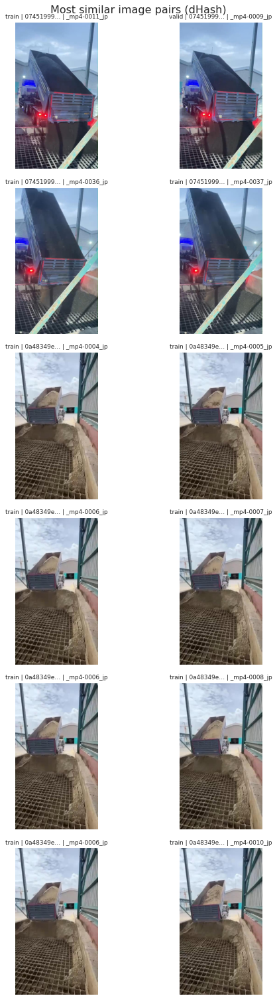

In [23]:
# ============================================================
# 6.2 NEAR-DUPLICATE FRAMES — dHash (64-bit difference hash)
# ============================================================
# catches same-scene frames even when uuid prefixes differ.
# Pairs are bucketed: same-group (expected), cross-split (leakage),
# cross-group (missed by uuid grouping -> must be merged).

def dhash(path, size=8):
    a = np.asarray(Image.open(path).convert("L")
                   .resize((size + 1, size), Image.LANCZOS), dtype=np.int16)
    return (a[:, 1:] > a[:, :-1]).ravel()

HASH_THR = 6   # hamming distance out of 64 bits

paths  = [DATASET_DIR / r["split"] / "images" / r["image"]
          for _, r in df_imgs.iterrows()]
H      = np.stack([dhash(p) for p in paths])
ham    = (H[:, None, :] != H[None, :, :]).sum(-1)
np.fill_diagonal(ham, 999)

ii, jj = np.where(np.triu(ham <= HASH_THR))
pairs = pd.DataFrame({
    "i": ii, "j": jj,
    "ham": ham[ii, jj],
    "grp_i": df_imgs.iloc[ii]["group"].values,
    "grp_j": df_imgs.iloc[jj]["group"].values,
    "spl_i": df_imgs.iloc[ii]["split"].values,
    "spl_j": df_imgs.iloc[jj]["split"].values,
})
pairs["same_group"] = pairs["grp_i"] == pairs["grp_j"]
pairs["cross_split"] = pairs["spl_i"] != pairs["spl_j"]

print(f"near-duplicate pairs (ham <= {HASH_THR}): {len(pairs):,}")
print(f"  same uuid-group (adjacent frames, expected): {int(pairs['same_group'].sum()):,}")
print(f"  cross-split                                : {int(pairs['cross_split'].sum()):,}")
cross_grp = pairs[~pairs["same_group"]]
print(f"  cross-GROUP (uuid misses these!)           : {len(cross_grp):,}")

# ---- build merged groups: union-find uuid + near-dup links ----
parent = {g: g for g in grp.index}
def _find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]; x = parent[x]
    return x
for _, p in cross_grp.iterrows():
    parent[_find(p["grp_i"])] = _find(p["grp_j"])
df_imgs["merged_group"] = df_imgs["group"].map(_find)
print(f"\ngroups after near-dup merging: {df_imgs['merged_group'].nunique():,} "
      f"(was {len(grp):,})")

# ---- visualize the most similar pairs ------------------------
show = pairs.nsmallest(6, "ham")
fig, axes = plt.subplots(6, 2, figsize=(8, 3.2 * 6))
for row, (_, p) in enumerate(show.iterrows()):
    for col, ix in enumerate((p["i"], p["j"])):
        r = df_imgs.iloc[ix]
        axes[row, col].imshow(Image.open(paths[ix]))
        axes[row, col].set_title(f'{r["split"]} | {r["group"][:8]}… | {r["image"][36:48]}',
                                 fontsize=8)
        axes[row, col].axis("off")
    axes[row, 0].set_ylabel(f'ham={p["ham"]} {"SPLIT-LEAK" if p["cross_split"] else ""}',
                           fontsize=8)
plt.suptitle("Most similar image pairs (dHash)")
plt.tight_layout()
plt.show()

images with zero labels: 5


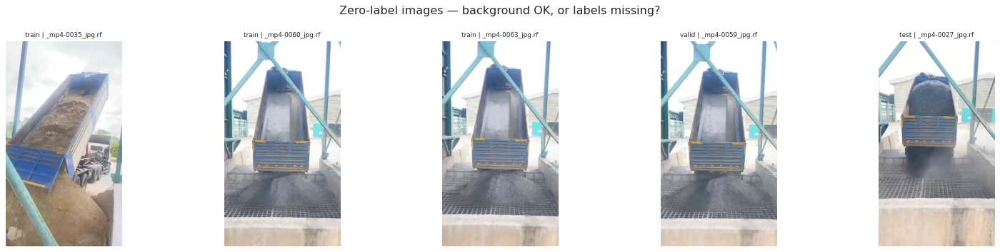

In [24]:
# ============================================================
# 6.3 EMPTY-LABEL IMAGES — real background or missing annotation?
# ============================================================
n_per_img = df.groupby(["split", "image"]).size()
empty = df_imgs.merge(n_per_img.rename("n"), left_on=["split", "image"],
                      right_index=True, how="left").fillna({"n": 0})
empty = empty[empty["n"] == 0]
print(f"images with zero labels: {len(empty)}")

fig, axes = plt.subplots(1, len(empty), figsize=(4 * len(empty), 4.5))
for ax, (_, r) in zip(np.atleast_1d(axes).ravel(), empty.iterrows()):
    ax.imshow(Image.open(DATASET_DIR / r["split"] / "images" / r["image"]))
    ax.set_title(f'{r["split"]} | {r["image"][36:52]}', fontsize=8)
    ax.axis("off")
plt.suptitle("Zero-label images — background OK, or labels missing?")
plt.tight_layout()
plt.show()

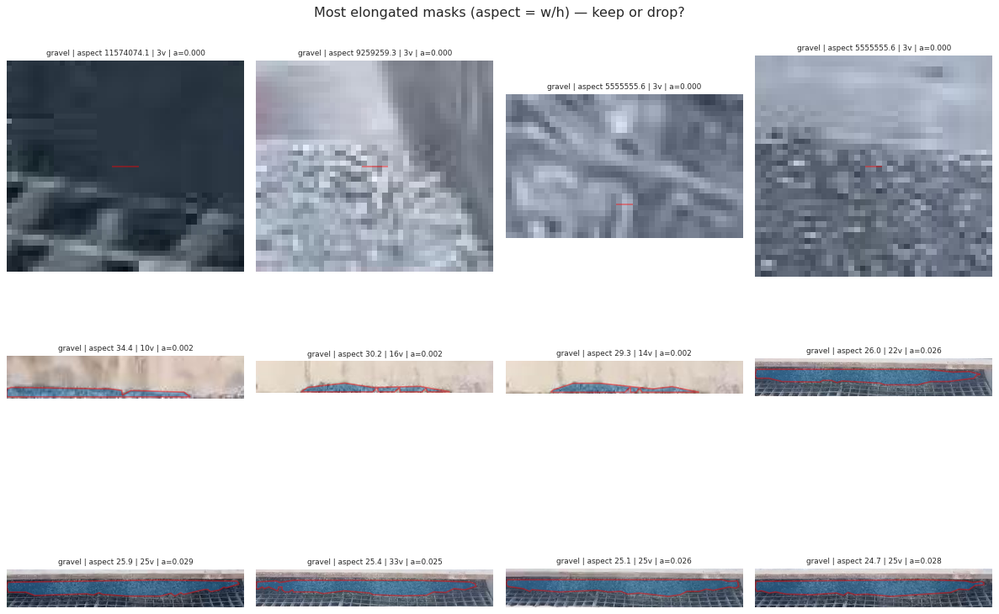

decision: elongated != noise — spread-out piles are legitimately long.
these stay UNLESS the crops above show broken/nonsense masks.


In [25]:
# ============================================================
# 6.4 ELONGATED MASKS — extreme aspect ratios: real piles or bad masks?
# ============================================================
# n_vertices>=3 only: degenerate lines get aspect=inf from bh=0
elong = df[df["n_vertices"] >= 3].nlargest(12, "aspect")
fig, axes = plt.subplots(3, 4, figsize=(15, 11))
for ax, (_, r) in zip(axes.ravel(), elong.iterrows()):
    img = np.asarray(Image.open(DATASET_DIR / r["split"] / "images" / r["image"]))
    h, w = img.shape[:2]
    px = np.asarray(r["poly"]) * [w, h]
    x0, y0 = px[:, 0].min(), px[:, 1].min()
    x1, y1 = px[:, 0].max(), px[:, 1].max()
    pad_x = max((x1 - x0) * 0.3, 20)   # min pad so thin slivers still crop
    pad_y = max((y1 - y0) * 0.3, 20)
    cx0, cx1 = int(max(0, x0 - pad_x)), int(min(w, x1 + pad_x))
    cy0, cy1 = int(max(0, y0 - pad_y)), int(min(h, y1 + pad_y))
    ax.imshow(img[cy0:cy1, cx0:cx1], extent=[cx0, cx1, cy1, cy0])
    ax.add_patch(MplPolygon(px, closed=True, fill=True, alpha=0.45,
                            facecolor=CLASS_COLORS[r["class"]],
                            edgecolor="red", lw=1.5))
    ax.set_xlim(cx0, cx1); ax.set_ylim(cy1, cy0)
    ax.set_title(f'{r["class"]} | aspect {r["aspect"]:.1f} | '
                 f'{r["n_vertices"]}v | a={r["area_norm"]:.3f}', fontsize=8)
    ax.axis("off")
plt.suptitle("Most elongated masks (aspect = w/h) — keep or drop?")
plt.tight_layout()
plt.show()

print("decision: elongated != noise — spread-out piles are legitimately long.")
print("these stay UNLESS the crops above show broken/nonsense masks.")

## 7. `data/gold/` — benchmark เดิมที่แบ่งตาม group

โหมด audit อ่าน mapping เดิม ไม่สร้าง group จากชื่อไฟล์ใหม่แล้วเขียนทับ identity `merged_group` เป็นตัวแทนสำหรับควบคุม leakage จาก upload ID และ dHash ไม่ได้พิสูจน์ความเป็นอิสระของเหตุการณ์ การแบ่งตาม group เหมาะกว่าการสุ่มเฟรม แต่ฉากสัมพันธ์กันและบางคลาสมี group น้อย จึงยังจำกัดข้อสรุป generalization

ฝึกด้วย train เท่านั้น ใช้ validation เลือก hyperparameter/checkpoint/threshold ชุด test เดิมผ่านการดูระหว่างพัฒนาแล้ว จึง **ไม่ใช่ untouched confirmatory test** แนวทาง CV ปัจจุบันอยู่ในส่วน 17 และต้องรายงานความแปรปรวนระหว่าง folds แยกจาก training seeds ไม่สร้าง split ใหม่เพียงเพื่อแก้ผล test ที่สังเกตไปแล้ว

Builders ต้องเปิดเองและสร้างไดเรกทอรีใหม่ horizontal flip/affine/photometric เป็นสมมติฐานที่ต้องตรวจว่าเก็บ label ถูกต้อง ไม่ใช้ vertical flip เพราะฉากกองวัสดุขึ้นกับแรงโน้มถ่วง ส่วน intervention แบบ split เดิมใน notebook 16 คง validation/test ไว้เหมือนเดิม

In [26]:
# ============================================================
# 7.1 BUILD GOLD — group-aware train/valid/test from silver
# ============================================================
# merged_group (6.2) guarantees: no clip and no near-dup pair crosses splits.
# Class-aware packing: each clip tends to be single-class, so quotas are
# tracked for image count AND per-class instance counts.

GOLD_DIR = EXP / 'data' / 'gold'
TARGET = {'train': 0.70, 'valid': 0.20, 'test': 0.10}
SEED = 42

# ---- per-group stats: images + instances per class ------------
g_stats = df_imgs.groupby('merged_group').size().rename('n_imgs').to_frame()
ginst = df_clean.merge(df_imgs[['split','image','merged_group']], on=['split','image']).groupby(['merged_group','class']).size().unstack(fill_value=0)
for c in CLASS_NAMES:
    g_stats[c] = ginst[c] if c in ginst.columns else 0
g_stats = g_stats.fillna(0).sample(frac=1, random_state=SEED).sort_values('n_imgs', ascending=False)

# ---- quotas ----------------------------------------------------
METRICS = ['n_imgs'] + CLASS_NAMES
quota = {m: {s: TARGET[s] * (len(df_imgs) if m == 'n_imgs' else g_stats[m].sum()) for s in TARGET} for m in METRICS}
load = {s: {m: 0. for m in METRICS} for s in TARGET}
g2split = {}
for g, row in g_stats.iterrows():
    # pick the split whose worst metric overflows the least
    best = min(TARGET, key=lambda s: max((load[s][m] + row[m]) / max(quota[m][s], 1) for m in METRICS))
    g2split[g] = best
    for m in METRICS:
        load[best][m] += row[m]
df_imgs['new_split'] = df_imgs['merged_group'].map(g2split)
if not BUILD_DATASETS:
    existing = pd.read_csv(GOLD_DIR / 'split_audit.csv')
    assert existing['image'].is_unique
    mapping = existing.set_index('image')['new_split']
    assert df_imgs['image'].isin(mapping.index).all()
    df_imgs['new_split'] = df_imgs['image'].map(mapping)
    df_imgs['merged_group'] = df_imgs['image'].map(existing.set_index('image')['merged_group'])

# ---- report ----------------------------------------------------
sizes = df_imgs.groupby('new_split').size().rename('n_images').to_frame()
sizes['pct'] = sizes['n_images'] / len(df_imgs) * 100
print(sizes)
chk = df_imgs.groupby('merged_group')['new_split'].nunique()
assert (chk == 1).all(), 'merged group crossed a split boundary'

# ---- write gold (wipe first: re-runs must not leave stale files)
if BUILD_DATASETS:
    GOLD_DIR = new_dataset_dir(EXP / 'data' / ('gold_' + STAMP))
    for split in SPLITS:
        for kind in ('images','labels'):
            (GOLD_DIR / split / kind).mkdir(parents=True)
    for _, r in df_imgs.iterrows():
        for kind, name in [('images', r['image']), ('labels', Path(r['image']).stem + '.txt')]:
            shutil.copy2(SILVER_DIR / r['split'] / kind / name, GOLD_DIR / r['new_split'] / kind / name)
    (GOLD_DIR / 'data.yaml').write_text(f'path: {GOLD_DIR}\ntrain: train/images\nval: valid/images\ntest: test/images\nnames: {CLASS_NAMES}\n')
    df_imgs[['image','group','merged_group','split','new_split']].rename(columns={'split':'bronze_split'}).to_csv(GOLD_DIR / 'split_audit.csv', index=False)

# ---- post-split instance stats ---------------------------------
df_gold = df_clean.merge(df_imgs[['split','image','new_split']], on=['split','image'])
print(df_gold.groupby(['new_split','class']).size().unstack(fill_value=0))

           n_images        pct
new_split                     
test            105   9.641873
train           754  69.237833
valid           230  21.120294
class      gravel  sand
new_split              
test          189   159
train        1281  1541
valid         317   374


In [27]:
# ============================================================
# 7.2 DATA CARD — provenance + cleaning audit for the thesis
# ============================================================
card = f"""# Data Card — Aggregate (gravel/sand) Instance Segmentation

## Source
- Roboflow project `aggregate_rock-and-sand` v5, workspace `ilovefoods-workspace-qd0ut`
- Format: YOLO instance segmentation (normalized polygons), classes: {CLASS_NAMES}
- Frames extracted from ~{len(grp)} source video clips (uuid-prefix groups)

## Pipeline (bronze -> silver -> gold)

| stage | content | instances |
|---|---|---|
| bronze | raw Roboflow export, frame-level random split | {len(df):,} |
| silver | degenerate removed ({n_degenerate}), duplicate clusters merged keep-largest ({n_merged_away} in {len(clusters)} clusters, IoMin>={CLUSTER_THR} same-class), tiny noise removed ({n_tiny}, area<{TINY_THR}) | {len(df_clean):,} |
| gold | silver + group-aware re-split (uuid + dHash ham<={HASH_THR} merged groups, class-aware 70/20/10) | {len(df_clean):,} |

## Key decisions
- duplicates: same-image same-class polygon overlap; IoMin >= {CLUSTER_THR} -> keep largest member
- tiny masks: standalone < {TINY_THR} image area confirmed noise via visual inspection
- elongated masks: kept (real spread-out piles, not noise)
- empty-label (background-only) images: removed at 7.3 per owner decision ({int((emptied['n']==0).sum())} images; gold counts in the table above are pre-removal)

## Leakage finding
- Original splits: {len(leaky)}/{len(grp)} uuid groups spanned >1 split
  ({int(leaky['n_imgs'].sum())} images = {leaky['n_imgs'].sum()/len(df_imgs)*100:.1f}% leaked)
- dHash found {len(cross_grp)} cross-group near-dup pairs -> merged to {df_imgs['merged_group'].nunique()} groups
- Gold split: 0 groups cross split boundaries (asserted)

## Final gold splits
{sizes.to_string()}

## Caveats
- {len(grp)} clips is limited scene diversity for 1,089 frames — adjacent frames are highly correlated
- auto-labels are pseudo-ground-truth; residual label noise exists below inspection thresholds
- eval metrics on gold test are clip-independent but NOT scene-independent if clips share sites
- clips are mostly single-class scenes: train has 15% mixed-class images but valid/test have ZERO —
  per-class AP is reported separately; mixed-scene performance cannot be evaluated on this data
- quality flags are uneven across splits (test 14% vs valid 4% of images) — see quality_flags.csv
  for per-slice reporting
"""
(AUDIT_OUT / "DATA_CARD.md").write_text(card, encoding="utf-8")
print(card)
print(f"written: {GOLD_DIR / 'DATA_CARD.md'}")

# Data Card — Aggregate (gravel/sand) Instance Segmentation

## Source
- Roboflow project `aggregate_rock-and-sand` v5, workspace `ilovefoods-workspace-qd0ut`
- Format: YOLO instance segmentation (normalized polygons), classes: ['gravel', 'sand']
- Frames extracted from ~30 source video clips (uuid-prefix groups)

## Pipeline (bronze -> silver -> gold)

| stage | content | instances |
|---|---|---|
| bronze | raw Roboflow export, frame-level random split | 6,078 |
| silver | degenerate removed (209), duplicate clusters merged keep-largest (1424 in 932 clusters, IoMin>=0.5 same-class), tiny noise removed (584, area<0.001) | 3,861 |
| gold | silver + group-aware re-split (uuid + dHash ham<=6 merged groups, class-aware 70/20/10) | 3,861 |

## Key decisions
- duplicates: same-image same-class polygon overlap; IoMin >= 0.5 -> keep largest member
- tiny masks: standalone < 0.001 image area confirmed noise via visual inspection
- elongated masks: kept (real spread-out piles, not noise)
- empt

### 7.3 ประวัติการตัดภาพ negative/background 5 ภาพ

การเตรียม gold เดิมตัดภาพ label ว่าง 5 ภาพออก notebook นี้ **ไม่ลบไฟล์** และชุดใหม่เก็บ negative ที่ตรวจแล้ว label ว่างเป็นกรณีที่ถูกต้องสำหรับ detection/segmentation ไม่ควรลบเพียงเพื่อให้โค้ดง่ายขึ้น

หากชุดประเมินไม่มี negative/background จะประเมิน false positive บน background จริงไม่ได้ ต้องมีฉาก negative ที่ตรวจ label อย่างอิสระและยืนยันความครบถ้วนของ annotation ก่อนถือว่าไฟล์ว่างแปลว่าไม่มีวัสดุ

0 empty-label images found


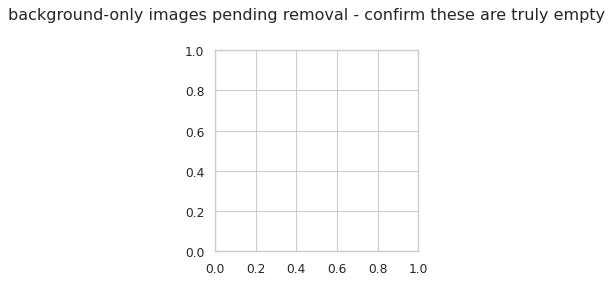

In [28]:
# ============================================================
# 7.3a VIZ - background-only images pending removal
# ============================================================
# VIZ CELL - runs before the delete cell. Loads the empty-label
# images straight from gold/ (still on disk at this point).

empty_pre = []
for split in SPLITS:
    for lt in sorted((GOLD_DIR / split / "labels").iterdir()):
        if not lt.read_text().strip():
            for cand in (GOLD_DIR / split / "images").glob(lt.stem + ".*"):
                empty_pre.append((split, cand))

print(f"{len(empty_pre)} empty-label images found")
n = max(len(empty_pre), 1)
fig, axes = plt.subplots(1, n, figsize=(3.4 * n, 3.6))
for ax, (split, pth) in zip(np.atleast_1d(axes), empty_pre):
    ax.imshow(Image.open(pth))
    ax.set_title(f"{split} | {pth.stem[:28]}", fontsize=8)
    ax.axis("off")
plt.suptitle("background-only images pending removal - confirm these are truly empty")
plt.tight_layout(); plt.show(); plt.close("all")


In [29]:
# ============================================================
# 7.3 REMOVE EMPTY-LABEL IMAGES — background-only, owner decision
# ============================================================
# ACTION CELL — deletes image+label pairs whose label file is empty,
# and drops the rows from df_imgs so downstream cells stay consistent.
# split_audit.csv (already written) keeps the full historical mapping.

removed = []
actual_images = {p.name for s in SPLITS for p in (GOLD_DIR / s / 'images').iterdir() if p.is_file()}
missing_images = df_imgs[~df_imgs.image.isin(actual_images)]
assert missing_images.image.isin(emptied.loc[emptied.n == 0, 'image']).all(), 'Non-background images unexpectedly missing.'
df_imgs = df_imgs[df_imgs.image.isin(actual_images)].copy()
df_gold = df_gold[df_gold.image.isin(actual_images)].copy()
print('Historical background removals:', len(missing_images))
print('No files deleted. Newly built datasets retain valid negative/background images.')

Historical background removals: 5
No files deleted. Newly built datasets retain valid negative/background images.


## 8. ความไม่สมดุลของคลาสและ preprocessing

- **8.1** ตรวจสมดุลคลาสแต่ละ split ของ `gold` และพิจารณา weighting/resampling
- **8.2** เปรียบเทียบการเพิ่ม contrast โดยใช้ CLAHE เป็นตัวเลือกสำหรับ texture ที่ contrast ต่ำในงานวัสดุ/แร่
- **8.3** ตัวเลือกสร้าง `data/gold_clahe/` โดย label เดิมและภาพผ่าน CLAHE สำหรับการฝึกเปรียบเทียบ A/B

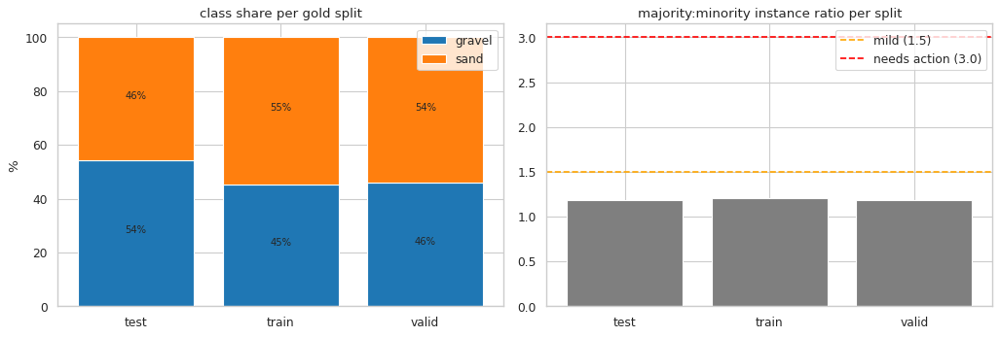

per-split instance ratio (max/min):
new_split
test     1.19
train    1.20
valid    1.18

global gravel:sand = 1787:2074 (ratio 1.16)
inverse-freq class weights (if weighted loss): {'gravel': 1.08, 'sand': 0.931}



image-level class presence per split:
       images  gravel_img_pct  sand_img_pct  mixed_class_imgs  empty_imgs
split                                                                    
train     753            58.2          56.7               112           0
valid     226            42.5          57.5                 0           0
test      105            63.8          36.2                 0           0

verdict: instance ratio < 1.5 everywhere -> no resampling needed.
BUT valid/test have ZERO mixed-class images (single-class clips) ->
per-class AP only; mixed-scene performance unmeasurable. Documented in DATA_CARD.
saved -> /home/supawich/Desktop/Aggregate_Project/experiment/results/nb00_audit/20261013T053359228548Z


In [30]:
# ============================================================
# 8.1 CLASS IMBALANCE — per gold split + remedy decision
# ============================================================
bal = df_gold.groupby(["new_split", "class"]).size().unstack(fill_value=0)
bal_pct = bal.div(bal.sum(axis=1), axis=0) * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
bottom = np.zeros(len(bal_pct))
for c in CLASS_NAMES:
    axes[0].bar(bal_pct.index, bal_pct[c], bottom=bottom,
                color=CLASS_COLORS[c], label=c)
    for i, v in enumerate(bal_pct[c]):
        axes[0].text(i, bottom[i] + v / 2, f"{v:.0f}%", ha="center", fontsize=9)
    bottom += bal_pct[c].values
axes[0].set_title("class share per gold split")
axes[0].set_ylabel("%"); axes[0].legend()

ratio = bal.max(axis=1) / bal.min(axis=1)
axes[1].bar(bal.index, ratio, color="#7f7f7f")
axes[1].axhline(1.5, color="orange", ls="--", label="mild (1.5)")
axes[1].axhline(3.0, color="red", ls="--", label="needs action (3.0)")
axes[1].set_title("majority:minority instance ratio per split")
axes[1].legend()
plt.tight_layout(); plt.show()
plt.close("all")

# inverse-frequency weights IF loss weighting is wanted
tot = df_gold.groupby("class").size()
iw = tot.sum() / (len(tot) * tot)
print("per-split instance ratio (max/min):")
print(ratio.round(2).to_string())
print(f"\nglobal gravel:sand = {tot.iloc[0]}:{tot.iloc[1]} "
      f"(ratio {tot.max()/tot.min():.2f})")
print("inverse-freq class weights (if weighted loss):",
      {c: round(float(iw[c]), 3) for c in tot.index})

# ---- image-level co-occurrence (deeper than instance ratio) ---
# clips are mostly single-class scenes -> check what eval splits actually see
pres = df_gold.groupby(["new_split", "image"])["class"].agg(set)
rows = []
for s in SPLITS:
    imgs_s = df_imgs.loc[df_imgs.new_split == s, "image"]
    p = pres.loc[s]
    rows.append({
        "split": s, "images": len(imgs_s),
        "gravel_img_pct": round(p.apply(lambda x: "gravel" in x).mean() * 100, 1),
        "sand_img_pct":   round(p.apply(lambda x: "sand" in x).mean() * 100, 1),
        "mixed_class_imgs": int((p.apply(len) > 1).sum()),
        "empty_imgs": int(len(imgs_s) - len(p)),
    })
presence = pd.DataFrame(rows).set_index("split")
print("\nimage-level class presence per split:")
print(presence.to_string())
print("\nverdict: instance ratio < 1.5 everywhere -> no resampling needed.")
print("BUT valid/test have ZERO mixed-class images (single-class clips) ->")
print("per-class AP only; mixed-scene performance unmeasurable. Documented in DATA_CARD.")

# ---- persist for the audit trail -------------------------------
RES_DIR = AUDIT_OUT
RES_DIR.mkdir(exist_ok=True)
bal.assign(total=bal.sum(axis=1)).to_csv(RES_DIR / "class_instances_per_split.csv")
presence.to_csv(RES_DIR / "class_presence_per_split.csv")
print(f"saved -> {RES_DIR}")

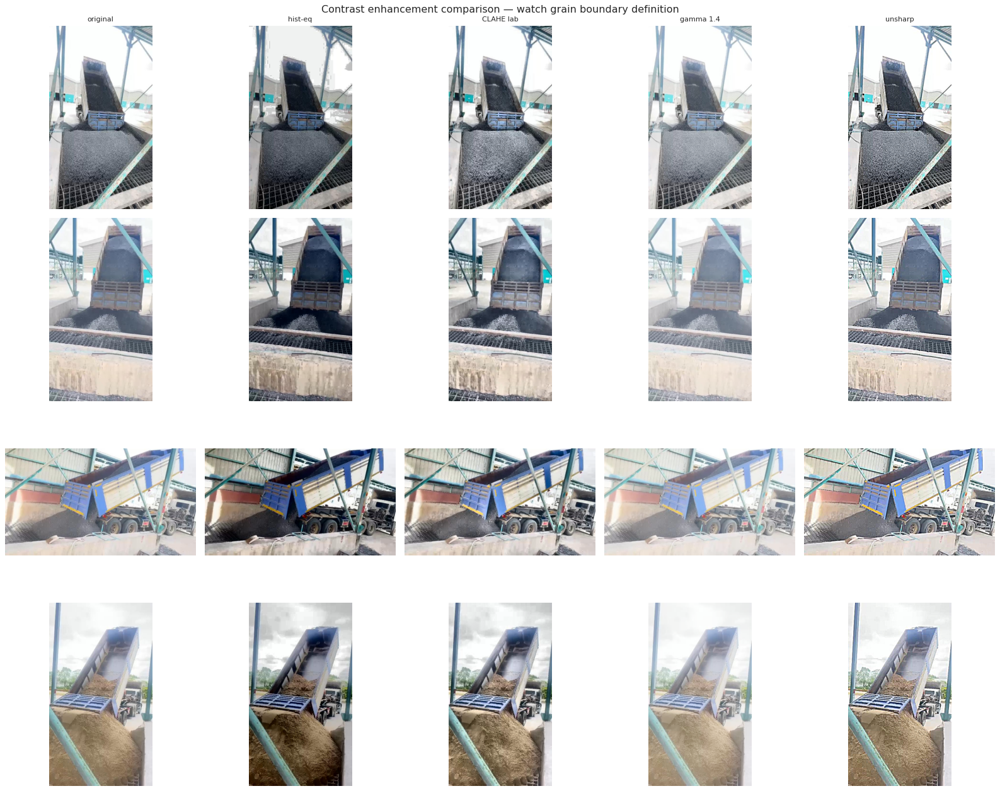

In [31]:
# ============================================================
# 8.2 CONTRAST PREPROCESSING BAKE-OFF — paper-backed techniques
# ============================================================
# CLAHE (Zuiderveld '94) is the standard enhancement in aggregate/mineral
# segmentation papers for low-contrast texture. Compared against:
# global hist-eq, gamma, unsharp mask. Decide visually before writing.

import cv2

def clahe_lab(img, clip=2.0, grid=8):
    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    l2 = cv2.createCLAHE(clipLimit=clip, tileGridSize=(grid, grid)).apply(l)
    return cv2.cvtColor(cv2.merge((l2, a, b)), cv2.COLOR_LAB2RGB)

def histeq_ycc(img):
    ycc = cv2.cvtColor(img, cv2.COLOR_RGB2YCrCb)
    ycc[:, :, 0] = cv2.equalizeHist(ycc[:, :, 0])
    return cv2.cvtColor(ycc, cv2.COLOR_YCrCb2RGB)

def gamma(img, g=1.4):
    lut = (np.arange(256) / 255.0) ** (1 / g) * 255
    return cv2.LUT(img, lut.astype(np.uint8))

def unsharp(img, s=3, k=1.5):
    blur = cv2.GaussianBlur(img, (0, 0), s)
    return cv2.addWeighted(img, 1 + k, blur, -k, 0)

sample = (df_imgs[df_imgs["new_split"] == "train"]
          .sample(4, random_state=11))
methods = [("original", lambda x: x), ("hist-eq", histeq_ycc),
           ("CLAHE lab", clahe_lab), ("gamma 1.4", gamma),
           ("unsharp", unsharp)]

fig, axes = plt.subplots(len(sample), len(methods),
                         figsize=(4 * len(methods), 4 * len(sample)))
for row, (_, r) in enumerate(sample.iterrows()):
    img = np.asarray(Image.open(SILVER_DIR / r["split"] / "images" / r["image"])
                     .convert("RGB"))
    for col, (name, fn) in enumerate(methods):
        axes[row, col].imshow(fn(img))
        axes[row, col].set_title(name if row == 0 else "", fontsize=10)
        axes[row, col].axis("off")
plt.suptitle("Contrast enhancement comparison — watch grain boundary definition")
plt.tight_layout()
plt.show()

### 8.3 วิเคราะห์ contrast แบบจับคู่ภาพ train ไม่ใช่วัดข้อมูลที่เพิ่มขึ้น

RMS contrast, entropy ของ grayscale histogram, Canny edge density และ Laplacian variance อธิบายลักษณะภาพ ไม่ใช่คะแนนความแม่นยำของงาน ค่าที่สูงขึ้นอาจเกิดจาก noise หรือ quantization การเพิ่ม contrast แบบ deterministic ไม่ยืนยันว่ามีข้อมูลใหม่สำหรับงาน และ entropy ลดลงก็ไม่พิสูจน์ว่าข้อมูลที่มีประโยชน์หายไป

เปรียบเทียบวิธีบน image ID เดียวกัน รายงาน paired deltas และค่าที่ใช้ แล้วทดสอบ preprocessing ที่กำหนดล่วงหน้าด้วย validation task metrics และหลาย seeds ใน notebook 16 ไม่รับหรือปฏิเสธวิธีจาก proxy เหล่านี้โดยอัตโนมัติ CLAHE เฉพาะ train กับ CLAHE ทั้ง train/deployment เป็นคนละ intervention

=== mean metric per method ===
              rms  entropy   edge       lap
method                                     
CLAHE 2.0  64.960    7.555  0.161  2894.665
gamma 1.4  45.216    6.957  0.099   732.562
hist-eq    74.834    7.105  0.141  1797.398
original   55.217    7.217  0.113   977.127
unsharp    63.748    7.289  0.174  5254.625

=== mean % delta vs original ===
hist-eq    rms  +37.4%  entropy  -1.6%  edge  +28.3%  lap +100.9%
CLAHE 2.0  rms  +18.6%  entropy  +4.7%  edge  +49.0%  lap +200.3%
gamma 1.4  rms  -18.3%  entropy  -3.6%  edge  -13.6%  lap  -27.0%
unsharp    rms  +15.8%  entropy  +1.0%  edge  +61.0%  lap +442.5%

=== CLAHE clipLimit sweep (grid 8x8) ===


clip 1.5: rms 63.28  entropy 7.498  edge 0.1536  lap 2387


clip 2.0: rms 64.96  entropy 7.555  edge 0.1615  lap 2895


clip 3.0: rms 67.11  entropy 7.626  edge 0.1730  lap 3777


clip 4.0: rms 68.30  entropy 7.665  edge 0.1811  lap 4396


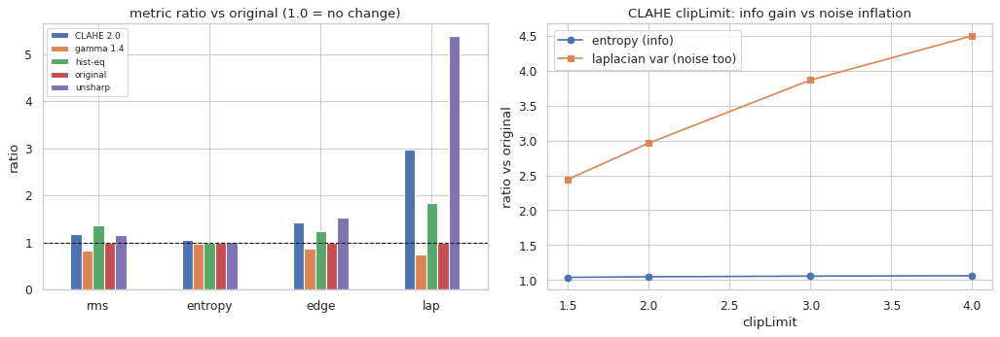

saved -> /home/supawich/Desktop/Aggregate_Project/experiment/results/nb00_audit/20261013T053359228548Z


In [32]:
# ============================================================
# 8.3 CONTRAST SCORECARD — quantitative bake-off + clip sweep
# ============================================================
# MEASURE CELL — computes metrics + charts, writes nothing to the dataset.
# Uses clahe_lab / histeq_ycc / gamma / unsharp from cell 8.2.

N_SAMPLE = 80   # fixed random sample of gold-train images

def img_metrics(img):
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    h = cv2.calcHist([gray], [0], None, [256], [0, 256]).ravel()
    p = h / h.sum(); p = p[p > 0]
    return {
        "rms":     float(gray.astype(np.float64).std()),
        "entropy": float(-(p * np.log2(p)).sum()),
        "edge":    float((cv2.Canny(gray, 60, 180) > 0).mean()),
        "lap":     float(cv2.Laplacian(gray.astype(np.float64), cv2.CV_64F).var()),
    }

pool = sorted((GOLD_DIR / "train" / "images").iterdir())
rng = np.random.default_rng(11)
sample = [pool[i] for i in rng.choice(len(pool), N_SAMPLE, replace=False)]

methods = [("original", lambda x: x), ("hist-eq", histeq_ycc),
           ("CLAHE 2.0", clahe_lab), ("gamma 1.4", gamma), ("unsharp", unsharp)]

rows = []
for p in sample:
    img = np.asarray(Image.open(p).convert("RGB"))
    for name, fn in methods:
        rows.append({"method": name, **img_metrics(fn(img))})
score = pd.DataFrame(rows)

agg = score.groupby("method")[["rms", "entropy", "edge", "lap"]].mean()
print("=== mean metric per method ===")
print(agg.round(3).to_string())

base = score[score.method == "original"].reset_index(drop=True)
print("\n=== mean % delta vs original ===")
for m in ["hist-eq", "CLAHE 2.0", "gamma 1.4", "unsharp"]:
    cur = score[score.method == m].reset_index(drop=True)
    d = (cur[["rms", "entropy", "edge", "lap"]] / base[["rms", "entropy", "edge", "lap"]] - 1) * 100
    print(f"{m:10s} rms {d['rms'].mean():+6.1f}%  entropy {d['entropy'].mean():+5.1f}%  "
          f"edge {d['edge'].mean():+6.1f}%  lap {d['lap'].mean():+6.1f}%")

# ---- CLAHE clipLimit sweep ------------------------------------
print("\n=== CLAHE clipLimit sweep (grid 8x8) ===")
sweep = {}
for clip in (1.5, 2.0, 3.0, 4.0):
    m = [img_metrics(clahe_lab(np.asarray(Image.open(p).convert("RGB")), clip=clip))
         for p in sample]
    sweep[clip] = pd.DataFrame(m).mean()
    print(f"clip {clip}: rms {sweep[clip]['rms']:.2f}  entropy {sweep[clip]['entropy']:.3f}  "
          f"edge {sweep[clip]['edge']:.4f}  lap {sweep[clip]['lap']:.0f}")

# ---- viz ------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

norm = agg / agg.loc["original"]
norm.T.plot(kind="bar", ax=axes[0])
axes[0].axhline(1.0, color="k", ls="--", lw=1)
axes[0].set(title="metric ratio vs original (1.0 = no change)", ylabel="ratio")
axes[0].tick_params(axis="x", rotation=0)
axes[0].legend(fontsize=8)

clips = pd.DataFrame(sweep).T
axes[1].plot(clips.index, clips["entropy"] / agg.loc["original", "entropy"],
             "o-", label="entropy (info)")
axes[1].plot(clips.index, clips["lap"] / agg.loc["original", "lap"],
             "s-", label="laplacian var (noise too)")
axes[1].set(title="CLAHE clipLimit: info gain vs noise inflation",
            xlabel="clipLimit", ylabel="ratio vs original")
axes[1].legend()

plt.tight_layout()
plt.show()
plt.close("all")

# ---- persist scorecard for the audit trail ---------------------
RES_DIR = AUDIT_OUT
RES_DIR.mkdir(exist_ok=True)
score.to_csv(RES_DIR / "contrast_metrics_per_image.csv", index=False)
agg.round(4).to_csv(RES_DIR / "contrast_metrics_summary.csv")
pd.DataFrame(sweep).T.to_csv(RES_DIR / "clahe_clip_sweep.csv")
print(f"saved -> {RES_DIR}")

### 8.4 ตัวเลือกทดลอง — CLAHE-LAB(clipLimit=2.0, grid=8×8)

ค่า contrast เก่าเป็นผลสำรวจ ไม่ใช่หลักฐานว่า CLAHE เพิ่ม segmentation accuracy หรือเพิ่มข้อมูล เก็บ CLAHE เป็น **candidate ablation** ไม่ใช่กฎ preprocessing ที่ยอมรับสำหรับ production label ต้องเหมือนเดิมทุก byte เพราะ transform นี้ไม่เปลี่ยน geometry

Builder สร้างไดเรกทอรีเวอร์ชันใหม่เมื่อเปิดอย่างชัดเจน ไม่เปลี่ยน `data/gold` notebook 16 เปรียบเทียบ CLAHE เฉพาะ train กับ control บน validation/test, seeds และ tuning budget เดียวกัน

In [33]:
# ============================================================
# 8.4 WRITE data/gold_clahe/ — CLAHE images, identical labels
# ============================================================
# ACTION CELL — runs only after the 8.4 decision above.

import hashlib
CLAHE_DIR = EXP / 'data' / 'gold_clahe'
def md5(p):
    return hashlib.md5(p.read_bytes()).hexdigest()

# ---- verification ----------------------------------------------
if BUILD_DATASETS:
    CLAHE_DIR = new_dataset_dir(EXP / 'data' / ('gold_clahe_' + STAMP))
    for split in SPLITS:
        for kind in ('images','labels'):
            (CLAHE_DIR / split / kind).mkdir(parents=True)
        for ip in sorted((GOLD_DIR / split / 'images').iterdir()):
            image = np.asarray(Image.open(ip).convert('RGB'))
            Image.fromarray(clahe_lab(image)).save(CLAHE_DIR / split / 'images' / ip.name)
            shutil.copy2(GOLD_DIR / split / 'labels' / (ip.stem + '.txt'), CLAHE_DIR / split / 'labels' / (ip.stem + '.txt'))
    (CLAHE_DIR / 'data.yaml').write_text(f'path: {CLAHE_DIR}\ntrain: train/images\nval: valid/images\ntest: test/images\nnames: {CLASS_NAMES}\n')
else:
    print('CLAHE dataset build skipped; contrast statistics are exploratory, not information gain.')
if CLAHE_DIR.exists():
    for split in SPLITS:
        a = {p.name: p for p in (GOLD_DIR / split / 'labels').glob('*.txt')}
        b = {p.name: p for p in (CLAHE_DIR / split / 'labels').glob('*.txt')}
        assert a.keys() == b.keys(), f'{split}: label filename mismatch'
        assert all(md5(a[k]) == md5(b[k]) for k in a), f'{split}: labels changed'

# ---- visual check: masks still align after enhancement ---------
print('CLAHE geometry validation finished; downstream validation is in notebook 16.')

CLAHE dataset build skipped; contrast statistics are exploratory, not information gain.
CLAHE geometry validation finished; downstream validation is in notebook 16.


## 9. ตรวจคุณภาพภาพ — ตัวเลือก preprocessing ที่เหลือ

ส่วน 8.4 ตรวจ contrast แล้ว ตัวเลือกอื่น **วัดก่อนแก้** เช่นเดียวกับส่วน 3–4:

| ตัวเลือกแก้ไข | วิธีวัด | สิ่งที่อาจสนับสนุนการแก้ |
|---|---|---|
| ลด blur / sharpening | Laplacian variance รายภาพ | มีภาพค่า lap ต่ำมากจำนวนมาก หรือกระจุกใน split เดียว |
| white balance | ผลต่างค่าเฉลี่ยช่อง R−B เทียบ gray-world | สีเพี้ยนทั้งชุด; สีเพี้ยนคลิปเดียวอาจเป็นสภาพถ่ายจริง |
| normalize brightness | ค่าเฉลี่ย gray รายภาพ | outliers ที่เกินความต่างแสงระดับคลิป |
| ปรับ saturation | ค่าเฉลี่ยช่อง S รายภาพ | ปลายการกระจายที่ซีดหรืออิ่มสีเกิน |

Percentile flags (p2.5 / p97.5) ใช้คัดกรณีให้ผู้ตรวจดู **ไม่ใช่กฎลบภาพ** บันทึกปัญหาระดับคลิป และแก้เฉพาะ artifacts ทั้งชุดที่มีหลักฐานชัดเจน

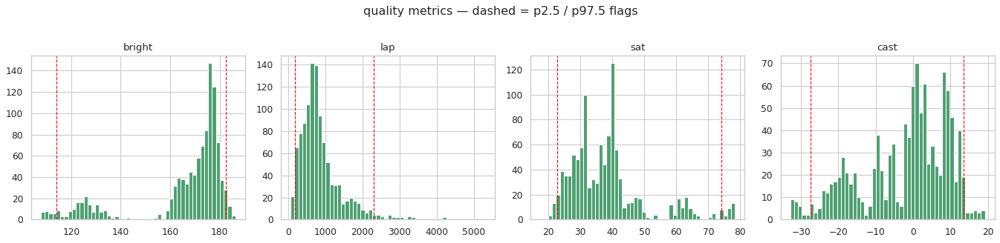

flagged images: 78 / 1084

flag rate per split (clustering in eval splits would be a problem):
split
test     14.3
train     7.2
valid     4.0


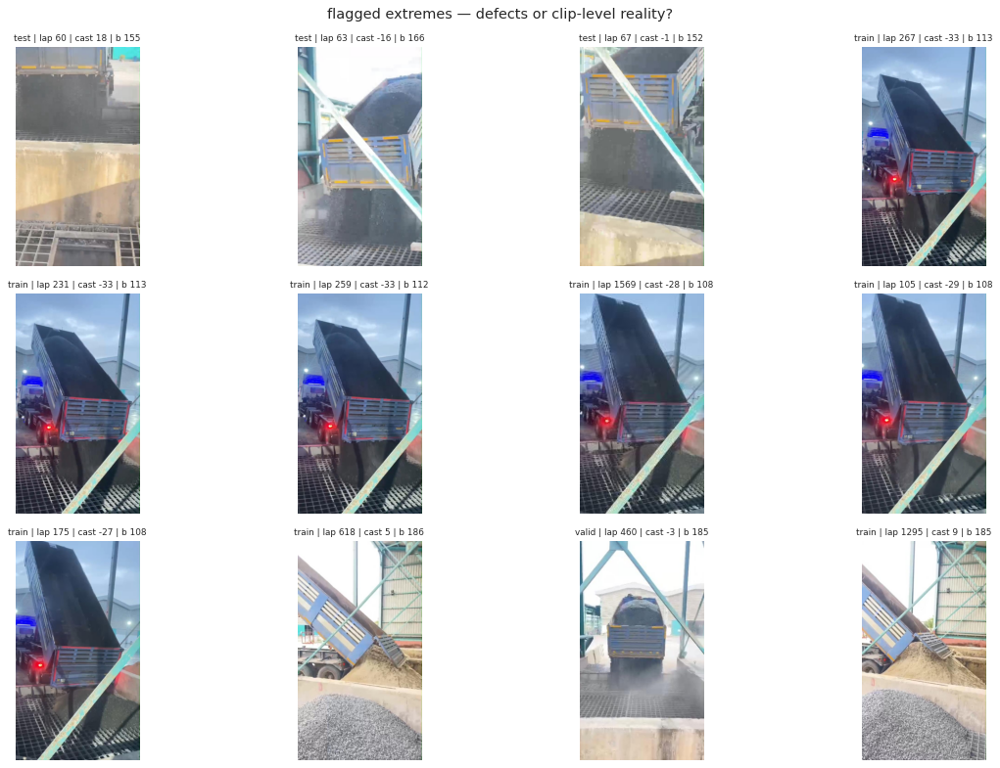

In [34]:
# ============================================================
# 9.1 QUALITY SCORECARD — blur / cast / brightness / saturation
# ============================================================
# MEASURE CELL — flags candidates for inspection, changes nothing.

qrows = []
for split in SPLITS:
    for p in sorted((GOLD_DIR / split / "images").iterdir()):
        img = np.asarray(Image.open(p).convert("RGB"))
        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY).astype(np.float64)
        qrows.append({
            "split": split, "image": p.name,
            "bright": float(gray.mean()),
            "lap":    float(cv2.Laplacian(gray, cv2.CV_64F).var()),
            "sat":    float(cv2.cvtColor(img, cv2.COLOR_RGB2HSV)[:, :, 1].mean()),
            "cast":   float(img[:, :, 0].mean() - img[:, :, 2].mean()),  # R-B
        })
df_q = pd.DataFrame(qrows)

# ---- distributions + percentile flags -------------------------
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, col in zip(axes, ["bright", "lap", "sat", "cast"]):
    ax.hist(df_q[col], bins=50, color="#4c9f70", edgecolor="white")
    for q in (0.025, 0.975):
        ax.axvline(df_q[col].quantile(q), color="red", ls="--", lw=1)
    ax.set_title(col)
plt.suptitle("quality metrics — dashed = p2.5 / p97.5 flags", y=1.02)
plt.tight_layout()
plt.show()

flags = ((df_q["lap"] < df_q["lap"].quantile(0.025))
         | (df_q["bright"] < df_q["bright"].quantile(0.025))
         | (df_q["bright"] > df_q["bright"].quantile(0.975))
         | (df_q["cast"].abs() > 30))
print(f"flagged images: {int(flags.sum())} / {len(df_q)}")
print("\nflag rate per split (clustering in eval splits would be a problem):")
print((df_q.assign(f=flags).groupby("split")["f"].mean() * 100).round(1).to_string())

# ---- eyeball the flagged extremes -----------------------------
worst = pd.concat([
    df_q.nsmallest(3, "lap"),
    df_q.reindex(df_q["cast"].abs().sort_values(ascending=False).index).head(3),
    df_q.nsmallest(3, "bright"),
    df_q.nlargest(3, "bright"),
]).drop_duplicates("image")
n = len(worst)
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, (_, r) in zip(axes.flat, worst.iterrows()):
    ax.imshow(Image.open(GOLD_DIR / r["split"] / "images" / r["image"]))
    ax.set_title(f'{r["split"]} | lap {r["lap"]:.0f} | cast {r["cast"]:.0f} | '
                 f'b {r["bright"]:.0f}', fontsize=8)
    ax.axis("off")
for ax in axes.flat[n:]:
    ax.axis("off")
plt.suptitle("flagged extremes — defects or clip-level reality?", fontsize=13)
plt.tight_layout()
plt.show()

### 9.2 ข้อสรุปเดิม — บันทึก flags ไม่ลบข้อมูล

ผลในส่วน 9.1 วัดจากภาพ gold เดิม 1,089 ภาพ:

- **blur** — ภาพแย่ที่สุดมี lap ≈60–115 เทียบ median ~715 อยู่ใน 2 คลิป (`f9b12ec3…`, `07451999…`) เป็น blur จากการถ่ายจริง ไม่ใช่ annotation noise จึง **เก็บ** และบันทึกใน `quality_flags.csv` เพื่อประเมินแยกคลิป
- **cast** — สีฟ้าเด่น (R−B ≈−33) อยู่คลิปเดียว (`07451999…`); |cast|>30 พบ ~2% การแก้ gray-world ทั้งชุดอาจเปลี่ยนสีที่แยก gravel/sand จึง **ไม่ใช้** แต่บันทึกไว้
- **brightness** — สุดโต่งจากแสงระดับคลิป ไม่ใช่ outlier สุ่ม จึงเก็บ; CLAHE variant ช่วยชดเชยบางส่วน
- **saturation** — การกระจายยอดเดียว ไม่มีปลายที่ผิดปกติ จึงไม่แก้

**ข้อกำหนด:** ไม่ลบ และไม่แก้ photometric ทั้งชุด `quality_flags.csv` เก็บ metrics รายภาพเพื่อ audit ในวิทยานิพนธ์และประเมินแยกคลิป

In [35]:
# ============================================================
# 9.2 WRITE quality_flags.csv — audit trail, no data changed
# ============================================================
# ACTION CELL — runs only after the 9.2 decision above.

df_q["flag_blur"]   = df_q["lap"]    < df_q["lap"].quantile(0.025)
df_q["flag_dark"]   = df_q["bright"] < df_q["bright"].quantile(0.025)
df_q["flag_bright"] = df_q["bright"] > df_q["bright"].quantile(0.975)
df_q["flag_cast"]   = df_q["cast"].abs() > 30

# use merged_group (uuid + dHash) — same clip identity as the gold split
df_q = df_q.merge(df_imgs[["image", "merged_group"]], on="image", how="left")

out = AUDIT_OUT / "quality_flags.csv"
df_q.to_csv(out, index=False)

FLAG_COLS = ["flag_blur", "flag_dark", "flag_bright", "flag_cast"]
print(df_q[FLAG_COLS].sum().to_string())
print("\nflag count per merged_group (top 8 — clip-level defects, not random):")
print(df_q.assign(any_f=df_q[FLAG_COLS].any(axis=1))
          .groupby("merged_group")["any_f"].sum()
          .sort_values(ascending=False).head(8).to_string())
print(f"\nwritten: {out}")

flag_blur      28
flag_dark      28
flag_bright    28
flag_cast      23

flag count per merged_group (top 8 — clip-level defects, not random):
merged_group
fa45e6fb-4502-41bb-bb80-a4a4149318ad    32
4a7f29af-8d1c-4a3b-90e6-b9cf771fd1c2    19
f9b12ec3-0036-45f7-8cc3-4d2e6f481cdc    15
96ecd4fe-5910-4cd4-8a24-11ed20aab3b7     9
8f435cb5-02c7-452a-a971-cef315681c19     3
2f4b2f2f-9d1c-4a87-b5eb-75cd2824d881     0
0a48349e-f671-436a-8af5-de54f079109f     0
1991989f-1bf5-4e50-89bb-7301b220ac01     0

written: /home/supawich/Desktop/Aggregate_Project/experiment/results/nb00_audit/20261013T053359228548Z/quality_flags.csv


## 10. Offline augmentation — ประวัติการขยายชุดข้อมูล

ส่วนนี้เป็นสูตรเก่าของ `gold_aug` ไม่ใช่โปรโตคอล CV ปัจจุบัน ให้ใช้ส่วน 17 สำหรับการแบ่ง group ก่อน augmentation ชุด test เดิมไม่ถือเป็น untouched confirmatory test

Offline expansion สร้าง **ภาพใหม่และ label ที่ปรับพิกัดแล้ว** ไป `data/gold_aug/` โดยไม่เปลี่ยนต้นฉบับหรือเขียนทับ

**ตัวเลือก transform เดิม:**
- *geometric* — ต้อง remap polygon: `hflip`, หมุน ±12°, scale 0.8–1.25, translate ±8% ไม่ใช้ `vflip` เพราะกองวัสดุขึ้นกับแรงโน้มถ่วง และไม่ใช้ perspective/shear
- *photometric* — copy label เดิม: HSV jitter เล็กน้อย โดยจำกัด hue เพราะใช้แยก gravel/sand, gamma ±20%, brightness ±15%, CLAHE p=0.3 และ Gaussian blur/noise p=0.15 เป็นตัวเลือก robustness ไม่ใช่ผลยืนยันว่าดีขึ้น
- *environmental* — copy label เดิม: **dark** (gamma 1.4–2.2) และ **rain** (เส้นฝน + blur/brightening เล็กน้อย) จำลองสภาพที่ชุด auto-label ขาด โดยยังต้องวัดผลต่อ task

**ไม่ใช้:** offline mosaic/copy-paste สูตรเก่าอ้างอิง mosaic แบบ online ของ Ultralytics; copy-paste ถูกตัดเพราะกองที่แปะดูไม่สมจริง ส่วน CV ใหม่ปิด online augmentation เอกสารอ้างอิงอยู่ส่วน 13

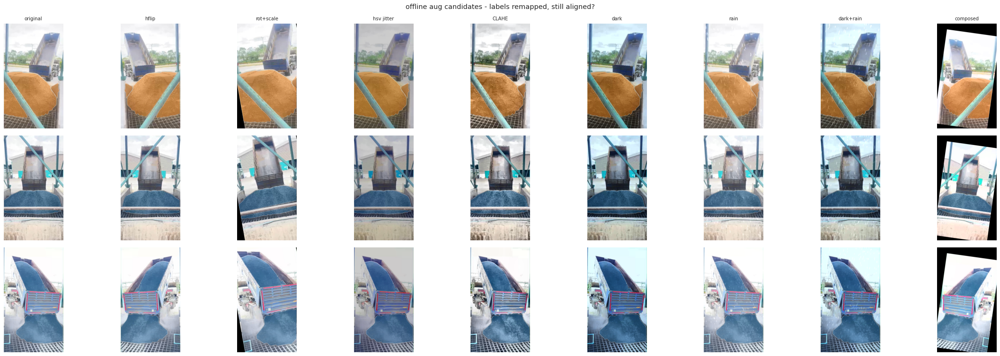

images tested         : 60
instances before      : 220
instances after       : 213 (96.8% survive clip+drops)
coord-range violations: 0 images


In [36]:
# ============================================================
# 10.1 AUG TRANSFORMS — visualize + check label integrity
# ============================================================
# VIZ/MEASURE CELL — no files written. Every geometric transform
# remaps the polygon coords; integrity is asserted after each op.

def load_polys(lbl_path):
    out = []
    if lbl_path.exists():
        for line in lbl_path.read_text().splitlines():
            parts = line.split()
            out.append((int(parts[0]),
                        np.array(list(map(float, parts[1:]))).reshape(-1, 2)))
    return out

def aug_hflip(img, polys):
    return cv2.flip(img, 1), [(c, np.c_[1 - p[:, 0], p[:, 1]]) for c, p in polys]

def aug_affine(img, polys, deg, scale, tx, ty):
    """rotate/scale/translate about image center; coords remapped in px space."""
    h, w = img.shape[:2]
    M = cv2.getRotationMatrix2D((w / 2, h / 2), deg, scale)
    M[:, 2] += [tx * w, ty * h]
    out = cv2.warpAffine(img, M, (w, h), borderMode=cv2.BORDER_CONSTANT)
    newp = []
    for c, p in polys:
        px = np.c_[p * [w, h], np.ones(len(p))] @ M.T          # to px, affine
        newp.append((c, np.clip(px / [w, h], 0.0, 1.0)))       # back to norm, clip
    return out, newp

def aug_hsv(img, polys, dh, ds, dv):
    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV).astype(np.int16)
    hsv[:, :, 0] = (hsv[:, :, 0] + dh) % 180
    hsv[:, :, 1] = np.clip(hsv[:, :, 1] * (1 + ds), 0, 255)
    hsv[:, :, 2] = np.clip(hsv[:, :, 2] * (1 + dv), 0, 255)
    return cv2.cvtColor(hsv.astype(np.uint8), cv2.COLOR_HSV2RGB), polys

def aug_dark(img, g, blue=0.10):
    """low-light variant: gamma darken (g>1) + slight cool shift."""
    lut = ((np.arange(256) / 255.0) ** g * 255).astype(np.uint8)
    out = cv2.LUT(img, lut).astype(np.float32)
    out[:, :, 0] *= (1 - blue)          # pull red down
    out[:, :, 2] *= (1 + blue * 0.5)    # cool tint
    return np.clip(out, 0, 255).astype(np.uint8)

def aug_rain(img, rng, density=0.0006, angle_deg=None, length=None):
    """rain-streak overlay + wet-sheen: thin bright strokes along a slanted
    direction, then slight blur + brightness lift."""
    h, w = img.shape[:2]
    overlay = np.zeros_like(img)
    n = int(h * w * density)
    ang = np.deg2rad(angle_deg if angle_deg is not None else rng.uniform(75, 105))
    dx, dy = np.cos(ang), np.sin(ang)
    for _ in range(n):
        x0, y0 = rng.integers(0, w), rng.integers(0, h)
        L = length if length is not None else rng.uniform(8, 22)
        cv2.line(overlay, (int(x0), int(y0)),
                 (int(x0 + dx * L), int(y0 + dy * L)),
                 (int(rng.uniform(160, 220)),) * 3, 1, cv2.LINE_AA)
    img = cv2.addWeighted(img, 1.0, cv2.GaussianBlur(overlay, (3, 3), 0), 0.6, 4)
    return cv2.GaussianBlur(img, (3, 3), 0)

def clean_polys(polys, min_area=1e-5):
    """drop instances that clipping degraded below tiny-mask threshold."""
    keep = []
    for c, p in polys:
        p = np.clip(p, 0.0, 1.0)
        if len(np.unique(p, axis=0)) < 3:
            continue
        if shoelace_area(p[:, 0], p[:, 1]) < min_area:
            continue
        keep.append((c, p))
    return keep

# ---- visual check ----------------------------------------------
demo = [
    ("original",   lambda i, p: (i, p)),
    ("hflip",      aug_hflip),
    ("rot+scale",  lambda i, p: aug_affine(i, p, deg=10, scale=1.15, tx=0.05, ty=-0.03)),
    ("hsv jitter", lambda i, p: aug_hsv(i, p, dh=6, ds=0.25, dv=-0.20)),
    ("CLAHE",      lambda i, p: (clahe_lab(i), p)),
    ("dark",       lambda i, p: (aug_dark(i, g=1.8), p)),
    ("rain",       lambda i, p: (aug_rain(i, np.random.default_rng(3)), p)),
    ("dark+rain",  lambda i, p: (aug_rain(aug_dark(i, g=1.6),
                   np.random.default_rng(5)), p)),
    ("composed",   lambda i, p: aug_hsv(*aug_affine(*aug_hflip(i, p), deg=-8,
                   scale=0.9, tx=0, ty=0.04), dh=-4, ds=0.15, dv=0.15)),
]

sample_rows = df_imgs[df_imgs["new_split"] == "train"].sample(3, random_state=7)
fig, axes = plt.subplots(len(sample_rows), len(demo),
                         figsize=(3.2 * len(demo), 3.2 * len(sample_rows)))
for row, (_, r) in enumerate(sample_rows.iterrows()):
    img = np.asarray(Image.open(GOLD_DIR / "train" / "images" / r["image"]).convert("RGB"))
    h, w = img.shape[:2]
    polys = load_polys(GOLD_DIR / "train" / "labels" / (Path(r["image"]).stem + ".txt"))
    for col, (name, fn) in enumerate(demo):
        out_img, out_p = fn(img, polys)
        out_p = clean_polys(out_p)
        axes[row, col].imshow(out_img)
        for c, pp in out_p:
            axes[row, col].add_patch(MplPolygon(
                pp * [w, h], closed=True, fill=True, alpha=0.35,
                facecolor=CLASS_COLORS[CLASS_NAMES[c]], edgecolor="white", lw=0.7))
        axes[row, col].set_title(name if row == 0 else "", fontsize=9)
        axes[row, col].axis("off")
plt.suptitle("offline aug candidates - labels remapped, still aligned?", fontsize=13)
plt.tight_layout(); plt.show(); plt.close("all")

# ---- integrity measure over 60 train images ---------------------
rng = np.random.default_rng(21)
rows = []
pool = df_imgs[df_imgs["new_split"] == "train"].sample(60, random_state=21)
for _, r in pool.iterrows():
    polys = load_polys(GOLD_DIR / "train" / "labels" / (Path(r["image"]).stem + ".txt"))
    img = np.asarray(Image.open(GOLD_DIR / "train" / "images" / r["image"]).convert("RGB"))
    out_img, out_p = aug_affine(img, polys,
                                deg=rng.uniform(-12, 12), scale=rng.uniform(0.8, 1.25),
                                tx=rng.uniform(-0.08, 0.08), ty=rng.uniform(-0.08, 0.08))
    kept = clean_polys(out_p)
    ok = all((pp >= 0).all() and (pp <= 1).all() for _, pp in kept)
    rows.append({"n_before": len(polys), "n_after": len(kept), "coords_ok": ok})
chk = pd.DataFrame(rows)
print(f"images tested         : {len(chk)}")
print(f"instances before      : {chk['n_before'].sum()}")
print(f"instances after       : {chk['n_after'].sum()} "
      f"({chk['n_after'].sum()/max(chk['n_before'].sum(),1)*100:.1f}% survive clip+drops)")
print(f"coord-range violations: {int((~chk['coords_ok']).sum())} images")

### 10.2 สูตรเดิม — `data/gold_aug/` (เพิ่ม 3 variants ต่อภาพ train)

ตัวอย่างในส่วน 10.1 ตรวจการจัดแนว label หลัง remap และ clipping ที่ตัด sliver เสื่อมสภาพตาม `min_area=1e-5` เป็นหลักฐานเฉพาะกรณีที่ตรวจ ไม่ใช่การรับรองทุกไฟล์

**พารามิเตอร์เดิม:**
- **K=3**: train 753 → 3,012 ภาพ (4 เท่า); `aug1`/`aug2` ผสม geometric+photometric; **`aug3` เป็น environmental variant** ใช้ dark p=0.5 และ/หรือ rain p=0.5 โดยต้องมีอย่างน้อยหนึ่งแบบ
- geometric: `hflip` p=0.5; หมุน `U(-12,+12)` องศา, scale `U(0.8,1.25)`, translate `U(-0.08,+0.08)` รวมผ่าน `aug_affine` p=0.6
- photometric: HSV dh=U(-7,+7), ds/dv=U(-0.25,+0.25), p=0.6; gamma U(0.8,1.25), p=0.4; **CLAHE(2.0,8x8), p=0.3**; Gaussian blur sigma U(0.1,1.2), p=0.15
- บันทึก operations ราย variant ใน `aug_log.csv`
- copy `valid`/`test` โดยไม่เปลี่ยน เพื่อให้ gold_aug ใช้งานได้ในตัว
- ไม่ใช้ vflip หรือ offline mosaic/copy-paste ตามสูตรเดิมใน `train.yaml`

สูตรนี้เป็นประวัติ ไม่ใช้แทน fold-local augmentation ในส่วน 17

### Builder offline เดิม — ปิดใช้งาน

Action cell เดิมลบไดเรกทอรีแล้วสร้าง `data/gold_aug` ใหม่แม้ในโหมด audit จึงถอดออกจากโค้ดที่รันได้ เก็บ artifacts เดิมไว้โดยไม่แก้ และไม่ถือว่า lineage/geometry เก่าผ่านโปรโตคอล grouped CV ใหม่

ใช้ builder แบบ versioned ไม่เขียนทับและแยกแต่ละ fold ในส่วน 17 แทน โดยใช้ `gold_fixed_v1` แบ่ง group ก่อน augmentation และคง inner-valid/outer-heldout เดิม ไม่ลบหรือเขียนทับชุดข้อมูลที่มีอยู่

## 11. คุณภาพขอบเขตและ coverage — ตรวจ label noise ที่เหลือ

หลังตรวจ degenerate/duplicate/tiny ในขั้น silver ยังมีการตรวจแบบไม่ใช้โมเดลก่อน train:
- **vertex density** = `n_vertices / sqrt(area_px)` ค่าต่ำอาจเป็น polygon หยาบเกิน; ค่าสูงอาจเป็นขอบหยัก/noise
- **mask coverage** = สัดส่วนพื้นที่ที่มี label ภาพที่ coverage ต่ำผิดปกติอาจขาด annotation; coverage เกือบเต็มอาจเป็นบริเวณเดียวครอบทุกอย่าง

Percentile flags ใช้คัดกรณีให้ผู้ตรวจดู ไม่ใช่กฎลบข้อมูล

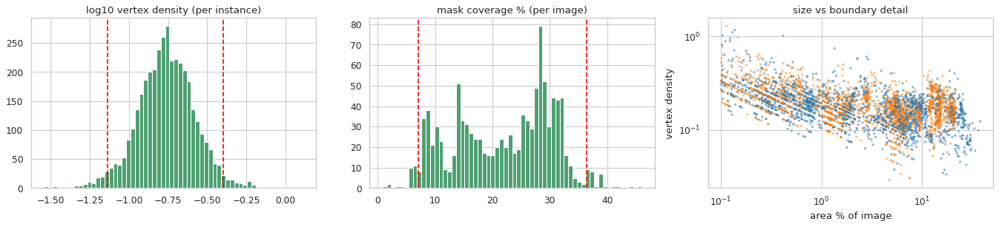

over-smoothed inst : 97
jagged inst        : 97
coverage-low imgs  : 28
coverage-high imgs : 28


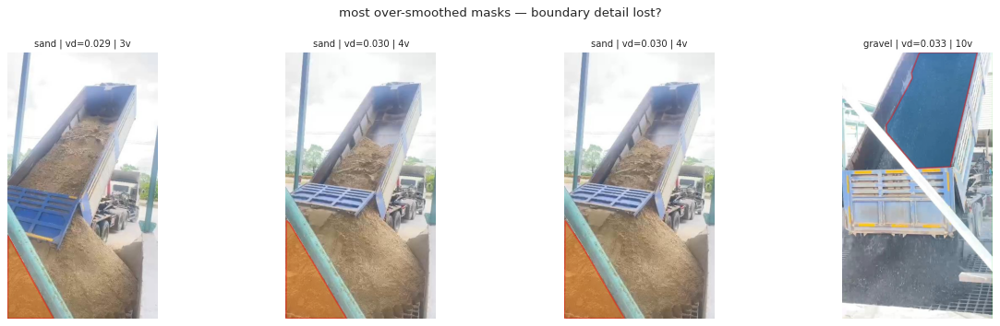

In [38]:
# ============================================================
# 11.1 BOUNDARY + COVERAGE SCORECARD
# ============================================================
# MEASURE CELL — computes flags + plots, writes nothing.

inst_b = df_gold.copy()
inst_b["v_density"] = inst_b["n_vertices"] / np.sqrt(inst_b["area_px"].clip(lower=1))

cov = (df_gold.groupby(["new_split", "image"])["area_norm"].sum()
       .rename("coverage").reset_index())

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
axes[0].hist(np.log10(inst_b["v_density"].clip(lower=1e-3)), bins=60,
             color="#4c9f70", edgecolor="white")
axes[0].set_title("log10 vertex density (per instance)")
for q in (0.025, 0.975):
    axes[0].axvline(np.log10(inst_b["v_density"].quantile(q)), color="red", ls="--")

axes[1].hist(cov["coverage"] * 100, bins=60, color="#4c9f70", edgecolor="white")
axes[1].set_title("mask coverage % (per image)")
axes[1].axvline(cov["coverage"].quantile(0.025) * 100, color="red", ls="--")
axes[1].axvline(cov["coverage"].quantile(0.975) * 100, color="red", ls="--")

axes[2].scatter(inst_b["area_norm"] * 100, inst_b["v_density"],
                c=[CLASS_COLORS[c] for c in inst_b["class"]], s=4, alpha=0.4)
axes[2].set(xscale="log", yscale="log", xlabel="area % of image",
            ylabel="vertex density", title="size vs boundary detail")
plt.tight_layout(); plt.show(); plt.close("all")

vlo, vhi = inst_b["v_density"].quantile([0.025, 0.975])
inst_b["flag_smooth"] = inst_b["v_density"] < vlo
inst_b["flag_jagged"] = inst_b["v_density"] > vhi
cov["flag_cov_low"]  = cov["coverage"] < cov["coverage"].quantile(0.025)
cov["flag_cov_high"] = cov["coverage"] > cov["coverage"].quantile(0.975)
print(f"over-smoothed inst : {int(inst_b['flag_smooth'].sum())}")
print(f"jagged inst        : {int(inst_b['flag_jagged'].sum())}")
print(f"coverage-low imgs  : {int(cov['flag_cov_low'].sum())}")
print(f"coverage-high imgs : {int(cov['flag_cov_high'].sum())}")

show_i = inst_b.nsmallest(4, "v_density")
fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
for ax, (_, r) in zip(axes, show_i.iterrows()):
    img = np.asarray(Image.open(GOLD_DIR / r["new_split"] / "images" / r["image"]).convert("RGB"))
    h, w = img.shape[:2]
    ax.imshow(img)
    ax.add_patch(MplPolygon(np.asarray(r["poly"]) * [w, h], closed=True, fill=True,
                            alpha=0.4, facecolor=CLASS_COLORS[r["class"]],
                            edgecolor="red", lw=1.5))
    ax.set_title(f'{r["class"]} | vd={r["v_density"]:.3f} | {r["n_vertices"]}v', fontsize=9)
    ax.axis("off")
plt.suptitle("most over-smoothed masks — boundary detail lost?", fontsize=12)
plt.tight_layout(); plt.show(); plt.close("all")

### 11.2 ข้อสรุป — บันทึก flags ไม่ลบข้อมูล

- ปลายการกระจาย vertex density พบได้ใน auto-label: กองรูปร่างเรียบอาจมี polygon หยาบ ส่วน texture จุดเล็กอาจให้ขอบหยัก ไม่ได้แปลว่าผิดเสมอ เพราะขอบกองจริงซับซ้อนต่างกัน
- coverage ต่ำอาจเป็นฉากที่มีวัสดุน้อย ส่วน coverage เกือบเต็มอาจเป็นกองเต็มเฟรม ทั้งสองกรณีเป็นไปได้
- **ข้อกำหนด:** ไม่ลบ `instance_flags.csv` และ coverage ที่รวมใน `quality_flags.csv` ใช้ประเมินแยก slice และคัดกรณีสำหรับ audit รอบสองด้วยโมเดลหลัง baseline training

In [39]:
# ============================================================
# 11.2 WRITE instance_flags.csv + merge coverage into quality_flags
# ============================================================
# ACTION CELL — audit artifacts only, images/labels unchanged.

inst_b[["image", "new_split", "class", "n_vertices", "area_norm",
        "v_density", "flag_smooth", "flag_jagged"]].to_csv(
    AUDIT_OUT / "instance_flags.csv", index=False)

qf = pd.read_csv(AUDIT_OUT / "quality_flags.csv")
qf = qf.merge(cov[["image", "coverage", "flag_cov_low", "flag_cov_high"]],
              on="image", how="left")
qf.to_csv(AUDIT_OUT / "quality_flags.csv", index=False)

print(f"instance_flags.csv: {len(inst_b)} rows "
      f"(smooth={int(inst_b['flag_smooth'].sum())}, jagged={int(inst_b['flag_jagged'].sum())})")
print(f"quality_flags.csv extended: +coverage/flags ({len(qf)} rows)")

instance_flags.csv: 3861 rows (smooth=97, jagged=97)
quality_flags.csv extended: +coverage/flags (1084 rows)


## 12. ทะเบียน seeds และ checksums ของชุดข้อมูล

บันทึก seed ของทุกการสุ่ม และ SHA256 ของไฟล์ข้อมูลที่สร้าง เพื่อให้ย้อนจากรูปในวิทยานิพนธ์ไปถึง bytes ที่ใช้ได้ ส่วนนี้เป็นการบันทึกสำหรับ reproducibility ไม่ใช่การตัดสินด้านวิธีวิจัย

In [40]:
# ============================================================
# 12.1 seeds.json + dataset_checksums.csv
# ============================================================
import json, hashlib

SEED_REGISTRY = {
    "gold_split":      42,   # cell 7.1 group assignment
    "contrast_sample": 11,   # cell 8.3 image sample
    "tiny_viz":        7,    # smallest-mask inspection sample
    "overlay_viz":     5,    # 8.4 alignment check sample
    "aug_viz":         7,    # 10.1 demo images
    "aug_integrity":   21,   # 10.1 integrity sample
    "aug_offline":     42,   # 10.2 variant sampling
    "leak_viz":        42,   # 6.1 leaked-group frame sample
    "train":           42,   # train.yaml seed — paired ablation
}
RES_DIR = AUDIT_OUT
RES_DIR.mkdir(exist_ok=True)
(RES_DIR / "seeds.json").write_text(json.dumps(SEED_REGISTRY, indent=2))

def sha256(p, buf=1 << 20):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for chunk in iter(lambda: f.read(buf), b""):
            h.update(chunk)
    return h.hexdigest()

rows = []
for d in (GOLD_DIR,
          EXP / "data" / "gold_clahe",
          EXP / "data" / "gold_aug"):
    if not d.exists():
        continue
    for f in sorted(d.rglob("*")):
        if f.is_file():
            rows.append({"dataset": d.name, "file": str(f.relative_to(d)),
                         "sha256": sha256(f)})
cs = pd.DataFrame(rows)
cs.to_csv(RES_DIR / "dataset_checksums.csv", index=False)
print(f"seeds.json: {len(SEED_REGISTRY)} seeds")
print(f"dataset_checksums.csv: {len(cs)} files across {cs['dataset'].nunique()} datasets")

seeds.json: 9 seeds
dataset_checksums.csv: 11038 files across 3 datasets


## 13. แนวทางตรวจด้วยคนและเอกสารอ้างอิง

**ประวัติการตรวจใน pipeline** สำหรับบันทึกวิทยานิพนธ์ ไม่ใช่ผลยืนยันจากผู้ตรวจอิสระ:

| flag | วิธีตรวจเดิม | กฎตัดสินเดิม |
|---|---|---|
| mask เสื่อมสภาพ | geometry validity ด้วย Shapely | ลบ geometry ที่ไม่ถูกต้อง |
| กลุ่มซ้ำ | ภาพซ้อน IoU/IoMin | คลาสเดียวกัน IoMin≥0.5 เก็บรูปใหญ่ที่สุด |
| mask เล็ก <0.1% | ดู crop 12 ตัวอย่าง | ตัดเป็น noise ที่ไม่เห็นวัตถุ |
| mask ยาว | ดู crop aspect สูงสุด 12 ตัวอย่าง | เก็บกองที่แผ่จริง |
| label ว่าง | ดูทั้ง 5 ภาพ | เก็บ background จริง |
| contrast | ดู crop 4 ภาพและ metrics 80 ภาพ | ใช้ CLAHE 2.0 เป็นแขนทดลอง A/B |
| blur/dark/cast | ดูภาพสุดโต่ง 12 ภาพ | บันทึก ไม่ลบอัตโนมัติ |
| vertex density/coverage | ดู crop แย่ที่สุด 4 ภาพ | บันทึก flags ไม่ลบอัตโนมัติ |

**เอกสารอ้างอิง**
- Zuiderveld (1994) — CLAHE, *Graphics Gems IV*
- Normalized-gamma CLAHE ใน Lab สำหรับภาพ sand-dust — *IET Image Processing* สนับสนุนการใช้ CLAHE บนช่อง L
- Zhang, Yin & Yan (2021) — instance segmentation ของวัสดุคล้ายทราย, *Automation in Construction* 133:103994 ใช้ copy-paste สังเคราะห์ label offline
- Bamford, Esmaeili & Schoellig (2021) — deep-learning rock fragmentation, *IJRMMS* 145:104839
- Ghiasi et al. (2021) — Simple Copy-Paste augmentation, *CVPR*
- Northcutt, Jiang & Chuang (2021) — Confident Learning, *JAIR* 71 แนวทาง audit รอบสองจาก model disagreement
- ASCE (2024) — SAM สำหรับอนุภาคทรายหนาแน่น ในบริบท noise ของ auto-label

In [41]:
# ============================================================
# 13.1 append review protocol to DATA_CARD.md
# ============================================================
card = AUDIT_OUT / "DATA_CARD.md"
extra = """
## Human review protocol
- every removal rule was inspected visually before application (EDA sections 3-4, 10-11)
- removal criteria limited to geometrically invalid or near-identical same-class duplicates
- all borderline flag classes (elongated, blurred, cast, coverage, boundary-density)
  were documented as flags, never auto-dropped
- residual noise: round-2 model-disagreement audit planned after baseline training

## Reproducibility artifacts
- seeds: results/seeds.json
- checksums: results/dataset_checksums.csv
- audit CSVs: split_audit.csv, quality_flags.csv, instance_flags.csv, aug_log.csv (gold_aug)
"""
with open(card, "a", encoding="utf-8") as f:
    f.write(extra)
print(f"appended -> {card}")

appended -> /home/supawich/Desktop/Aggregate_Project/experiment/results/nb00_audit/20261013T053359228548Z/DATA_CARD.md


## 14. สถานะหลักฐาน — มีโค้ดวิจัยไม่ได้แปลว่าผลวิทยานิพนธ์เสร็จแล้ว

Final audit ด้านล่างคำนวณจำนวนไฟล์จริง, quality flags อ้างอิง train, duplicate diagnostics, lineage และ handoff สำหรับ notebook 16 ใหม่ outputs ที่ฝังไว้ก่อนหน้าเป็นประวัติ อาจไม่ตรงกับโค้ด/ข้อมูลปัจจุบัน ไม่ยกคำอ้างเดิมเรื่อง untouched test, คลิป/ไซต์อิสระ, human review ครบ หรือ entropy ทำให้ task ดีขึ้น มาเป็นผลยืนยัน

หลักฐานที่ยังต้องทำ: ผู้ตรวจอิสระ adjudicate region labels, ความไวของ cleaning rules, baseline/ablation หลาย seeds, uncertainty ที่คำนึงถึง clusters และผล hardware/runtime จริงพร้อมผู้รับผิดชอบการใช้งาน การเก็บ metadata/เหตุการณ์ใหม่เลื่อนไว้ ไม่ใช่ gate ก่อน train สำหรับ grouped development CV นี้ ข้อมูลเดิมยังไม่พิสูจน์ generalization ไปเหตุการณ์/ไซต์ใหม่หรือ background ที่ไม่มีตัวอย่าง

## 14b. `gold_v2` เดิม — วิเคราะห์ย้อนหลังเท่านั้น

การแบ่งฉากให้สมดุลเดิมถูกเลือกหลังเห็นข้อผิดพลาด development-test และความกระจุกตัวคลาส/group จึงไม่ใช่ test อิสระใหม่ และห้ามยกเป็นผลหลักเพียงเพราะคะแนนดีขึ้น โค้ดด้านล่างบันทึก mapping ที่มีอยู่ ไม่สร้างหรือลบข้อมูล การประเมิน split เดิมเป็น development-inspected benchmark; แนวทาง CV ใหม่อยู่ส่วน 17 และต้องเปิดเผยข้อจำกัด

In [42]:
# ============================================================
# 14.1 BUILD GOLD_V2 — group-level reassignment, scene-balanced
# ============================================================
# Idempotent: rebuilds data/gold_v2 via hardlinks; writes
# group_table.csv + stem_to_split.csv + figs to results/resplit_v2/

GOLD = GOLD_DIR
V2 = EXP / 'data/gold_v2'
OUT = AUDIT_OUT
CLS = ['gravel','sand']
canonical = pd.read_csv(GOLD_DIR/'split_audit.csv').set_index('image')

def materialize_group_view(source,destination,assignment):
    destination = new_dataset_dir(destination)
    records = []
    for split in SPLITS:
        for kind in ('images','labels'): (destination/split/kind).mkdir(parents=True)
    for old in SPLITS:
        for ip in sorted((Path(source)/old/'images').iterdir()):
            group = canonical.loc[ip.name,'merged_group']
            new = assignment[group]
            assert new in SPLITS
            shutil.copy2(ip,destination/new/'images'/ip.name)
            shutil.copy2(Path(source)/old/'labels'/(ip.stem+'.txt'),destination/new/'labels'/(ip.stem+'.txt'))
            records.append(dict(image=ip.name,merged_group=group,new_split=new))
    pd.DataFrame(records).to_csv(destination/'split_audit.csv',index=False)
    (destination/'data.yaml').write_text(f'path: {destination}\ntrain: train/images\nval: valid/images\ntest: test/images\nnames: {CLASS_NAMES}\n')
    return destination

# ---- per-uuid-group table --------------------------------------
# ---- assignment: keep groups atomic; spread sand+gravel scenes --
# ---- integrity checks ------------------------------------------
# ---- materialize gold_v2 (hardlinks, fallback copy) ------------
# ---- Fig A: split composition old vs new -----------------------
# ---- Fig B: per-group composition per split --------------------
if V2.exists():
    rows = []
    for split in SPLITS:
        for ip in (V2/split/'images').iterdir():
            rows.append(dict(image=ip.name,group=canonical.loc[ip.name,'merged_group'],split=split))
    v2_audit = pd.DataFrame(rows)
    violations = v2_audit.groupby('group').split.nunique()
    v2_audit.to_csv(AUDIT_OUT/'historical_gold_v2_mapping.csv',index=False)
    print('Historical gold_v2 merged groups crossing splits:', int((violations>1).sum()))
    print('Historical post-hoc split: not promoted to an independent test.')
else: print('gold_v2 unavailable; primary grouped gold remains unchanged.')

Historical gold_v2 merged groups crossing splits: 0
Historical post-hoc split: not promoted to an independent test.


## 15. `gold_ws` เดิม — วิเคราะห์คลิปที่เคยเห็น ไม่ใช่ทดสอบ generalization

มุมมอง strided เดิมอาจให้เฟรมใกล้กันของ source group เดียวอยู่หลาย partitions วัด interpolation ภายในคลิปที่คุ้นเคย คะแนนอาจสูงเกินจริงเพราะเฟรม/background สัมพันธ์กัน ไม่ใช่ theoretical ceiling และไม่ยืนยันว่า deployment ให้ผลเท่ากัน

Cell ถัดไปตรวจไฟล์เดิมโดยไม่สร้างใหม่ notebook 16 ไม่ดึง cache/checkpoint ของชุดนี้มาเป็น grouped benchmark ผล LOGO/group-CV ต้องมี provenance การฝึกและประเมินของตัวเอง การมีไดเรกทอรีไม่ได้ยืนยันผล

In [43]:
# ============================================================
# 15.1 BUILD GOLD_WS — per-video 70/20/10 strided split
# ============================================================
# Idempotent: rebuilds data/gold_ws via hardlinks.

# collect all frames grouped by uuid, sorted for deterministic stride
# ---- audit -----------------------------------------------------
WS = EXP / 'data/gold_ws'
rows = []
if WS.exists():
    for split in SPLITS:
        for ip in (WS/split/'images').iterdir():
            lt = WS/split/'labels'/(ip.stem+'.txt')
            counts=[0,0]
            for line in lt.read_text().splitlines(): counts[int(line.split()[0])] += 1
            rows.append(dict(image=ip.name,group=canonical.loc[ip.name,'merged_group'],split=split,gravel=counts[0],sand=counts[1]))
    ws_audit=pd.DataFrame(rows)
    print(ws_audit.groupby('split').agg(images=('image','size'),gravel=('gravel','sum'),sand=('sand','sum')))
    print('Merged groups crossing splits:', int((ws_audit.groupby('group').split.nunique()>1).sum()))
    ws_audit.to_csv(AUDIT_OUT/'historical_seen_clip_mapping.csv',index=False)
print('gold_ws is a seen-clip diagnostic only. No dataset was rebuilt or deleted.')

       images  gravel  sand
split                      
test       88     181    99
train     812    1303  1627
valid     184     303   348
Merged groups crossing splits: 13
gold_ws is a seen-clip diagnostic only. No dataset was rebuilt or deleted.


## 16. ตรวจไฟล์จริงเป็นหลัก และ handoff `00 → 16`

รันส่วนนี้หลัง setup cell index 1 ได้โดยไม่ต้องรัน EDA เก่า อ่าน `data/gold_fixed_v1` และ merged-group mapping ที่มีอยู่ ไม่สร้างใหม่ ไม่เปลี่ยน label ไม่แบ่งใหม่ และไม่ลบ คำนวณ distribution/quality/identity จากไฟล์จริงแทนการคัดลอก outputs เก่า

ลำดับ: image/label/geometry contract → quality flags อ้างอิง train และ raster union coverage → exact/near-duplicate → ความกระจุกตัวคลาส/group และ negative scenes → sensitivity/คิวผู้ตรวจ → checksum-bound handoff → notebook 16 Hash ยืนยัน provenance ไม่ยืนยันความถูกต้องของ annotation dHash เป็น candidate ให้ตรวจ ไม่ใช่หลักฐานว่าเป็นการถ่ายเดียวกัน Metadata เหตุการณ์/ไซต์และ label ใหม่ยังเลื่อนไว้

In [2]:
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import importlib.metadata
from pathlib import Path
import hashlib,json,platform

FINAL_DATA=EXP/'data/gold_fixed_v1'
FINAL_CLASSES=['gravel','sand']
FINAL_SPLITS=['train','valid','test']
def audit_sha(path):
    h=hashlib.sha256()
    with open(path,'rb') as stream:
        for block in iter(lambda:stream.read(1<<20),b''): h.update(block)
    return h.hexdigest()
def audit_json(path,value):
    Path(path).write_text(json.dumps(value,indent=2,allow_nan=False,default=lambda x:x.item() if isinstance(x,np.generic) else str(x)),encoding='utf-8')
def audit_fig(name):
    plt.gcf().savefig(AUDIT_OUT/(name+'.pdf'),bbox_inches='tight')
    plt.gcf().savefig(AUDIT_OUT/(name+'.png'),dpi=300,bbox_inches='tight')
    plt.show(); plt.close()
try:
    from shapely.geometry import Polygon as AuditPolygon
    GEOMETRY_STATUS='shapely validity checked'
except ImportError:
    AuditPolygon=None; GEOMETRY_STATUS='PENDING: shapely missing; raster/coordinate checks only'

audit_mapping=pd.read_csv(FINAL_DATA/'split_audit.csv')
assert {'image','new_split','merged_group'} <= set(audit_mapping) and audit_mapping.image.is_unique
assert audit_mapping[['image','new_split','merged_group']].notna().all().all()
audit_mapping=audit_mapping.set_index('image')
manifest_rows=[]; quality_rows=[]; instance_rows=[]; hash_rows=[]
for split in FINAL_SPLITS:
    ips=sorted(p for p in (FINAL_DATA/split/'images').iterdir() if p.suffix.lower() in {'.jpg','.jpeg','.png','.bmp'})
    assert ips, f'Empty split: {split}'
    assert len({p.stem for p in ips})==len(ips)
    assert {p.stem for p in ips}=={p.stem for p in (FINAL_DATA/split/'labels').glob('*.txt')}
    for ip in ips:
        assert ip.name in audit_mapping.index and audit_mapping.loc[ip.name,'new_split']==split
        image=cv2.imread(str(ip)); assert image is not None, f'Image decode failed: {ip}'
        h,w=image.shape[:2]; lt=FINAL_DATA/split/'labels'/(ip.stem+'.txt')
        counts=[0,0]; unions=[np.zeros((h,w),bool) for _ in FINAL_CLASSES]
        for line_id,line in enumerate(lt.read_text().splitlines(),1):
            parts=line.split(); assert len(parts)>=7 and (len(parts)-1)%2==0, f'Malformed label: {lt}:{line_id}'
            c=int(parts[0]); xy=np.asarray(parts[1:],float).reshape(-1,2)
            assert c in (0,1) and np.isfinite(xy).all() and ((xy>=0)&(xy<=1)).all()
            area=.5*abs(np.dot(xy[:,0],np.roll(xy[:,1],1))-np.dot(xy[:,1],np.roll(xy[:,0],1)))
            assert len(np.unique(xy,axis=0))>=3 and area>0
            valid=AuditPolygon(xy).is_valid if AuditPolygon else None
            mask=np.zeros((h,w),np.uint8); cv2.fillPoly(mask,[(xy*[w,h]).astype(np.int32)],1)
            assert mask.any(), f'Zero rasterized label: {lt}:{line_id}'
            counts[c]+=1; unions[c]|=mask.astype(bool)
            instance_rows.append(dict(image=ip.name,stem=ip.stem,split=split,group=str(audit_mapping.loc[ip.name,'merged_group']),cls=FINAL_CLASSES[c],line=line_id,area_norm=area,area_px=int(mask.sum()),vertices=len(xy),geometry_valid=valid))
        group=str(audit_mapping.loc[ip.name,'merged_group'])
        manifest_rows.append(dict(stem=ip.stem,image=ip.name,path=str(ip),split=split,group=group,image_sha=audit_sha(ip),label_sha=audit_sha(lt),height=h,width=w,gravel=counts[0],sand=counts[1]))
        gray=cv2.cvtColor(image,cv2.COLOR_BGR2GRAY); hsv=cv2.cvtColor(image,cv2.COLOR_BGR2HSV)
        quality_rows.append(dict(image=ip.name,stem=ip.stem,split=split,group=group,bright=float(gray.mean()),lap=float(cv2.Laplacian(gray,cv2.CV_64F).var()),sat=float(hsv[:,:,1].mean()),cast=float(image[:,:,2].mean()-image[:,:,0].mean()),coverage=float((unions[0]|unions[1]).mean()),cross_class_overlap=float((unions[0]&unions[1]).mean()),gravel_coverage=float(unions[0].mean()),sand_coverage=float(unions[1].mean()),decoded_sha=hashlib.sha256(image.tobytes()+str(image.shape).encode()).hexdigest()))
        thumbnail=cv2.resize(gray,(9,8),interpolation=cv2.INTER_AREA)
        dh=int.from_bytes(np.packbits((thumbnail[:,1:]>thumbnail[:,:-1]).ravel()).tobytes(),'big')
        hash_rows.append(dict(stem=ip.stem,image=ip.name,split=split,group=group,dhash=dh))
FINAL_MANIFEST=pd.DataFrame(manifest_rows); FINAL_QUALITY=pd.DataFrame(quality_rows); FINAL_INSTANCES=pd.DataFrame(instance_rows)
assert FINAL_MANIFEST.stem.is_unique
assert FINAL_MANIFEST.groupby('group').split.nunique().max()==1, 'Merged groups cross splits'
assert FINAL_MANIFEST.groupby('image_sha').split.nunique().max()==1, 'Exact bytes cross splits'
assert FINAL_QUALITY.groupby('decoded_sha').split.nunique().max()==1, 'Same decoded pixels cross splits'
if AuditPolygon:
    bad_geometry=FINAL_INSTANCES[FINAL_INSTANCES.geometry_valid==False]
    bad_geometry.to_csv(AUDIT_OUT/'invalid_geometry.csv',index=False)
    GEOMETRY_STATUS='shapely validity checked' if bad_geometry.empty else f'FAIL: {len(bad_geometry)} invalid polygons; see invalid_geometry.csv'
    print('Invalid polygons:',len(bad_geometry))
FINAL_ID=hashlib.sha256(FINAL_MANIFEST.sort_values('stem')[['stem','split','group','image_sha','label_sha']].to_csv(index=False).encode()).hexdigest()
train_quality=FINAL_QUALITY[FINAL_QUALITY.split=='train']; assert len(train_quality)
QUALITY_REFERENCE={k:{'low':float(train_quality[k].quantile(.025)),'high':float(train_quality[k].quantile(.975))} for k in ['bright','lap','sat','cast','coverage']}
FINAL_QUALITY['flag_blur']=FINAL_QUALITY.lap<QUALITY_REFERENCE['lap']['low']
FINAL_QUALITY['flag_dark']=FINAL_QUALITY.bright<QUALITY_REFERENCE['bright']['low']
FINAL_QUALITY['flag_bright']=FINAL_QUALITY.bright>QUALITY_REFERENCE['bright']['high']
FINAL_QUALITY['flag_cast']=(FINAL_QUALITY.cast<QUALITY_REFERENCE['cast']['low'])|(FINAL_QUALITY.cast>QUALITY_REFERENCE['cast']['high'])
FINAL_QUALITY['flag_cov_low']=FINAL_QUALITY.coverage<QUALITY_REFERENCE['coverage']['low']
FINAL_QUALITY['flag_cov_high']=FINAL_QUALITY.coverage>QUALITY_REFERENCE['coverage']['high']
FINAL_QUALITY['flag_cross_class']=FINAL_QUALITY.cross_class_overlap>0
FINAL_MANIFEST.to_csv(AUDIT_OUT/'final_manifest.csv',index=False)
FINAL_QUALITY.to_csv(AUDIT_OUT/'final_quality_flags.csv',index=False)
FINAL_INSTANCES.to_csv(AUDIT_OUT/'final_instances.csv',index=False)
audit_json(AUDIT_OUT/'quality_reference.json',dict(selected_on='train',thresholds=QUALITY_REFERENCE))
print('Current disk counts:',FINAL_MANIFEST.groupby('split').agg(images=('stem','size'),groups=('group','nunique'),gravel=('gravel','sum'),sand=('sand','sum')).to_string())
print('Identity:',FINAL_ID,'| geometry:',GEOMETRY_STATUS)

Invalid polygons: 0
Current disk counts:        images  groups  gravel  sand
split                              
test      105      12     189   159
train     753       7    1301  1550
valid     226       7     320   374
Identity: 9bf2fab6eb34eb82dc7c4aad4b4de736c217e203c2f0f7cb2e36c6118705b8b9 | geometry: shapely validity checked


### 16.1 การกระจายและความกระจุกตัว — เฟรมไม่ใช่ฉากอิสระ

แสดง **groups ที่มีแต่ละคลาส**, จำนวน instances และความกระจุกตัวต่อ group ไม่ดูเพียงยอดรวมที่สมดุล ค่า inverse Herfindahl `1/Σp_g²` ใช้สัดส่วน instances ของคลาสในแต่ละ group เป็นตัววิเคราะห์ความกระจุกตัว **ไม่ใช่** การคำนวณ sample size/power ทางสถิติ Quality thresholds มาจาก train เท่านั้น Raster union coverage ไม่เกิน 1 และไม่นับ polygon ที่ซ้อนกันซ้ำ COCO size bins ใช้พื้นที่ mask ในพิกเซลต้นฉบับ ไม่ใช่ภาพหลัง resize เข้า network

split    cls  instances  class_groups  largest_group_share  inverse_concentration
train gravel       1301             7             0.297463               5.395552
train   sand       1550             3             0.900645               1.224844
valid gravel        320             5             0.546875               2.128544
valid   sand        374             2             0.500000               2.000000
 test gravel        189             9             0.767196               1.672410
 test   sand        159             4             0.955975               1.093327


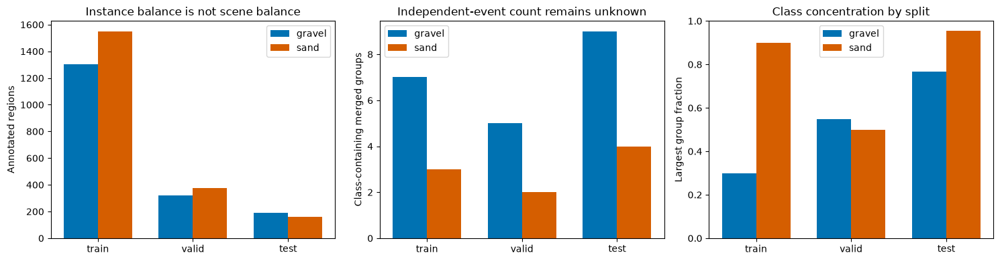

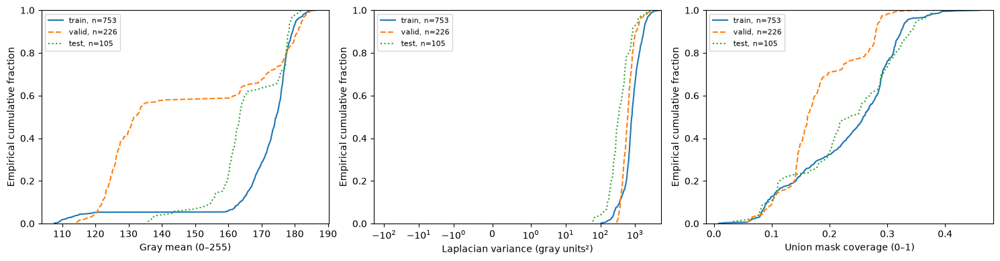

Negative/empty-label images: {'test': 0, 'train': 0, 'valid': 0}
GAP: background-only false positives cannot be estimated for every evaluation split.


In [3]:
composition=FINAL_MANIFEST.groupby(['split','group'])[['gravel','sand']].sum()
concentration=[]
for split in FINAL_SPLITS:
    for cn in FINAL_CLASSES:
        values=composition.loc[split,cn]; active=values[values>0]; shares=active/active.sum() if len(active) else active
        concentration.append(dict(split=split,cls=cn,instances=int(values.sum()),class_groups=len(active),largest_group_share=float(shares.max()) if len(active) else None,inverse_concentration=float(1/(shares**2).sum()) if len(active) else None))
CONCENTRATION=pd.DataFrame(concentration); CONCENTRATION.to_csv(AUDIT_OUT/'group_concentration.csv',index=False)
print(CONCENTRATION.to_string(index=False))
fig,axes=plt.subplots(1,3,figsize=(15,4))
for cn,color in zip(FINAL_CLASSES,['#0072B2','#D55E00']):
    sub=CONCENTRATION[CONCENTRATION.cls==cn].set_index('split').reindex(FINAL_SPLITS)
    offset=-.18 if cn=='gravel' else .18
    axes[0].bar(np.arange(3)+offset,sub.instances,width=.36,label=cn,color=color)
    axes[1].bar(np.arange(3)+offset,sub.class_groups,width=.36,label=cn,color=color)
    axes[2].bar(np.arange(3)+offset,sub.largest_group_share,width=.36,label=cn,color=color)
for ax in axes: ax.set_xticks(range(3),FINAL_SPLITS); ax.legend(); ax.set_ylim(bottom=0)
axes[0].set(ylabel='Annotated regions',title='Instance balance is not scene balance')
axes[1].set(ylabel='Class-containing merged groups',title='Independent-event count remains unknown')
axes[2].set(ylabel='Largest group fraction',ylim=(0,1),title='Class concentration by split')
plt.tight_layout(); audit_fig('group_support_and_concentration')
fig,axes=plt.subplots(1,3,figsize=(15,4))
for split,linestyle in zip(FINAL_SPLITS,['-','--',':']):
    sub=FINAL_QUALITY[FINAL_QUALITY.split==split]
    for ax,col,label in zip(axes,['bright','lap','coverage'],['Gray mean (0–255)','Laplacian variance (gray units²)','Union mask coverage (0–1)']):
        vals=np.sort(sub[col].to_numpy()); ax.plot(vals,np.arange(1,len(vals)+1)/len(vals),linestyle=linestyle,label=f'{split}, n={len(vals)}')
        ax.set(xlabel=label,ylabel='Empirical cumulative fraction',ylim=(0,1)); ax.legend(fontsize=8)
axes[1].set_xscale('symlog',linthresh=1); plt.tight_layout(); audit_fig('quality_ecdf_by_split')
size_rows=FINAL_INSTANCES.assign(size=pd.cut(FINAL_INSTANCES.area_px,[-1,1024,9216,np.inf],right=False,labels=['small','medium','large']))
size_table=size_rows.groupby(['split','cls','size'],observed=False).size().unstack(fill_value=0)
size_table.to_csv(AUDIT_OUT/'native_size_support.csv')
negatives=FINAL_MANIFEST.assign(background=(FINAL_MANIFEST.gravel+FINAL_MANIFEST.sand)==0).groupby('split').background.sum()
print('Negative/empty-label images:',negatives.to_dict())
if (negatives.reindex(['valid','test']).fillna(0)==0).any(): print('GAP: background-only false positives cannot be estimated for every evaluation split.')

### 16.2 ตรวจภาพซ้ำ ความไวของกฎ และคิวผู้ตรวจอิสระ

คู่ dHash near-duplicate ข้าม split ต้องตรวจ ไม่รวมเงียบ ๆ หลังเห็นผล test เก็บหลักฐานสองระดับ: exact byte/pixel separation เป็น hard gate และ perceptual similarity เป็น candidates การบีบอัดต่างกันอาจเปลี่ยน hash แม้เป็นเฟรมเดียวกัน

ตาราง tiny-area sensitivity นับบริเวณใน **gold ปัจจุบัน** เท่านั้น บริเวณ bronze ที่ถูกลบไปแล้วไม่อยู่ในตาราง หากรัน EDA เก่าจะบันทึก sensitivity ของกฎลบ/overlap ใน bronze ด้วย ผู้ตรวจอิสระต้องเทียบ annotation เดิมกับ candidate และ adjudicate ทั้งบริเวณ การมีคิวอย่างเดียวไม่ใช่ผล inter-annotator agreement

Cross-split perceptual review candidates: 2 (not automatic duplicate verdicts)


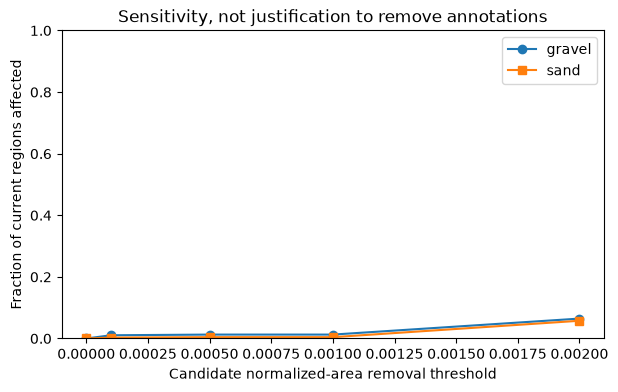

Independent reviewer queue regions: 542 | all decisions left blank intentionally.


In [4]:
near=[]
for i,left in enumerate(hash_rows):
    for right in hash_rows[i+1:]:
        if left['split']==right['split']: continue
        distance=(left['dhash']^right['dhash']).bit_count()
        if distance<=6:
            near.append(dict(left=left['image'],right=right['image'],left_split=left['split'],right_split=right['split'],left_group=left['group'],right_group=right['group'],hamming=distance,review_status='PENDING'))
NEAR_REVIEW=pd.DataFrame(near,columns=['left','right','left_split','right_split','left_group','right_group','hamming','review_status'])
NEAR_REVIEW.to_csv(AUDIT_OUT/'cross_split_near_duplicates.csv',index=False)
print('Cross-split perceptual review candidates:',len(NEAR_REVIEW),'(not automatic duplicate verdicts)')
sensitivity=[]
for threshold in [0.,.0001,.0005,.001,.002]:
    for cn in FINAL_CLASSES:
        sub=FINAL_INSTANCES[FINAL_INSTANCES.cls==cn]
        hit=sub[sub.area_norm<threshold]
        sensitivity.append(dict(dataset='current_gold',threshold=threshold,cls=cn,total=len(sub),affected=len(hit),groups=hit.group.nunique()))
if 'df' in globals() and {'area_norm','class'}<=set(df):
    for threshold in [0.,.0001,.0005,.001,.002]:
        for cn in FINAL_CLASSES:
            sub=df[df['class']==cn]
            sensitivity.append(dict(dataset='historical_bronze',threshold=threshold,cls=cn,total=len(sub),affected=int((sub.area_norm<threshold).sum()),groups=None))
SENSITIVITY=pd.DataFrame(sensitivity); SENSITIVITY.to_csv(AUDIT_OUT/'tiny_rule_sensitivity.csv',index=False)
if 'df_ov' in globals() and {'same_class','iomin','iou'}<=set(df_ov):
    overlap_sensitivity=pd.DataFrame([dict(metric=metric,threshold=t,pairs=int(((df_ov.same_class)&(df_ov[metric]>=t)).sum())) for metric in ['iou','iomin'] for t in [.3,.5,.7,.9]])
    overlap_sensitivity.to_csv(AUDIT_OUT/'overlap_rule_sensitivity.csv',index=False)
queue=FINAL_INSTANCES.merge(FINAL_QUALITY[['stem','flag_blur','flag_dark','flag_bright','flag_cast','flag_cross_class']],on='stem',validate='many_to_one')
queue['flag_tiny']=queue.area_norm<.001
flags=[c for c in queue if c.startswith('flag_')]
queue=queue[queue[flags].any(axis=1)].copy()
for col in ['reviewer_1','reviewer_2','decision_1','decision_2','adjudicated_decision','reason']: queue[col]=''
queue['label_sha']=queue.stem.map(FINAL_MANIFEST.set_index('stem').label_sha)
queue.to_csv(AUDIT_OUT/'independent_region_review_queue.csv',index=False)
fig,ax=plt.subplots(figsize=(7,4))
for cn,marker in zip(FINAL_CLASSES,['o','s']):
    sub=SENSITIVITY[(SENSITIVITY.dataset=='current_gold')&(SENSITIVITY.cls==cn)]
    ax.plot(sub.threshold,sub.affected/sub.total if sub.total.gt(0).all() else np.zeros(len(sub)),marker=marker,label=cn)
ax.set(xlabel='Candidate normalized-area removal threshold',ylabel='Fraction of current regions affected',ylim=(0,1),title='Sensitivity, not justification to remove annotations'); ax.legend(); audit_fig('tiny_threshold_sensitivity')
print('Independent reviewer queue regions:',len(queue),'| all decisions left blank intentionally.')

### 16.3 Handoff ผูกกับ checksum และขอบเขตข้อสรุป

Notebook 16 เลือก handoff ที่ตรงกับ dataset identity ที่คำนวณใหม่และตรวจ hash ของไฟล์ quality ไม่อ่าน flags เก่าจาก `data/gold/quality_flags.csv` โดยเงียบ ๆ Handoff แยก near-duplicate candidates และสถานะ geometry/human review ออกจาก mechanical validity

เอกสารอ้างอิงที่บันทึกว่าตรวจออนไลน์เมื่อ 2026-10-13: [REFORMS](https://www.science.org/doi/10.1126/sciadv.adk3452) สำหรับ leakage/reproducibility/uncertainty; [COCO](https://cocodataset.org/dataset/detection-eval.htm) สำหรับ size bins พิกเซลเดิม; [Boundary IoU](https://arxiv.org/abs/2103.16562) สำหรับคุณภาพขอบ; [NIST MEASURE](https://airc.nist.gov/airmf-resources/playbook/measure/) สำหรับหลักฐาน test/monitoring เป็น audit เฉพาะประเด็น ไม่ใช่ทบทวนวรรณกรรมครบทั้งหมด

**ลำดับเขียนวิทยานิพนธ์:** dataset/เกณฑ์ annotation → quality/leakage/negative scenes → distribution จริง → ข้อจำกัด/แนวทางทดลอง → task metrics ใน notebook 16 ไม่อ้างว่า label ถูกเพราะ geometry ผ่าน, คลิปอิสระเพราะ UUID ต่าง หรือ CLAHE เพิ่ม accuracy เพราะ entropy สูงขึ้น

In [5]:
audit_versions={}
for pkg in ['numpy','pandas','opencv-python','matplotlib','shapely','pillow']:
    try: audit_versions[pkg]=importlib.metadata.version(pkg)
    except importlib.metadata.PackageNotFoundError: audit_versions[pkg]='NOT INSTALLED'
source_nb=json.loads((EXP/'00_EDA.ipynb').read_text())
source_id=hashlib.sha256(json.dumps([''.join(c['source']) for c in source_nb['cells'] if c['cell_type']=='code'],ensure_ascii=False).encode()).hexdigest()
HANDOFF=dict(schema='nb00-to-nb16-v1',dataset=str(FINAL_DATA.resolve()),dataset_id=FINAL_ID,source_id=source_id,created_utc=STAMP,manifest='final_manifest.csv',manifest_sha=audit_sha(AUDIT_OUT/'final_manifest.csv'),quality='final_quality_flags.csv',quality_sha=audit_sha(AUDIT_OUT/'final_quality_flags.csv'),quality_reference='quality_reference.json',quality_reference_sha=audit_sha(AUDIT_OUT/'quality_reference.json'),quality_threshold_source='train',geometry_status=GEOMETRY_STATUS,exact_byte_pixel_separation='PASS',cross_split_perceptual_candidates=len(NEAR_REVIEW),near_duplicate_review_status='PENDING' if len(NEAR_REVIEW) else 'no candidates at dHash<=6',ontology='gravel/sand material regions, not individual grains or mass/volume',labels='pseudo-GT; independent review pending',test_status='development-inspected grouped benchmark',events_sites='DEFERRED; filename groups are not proven acquisition events',class_group_support=CONCENTRATION.to_dict('records'),negative_images={k:int(v) for k,v in negatives.items()},environment=dict(python=platform.python_version(),packages=audit_versions))
audit_json(AUDIT_OUT/'handoff.json',HANDOFF)
print('Handoff:',AUDIT_OUT/'handoff.json')
print('Next: run notebook 16 in audit mode; enable training/inference/benchmark flags only in a complete kernel.')
print('Not certified: human labels, new-event independence, deployment target, or preprocessing improvement.')

Handoff: /home/supawich/Desktop/Aggregate_Project/experiment/results/nb00_audit/20261014T075628792047Z/handoff.json
Next: run notebook 16 in audit mode; enable training/inference/benchmark flags only in a complete kernel.
Not certified: human labels, new-event independence, deployment target, or preprocessing improvement.


## 17. Protocol v2 — offline train recipe และ grouped development CV

**คำถามวิจัย:** augmentation recipe ทั้งชุด (offline + online) ช่วย YOLO26n-seg/YOLO26s-seg หรือไม่ ภายใต้ parent-uniform sampling และ optimizer updates เท่ากันภายในคู่ ไม่พิสูจน์ผลเชิงสาเหตุของ transform รายตัว

คง grouped CV 5 folds จาก `gold_fixed_v1` และ assignments เดิมเป็น design เริ่มต้น ทุก parent เป็น outer-heldout หนึ่งครั้ง Group ใช้ merged groups + UUID + byte/pixel duplicates + conservative dHash links ไม่พิสูจน์ event/site independence ไม่เลือก splits จากคะแนนโมเดล ชุด fixed test 105 และ Stripe benchmark 88 เป็นคนละชุด; Stripe ยังไม่ผูก path ใน protocol นี้ ไม่สร้างหรือสมมติ 88 ภาพขึ้นเอง

`00` เป็นเจ้าของ offline variants เฉพาะ inner-train: **original + color_light + clahe_blur + environment** ทุก variant เป็น photometric จึงคง label ทุก byte ไม่มี offline geometric transform `16` เป็นเจ้าของ flip/affine/crop-through-clipping/Mosaic/Copy-Paste Valid/outer-heldout/external ไม่สร้าง variants

ค่าของ transforms ใน cell 76 เป็น **draft สำหรับ preflight** ตามที่คุยไว้ ไม่ใช่ production approval Gamma นิยาม `output=input**gamma`: gamma > 1 ทำให้มืด Preview ใช้ transform และ per-parent seed เดียวกับ builder จริง หลาย parents พร้อม parameter log; ต้องตรวจภาพ/texture และ label alignment ก่อน production

Sampling ใน `16`: parent uniform with replacement → control original 100%; aug original/color_light/clahe_blur/environment อย่างละ 25% ไม่มี hard-scene oversampling ภาพ augmented ไม่ใช่ข้อมูลอิสระเพิ่มขึ้น สัดส่วนใช้จริงอาจไม่เท่ากันพอดี

งบเริ่มต้นที่คงจาก runner เดิม: seed 42, 30 virtual epochs, batch ต่อ model เดิม เป็นข้อเสนอให้เจ้าของตรวจ ไม่ใช่ผลว่าเพียงพอทางสถิติ Full run ต้องผ่าน approval ผูกกับ dataset/config/preview identity ใน `16` ไม่เปิด train จากการ build ข้อมูล

Outputs ที่อยู่ใน cells ก่อนแก้เป็น **หลักฐาน historical v1** ไม่ใช่ผลของ v2 ยังไม่ได้ build v2 หรือรัน audit ใหม่ในรอบแก้โค้ดนี้ ไม่ลบหรือเขียนทับ dataset/checkpoints เดิม

In [6]:
import re,itertools
CV_K=5
CV_SEED=42
CV_INNER_VALID_FRACTION=.20
BUILD_CV_OFFLINE=os.environ.get('NB00_BUILD_CV','0')=='1'
assert GEOMETRY_STATUS=='shapely validity checked', 'Repair/review geometry before preparing CV'
CV_POOL=FINAL_MANIFEST.rename(columns={'split':'original_split','group':'original_group'}).copy()
CV_POOL=CV_POOL.merge(FINAL_QUALITY[['stem','decoded_sha']],on='stem',validate='one_to_one')
cv_parent={str(g):str(g) for g in CV_POOL.original_group.unique()}
def cv_find(g):
    g=str(g)
    while cv_parent[g]!=g:
        cv_parent[g]=cv_parent[cv_parent[g]]; g=cv_parent[g]
    return g
def cv_union(a,b):
    a,b=cv_find(a),cv_find(b)
    if a!=b: cv_parent[max(a,b)]=min(a,b)
cv_links=[]
def cv_link(a,b,reason,distance=None):
    if a.original_group==b.original_group: return
    cv_union(a.original_group,b.original_group)
    cv_links.append(dict(left=a.stem,right=b.stem,left_group=a.original_group,right_group=b.original_group,reason=reason,hamming=distance))
CV_POOL['upload_uuid']=CV_POOL.image.map(lambda n:(m.group(0).lower() if (m:=re.match(r'[0-9a-fA-F]{8}(?:-[0-9a-fA-F]{4}){3}-[0-9a-fA-F]{12}',n)) else None))
for field in ['upload_uuid','image_sha','decoded_sha']:
    for _,sub in CV_POOL.dropna(subset=[field]).groupby(field):
        first=sub.iloc[0]
        for _,r in sub.iloc[1:].iterrows(): cv_link(first,r,field)
cv_hash={r['stem']:r['dhash'] for r in hash_rows}
cv_rows=list(CV_POOL.itertuples(index=False))
for i,a in enumerate(cv_rows):
    for b in cv_rows[i+1:]:
        if a.original_group==b.original_group: continue
        distance=(cv_hash[a.stem]^cv_hash[b.stem]).bit_count()
        if distance<=6: cv_link(a,b,'perceptual_candidate_conservative_coassignment',distance)
CV_POOL['cv_group']=CV_POOL.original_group.map(cv_find)
CV_LINKS=pd.DataFrame(cv_links,columns=['left','right','left_group','right_group','reason','hamming'])
CV_LINKS.to_csv(AUDIT_OUT/'cv_group_links.csv',index=False)
assert CV_POOL.groupby('original_group').cv_group.nunique().eq(1).all()
for field in ['upload_uuid','image_sha','decoded_sha']:
    assert CV_POOL.dropna(subset=[field]).groupby(field).cv_group.nunique().le(1).all()
CV_GROUPS=CV_POOL.groupby('cv_group').agg(images=('stem','size'),gravel=('gravel','sum'),sand=('sand','sum')).sort_index()
assert len(CV_GROUPS)>=CV_K and ((CV_GROUPS[['gravel','sand']]>0).sum()>=CV_K).all(), 'Five class-complete folds not feasible'

def cv_check_disjoint(frame):
    roles=['train','valid','heldout']
    assert set(frame.role)==set(roles) and frame.stem.is_unique
    assert frame.groupby('cv_group').role.nunique().eq(1).all(), 'Group leakage across roles'
    for field in ['image_sha','decoded_sha','upload_uuid']:
        assert frame.dropna(subset=[field]).groupby(field).role.nunique().le(1).all(), f'{field} leakage'
    assert frame.groupby('role')[['gravel','sand']].sum().reindex(roles).gt(0).all().all(), 'A role lacks a class'

def cv_make_folds(pool,groups,k,seed):
    rng=np.random.default_rng(seed); names=groups.index.to_numpy(); values=groups[['images','gravel','sand']].to_numpy(float)
    totals=values.sum(axis=0); best=None
    for attempt in range(2048):
        assignment=np.empty(len(names),int)
        assignment[rng.permutation(len(names))]=np.arange(len(names))%k
        counts=np.stack([values[assignment==f].sum(axis=0) for f in range(k)])
        class_groups=np.stack([(values[assignment==f,1:]>0).sum(axis=0) for f in range(k)])
        remaining=(values[:,1:]>0).sum(axis=0)-class_groups
        if (counts[:,1:]==0).any() or (remaining<2).any(): continue
        score=float(((counts/(totals/k)-1)**2).mean())
        if best is None or score<best[0]: best=(score,assignment.copy())
    if best is None: raise ValueError('No feasible class-complete outer assignment; revise K before training')
    mapping=dict(zip(names,best[1].tolist())); frames=[]; summaries=[]
    for fold in range(k):
        available=groups.loc[[g for g in names if mapping[g]!=fold]]
        total=available[['images','gravel','sand']].sum().to_numpy(float)
        inner_best=None
        for size in range(1,min(5,len(available)-1)+1):
            for candidate in itertools.combinations(available.index,size):
                v=available.loc[list(candidate),['images','gravel','sand']].sum().to_numpy(float)
                t=total-v
                if (v[1:]<=0).any() or (t[1:]<=0).any(): continue
                score=float(((v/total-CV_INNER_VALID_FRACTION)**2).mean()+.05*(size/len(available)-CV_INNER_VALID_FRACTION)**2)
                if inner_best is None or score<inner_best[0]: inner_best=(score,set(candidate))
        if inner_best is None: raise ValueError(f'Inner group split infeasible for fold {fold}')
        frame=pool.copy(); frame['fold']=fold
        frame['role']=frame.cv_group.map(lambda g:'heldout' if mapping[g]==fold else ('valid' if g in inner_best[1] else 'train'))
        cv_check_disjoint(frame); frames.append(frame)
        for role,sub in frame.groupby('role'):
            for cn in ['gravel','sand']:
                counts=sub.groupby('cv_group')[cn].sum(); counts=counts[counts>0]
                summaries.append(dict(fold=fold,role=role,cls=cn,images=len(sub),groups=sub.cv_group.nunique(),class_groups=len(counts),instances=int(counts.sum()),largest_group_instance_share=float(counts.max()/counts.sum())))
    result=pd.concat(frames,ignore_index=True)
    assert result[result.role=='heldout'].stem.value_counts().eq(1).all()
    assert set(result[result.role=='heldout'].stem)==set(pool.stem)
    return result,pd.DataFrame(summaries),mapping
CV_ASSIGNMENTS,CV_SUMMARY,CV_OUTER_MAP=cv_make_folds(CV_POOL,CV_GROUPS,CV_K,CV_SEED)
CV_ASSIGNMENTS.to_csv(AUDIT_OUT/'cv_assignments.csv',index=False)
CV_SUMMARY.to_csv(AUDIT_OUT/'cv_role_support.csv',index=False)
CV_POOL.to_csv(AUDIT_OUT/'cv_source_pool.csv',index=False)
probe=CV_ASSIGNMENTS[CV_ASSIGNMENTS.fold==0].copy()
train_group=probe.loc[probe.role=='train','cv_group'].iloc[0]
idx=probe[probe.role=='heldout'].index[0]; probe.loc[idx,'cv_group']=train_group
try: cv_check_disjoint(probe)
except AssertionError: print('PASS negative test: deliberately leaking group rejected')
else: raise AssertionError('Group leakage checker accepted invalid input')
print('Source groups:',CV_POOL.original_group.nunique(),'→ conservative CV groups:',len(CV_GROUPS),'| links:',len(CV_LINKS))
print(CV_SUMMARY.to_string(index=False))
print('Full CV training disabled; this is the split/augmentation preparation stage.')

PASS negative test: deliberately leaking group rejected
Source groups: 26 → conservative CV groups: 25 | links: 2
 fold    role    cls  images  groups  class_groups  instances  largest_group_instance_share
    0 heldout gravel     164       5             4        459                      0.843137
    0 heldout   sand     164       5             2        100                      0.970000
    0   train gravel     737      16            13       1110                      0.202703
    0   train   sand     737      16             4       1587                      0.879647
    0   valid gravel     183       4             3        241                      0.925311
    0   valid   sand     183       4             3        396                      0.472222
    1 heldout gravel     401       5             5        239                      0.941423
    1 heldout   sand     401       5             1       1396                      1.000000
    1   train gravel     543      16            11       1

### 17.1 Offline recipe v2 และ regression checks

สร้าง variants ครั้งเดียวต่อ inner-train parent และบันทึก seed/parameters คงที่ ทั้ง `color_light`, `clahe_blur`, `environment` เปลี่ยนภาพเท่านั้น ทุก label ต้องตรงกับ parent ทุก byte และจำนวน instances คงเดิม ไม่รวม/ลบ annotation เงียบ ๆ

Preview หลาย parents ใช้ `cv_transform()` และ `cv_variant_seed()` เดียวกับ builder พร้อม parameter log รวมถึง RGB gains และ gamma convention ค่า severity/probability ยังเป็น draft รอเจ้าของตรวจ ความสมจริงของ rain/night/noise ไม่ได้รับการรับรองจาก geometry checks

Original + 3 variants ไม่เพิ่ม independent groups ไม่มี oversampling ฉากยาก Builder ใช้ directory v2 identity ใหม่ ไม่รับ dataset v1 แทนสูตรใหม่ ไม่ลบหรือเขียนทับชุดเก่า Outputs เก่าที่เห็นใต้ cells เป็น historical v1 จนกว่าจะรัน v2 ใหม่

PASS deterministic photometric variants, source/label preservation and geometry regressions
CV dataset version: /home/supawich/Desktop/Aggregate_Project/experiment/data/groupcv_offline_v2_de6276f231115417 | materialization enabled: True


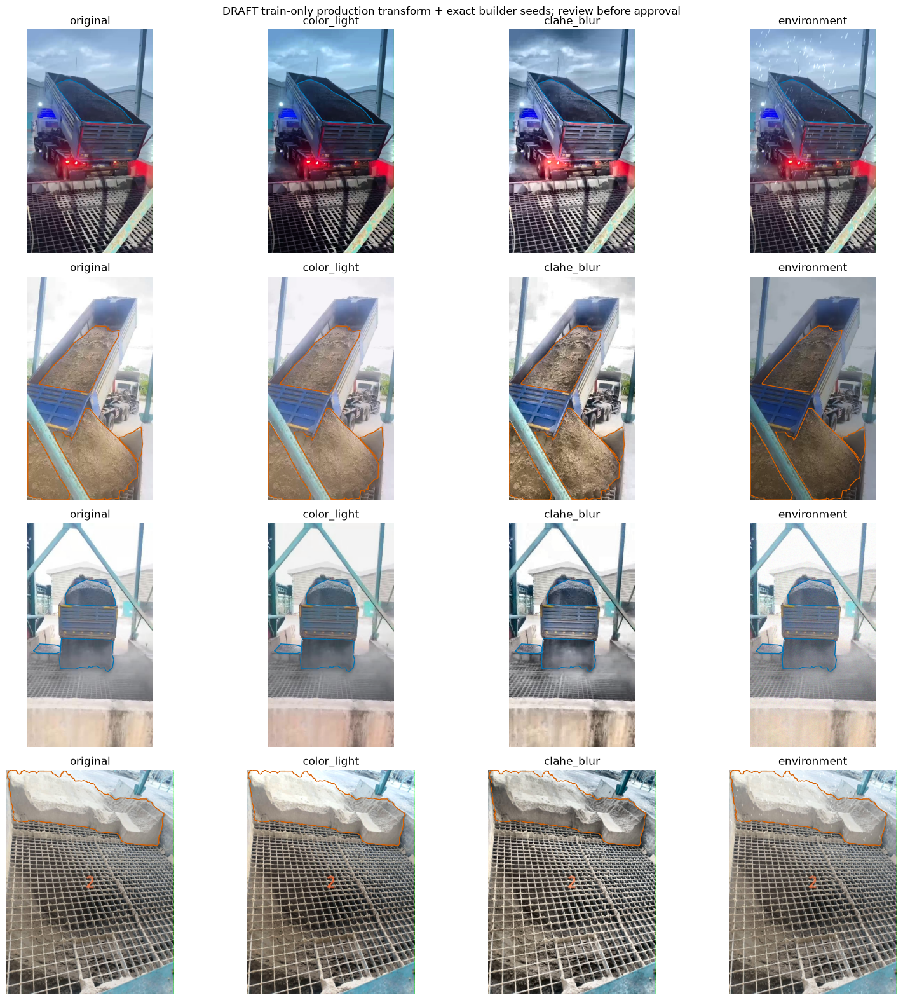

In [7]:
from shapely.geometry import Polygon as CVPolygon
CV_AUGMENTATION = dict(
    version='offline-recipe-v2-draft',status='preflight; production approval required',
    copies_per_parent=3,variants=['color_light','clahe_blur','environment'],
    gamma_range=[.85,1.90],brightness_range=[.90,1.10],hue_probability=.5,hue_degrees=[-15.,15.],
    saturation_probability=.5,saturation_range=[.85,1.15],white_balance_probability=.5,white_balance_rgb_gains=[.95,1.05],
    clahe_clip=2.,clahe_grid=[8,8],blur_probability=.5,blur_sigma=.35,
    environment_choices=['rain','noise','night'],environment_probabilities=[1/3,1/3,1/3],
    rain_density=[.0003,.0006],rain_angle_degrees=[75.,105.],rain_length_pixels=[8.,22.],rain_alpha=.6,
    noise_sigma=[.01,.03],night_gamma=[1.3,1.9],night_brightness=[.55,.80],night_rgb_tints=[[1.05,1.,.95],[.95,1.,1.05]],
    train_only=True,geometric=False,online_augmentation_owner='16',gamma_definition='output = input ** gamma; gamma > 1 darkens')

def cv_variant_seed(stem,variant):
    return int(hashlib.sha256(f'{CV_SEED}:{stem}:{variant}'.encode()).hexdigest()[:8],16)

def cv_parse_label(text):
    polys=[]
    for line in text.splitlines():
        if not line.strip(): continue
        parts=line.split(); assert len(parts)>=7 and (len(parts)-1)%2==0
        c=int(parts[0]); xy=np.asarray(parts[1:],float).reshape(-1,2)
        assert c in (0,1) and np.isfinite(xy).all() and ((xy>=0)&(xy<=1)).all()
        g=CVPolygon(xy)
        assert g.is_valid and g.area>0
        polys.append((c,xy))
    return polys

def cv_label_text(polys):
    return ''.join(str(c)+' '+' '.join(format(float(v),'.12g') for v in xy.ravel())+'\n' for c,xy in polys)

def cv_hflip_polys(polys):
    return [(c,np.column_stack([1-xy[:,0],xy[:,1]])) for c,xy in polys]

def cv_transform(image,polys,variant,seed):
    assert image.dtype==np.uint8 and image.ndim==3 and image.shape[2]==3
    rng=np.random.default_rng(seed); cfg=CV_AUGMENTATION; params={}
    if variant=='color_light':
        gamma=float(rng.uniform(*cfg['gamma_range'])); gain=float(rng.uniform(*cfg['brightness_range']))
        out=np.clip((image.astype(np.float32)/255.)**gamma*255*gain,0,255).round().astype(np.uint8)
        params.update(gamma=gamma,brightness_gain=gain)
        hsv=cv2.cvtColor(out,cv2.COLOR_BGR2HSV).astype(np.float32)
        if rng.random()<cfg['hue_probability']:
            degrees=float(rng.uniform(*cfg['hue_degrees'])); hsv[:,:,0]=(hsv[:,:,0]+degrees/2)%180
            params['hue_degrees']=degrees
        if rng.random()<cfg['saturation_probability']:
            saturation=float(rng.uniform(*cfg['saturation_range'])); hsv[:,:,1]*=saturation
            params['saturation_gain']=saturation
        out=cv2.cvtColor(np.clip(hsv,0,255).round().astype(np.uint8),cv2.COLOR_HSV2BGR)
        if rng.random()<cfg['white_balance_probability']:
            rgb=rng.uniform(*cfg['white_balance_rgb_gains'],size=3)
            out=np.clip(out.astype(np.float32)*rgb[::-1],0,255).round().astype(np.uint8)
            params['white_balance_rgb_gains']=rgb.tolist()
    elif variant=='clahe_blur':
        lab=cv2.cvtColor(image,cv2.COLOR_BGR2LAB)
        lab[:,:,0]=cv2.createCLAHE(clipLimit=cfg['clahe_clip'],tileGridSize=tuple(cfg['clahe_grid'])).apply(lab[:,:,0])
        out=cv2.cvtColor(lab,cv2.COLOR_LAB2BGR)
        params.update(clip=cfg['clahe_clip'],grid=cfg['clahe_grid'],blur_applied=False)
        if rng.random()<cfg['blur_probability']:
            out=cv2.GaussianBlur(out,(3,3),cfg['blur_sigma'])
            params.update(blur_applied=True,blur_sigma=cfg['blur_sigma'])
    elif variant=='environment':
        method=str(rng.choice(cfg['environment_choices'],p=cfg['environment_probabilities'])); params['method']=method
        if method=='rain':
            h,w=image.shape[:2]; density=float(rng.uniform(*cfg['rain_density']))
            angle=float(rng.uniform(*cfg['rain_angle_degrees'])); radians=np.deg2rad(angle); overlay=np.zeros_like(image)
            streaks=int(h*w*density)
            for _ in range(streaks):
                x,y=rng.integers(w),rng.integers(h); length=float(rng.uniform(*cfg['rain_length_pixels']))
                cv2.line(overlay,(int(x),int(y)),(int(x+np.cos(radians)*length),int(y+np.sin(radians)*length)),(190,190,190),1,cv2.LINE_AA)
            out=cv2.addWeighted(image,1.,cv2.GaussianBlur(overlay,(3,3),0),cfg['rain_alpha'],0)
            params.update(density=density,streaks=streaks,angle_degrees=angle,alpha=cfg['rain_alpha'])
        elif method=='noise':
            sigma=float(rng.uniform(*cfg['noise_sigma']))
            out=np.clip(image.astype(np.float32)/255.+rng.normal(0,sigma,image.shape),0,1)
            out=(out*255).round().astype(np.uint8); params['sigma_0_1']=sigma
        else:
            gamma=float(rng.uniform(*cfg['night_gamma'])); gain=float(rng.uniform(*cfg['night_brightness']))
            rgb=np.asarray(cfg['night_rgb_tints'][int(rng.integers(2))])
            out=np.clip((image.astype(np.float32)/255.)**gamma*255*gain*rgb[::-1],0,255).round().astype(np.uint8)
            params.update(gamma=gamma,brightness_gain=gain,rgb_tint=rgb.tolist())
    else: raise ValueError('Unregistered augmentation')
    assert out.shape==image.shape and out.dtype==np.uint8
    return out,polys,params

def cv_check_raster(polys,shape):
    h,w=shape[:2]
    for c,xy in polys:
        mask=np.zeros((h,w),np.uint8); cv2.fillPoly(mask,[(xy*[w,h]).astype(np.int32)],1)
        assert mask.any(), 'Augmentation created zero-raster-support instance'

square=[(0,np.array([[.1,.2],[.4,.2],[.4,.6],[.1,.6]]))]
assert np.allclose(cv_hflip_polys(cv_hflip_polys(square))[0][1],square[0][1])
assert np.isclose(CVPolygon(cv_hflip_polys(square)[0][1]).area,CVPolygon(square[0][1]).area)
for bad in ['0 0 0 1 1 0 1 1 0','2 .1 .1 .5 .1 .5 .5','0 nan .1 .5 .1 .5 .5']:
    try: cv_parse_label(bad)
    except (AssertionError,ValueError): pass
    else: raise AssertionError('Invalid augmentation label accepted')
for variant in CV_AUGMENTATION['variants']:
    image=np.full((32,48,3),120,np.uint8)
    a,pp,params=cv_transform(image,square,variant,123)
    b,_,other=cv_transform(image,square,variant,123)
    assert np.array_equal(a,b) and params==other and pp is square and np.array_equal(image,np.full_like(image,120))
print('PASS deterministic photometric variants, source/label preservation and geometry regressions')
CV_SOURCE_CODE_ID=hashlib.sha256(json.dumps([''.join(c['source']) for c in json.loads((EXP/'00_EDA.ipynb').read_text())['cells'] if c['cell_type']=='code'],ensure_ascii=False).encode()).hexdigest()
CV_SPEC=dict(schema='groupcv-offline-v2',source_dataset_id=FINAL_ID,source_code_id=CV_SOURCE_CODE_ID,k=CV_K,seed=CV_SEED,inner_valid_fraction=CV_INNER_VALID_FRACTION,group_policy='merged group + UUID + byte/pixel duplicates + dHash<=6 conservative connected components',assignments_sha=hashlib.sha256(CV_ASSIGNMENTS.sort_values(['fold','stem']).to_csv(index=False).encode()).hexdigest(),augmentation=CV_AUGMENTATION,sampling=dict(parent='uniform_with_replacement',aug_variant_probabilities={v:.25 for v in ['original']+CV_AUGMENTATION['variants']},control_variant='original',hard_scene_oversampling=False),geometry_review='mechanical only; independent semantic review pending',evaluation_scope='development grouped CV; not external/untouched test')
CV_ID=hashlib.sha256(json.dumps(CV_SPEC,sort_keys=True).encode()).hexdigest()
CV_ROOT=EXP/'data'/('groupcv_offline_v2_'+CV_ID[:16])
print('CV dataset version:',CV_ROOT,'| materialization enabled:',BUILD_CV_OFFLINE)
train0=CV_ASSIGNMENTS[(CV_ASSIGNMENTS.fold==0)&(CV_ASSIGNMENTS.role=='train')]
preview_rows=train0.sort_values('stem').iloc[np.linspace(0,len(train0)-1,min(4,len(train0)),dtype=int)]
fig,axes=plt.subplots(len(preview_rows),4,figsize=(16,4*len(preview_rows)),squeeze=False)
preview_parameters=[]
for row,record in enumerate(preview_rows.itertuples(index=False)):
    image=cv2.imread(record.path)
    polys=cv_parse_label((FINAL_DATA/record.original_split/'labels'/(record.stem+'.txt')).read_text())
    for ax,variant in zip(axes[row],['original']+CV_AUGMENTATION['variants']):
        seed=cv_variant_seed(record.stem,variant)
        out,pp,params=(image,polys,{}) if variant=='original' else cv_transform(image,polys,variant,seed)
        cv_check_raster(pp,out.shape); ax.imshow(cv2.cvtColor(out,cv2.COLOR_BGR2RGB))
        for c,xy in pp:
            points=xy*[out.shape[1],out.shape[0]]; ax.plot(*np.vstack([points,points[0]]).T,color=['#0072B2','#D55E00'][c],lw=1)
        ax.set_title(variant); ax.axis('off')
        preview_parameters.append(dict(parent_stem=record.stem,variant=variant,seed=seed,params=params))
audit_json(AUDIT_OUT/'cv_preview_parameters.json',preview_parameters)
plt.suptitle('DRAFT train-only production transform + exact builder seeds; review before approval')
plt.tight_layout(); audit_fig('cv_offline_variants')

### 17.2 สร้าง folds แบบมีเวอร์ชันและตรวจ artifacts ทุกไฟล์

แต่ละ fold มี `control` และ `offline_aug` โดย `train`=inner-train, `valid`=inner-valid, `test`=outer-heldout ชื่อ `test` เป็น convention ของ loader ไม่ได้อ้างว่า untouched Validation/test ไม่เปลี่ยน Copy source files ไม่ใช้ hardlinks ที่แก้แล้วกระทบต้นฉบับ ตรวจพื้นที่ดิสก์ก่อนสร้าง ไม่อ่านหรือเขียนทับ `gold_aug` เก่า

Lineage เก็บ parent source ID, original group, conservative CV group, original split, role, arm, variant, parameters, seed และ hashes ตรวจ source snapshot ซ้ำหลังสร้าง Auditor hash ทุก image/label ตรวจ cohort ครบและ geometry/raster ของแต่ละ role และปฏิเสธ source/UUID/group leakage ข้าม role เผยแพร่ handoff เมื่อทั้ง 5 folds และ 2 arms ผ่านเท่านั้น

Audit ไม่รับรองว่าเหตุการณ์/ไซต์อิสระ เกณฑ์ fragment ถูกต้อง หรือ human labels ถูกต้อง ต้องระบุช่องว่างเหล่านี้ Offline augmentation ไม่เพิ่มจำนวน independent groups

In [8]:
def cv_build_offline():
    if CV_ROOT.exists():
        if not (CV_ROOT/'manifest.json').is_file(): raise FileExistsError('Incomplete CV version exists; inspect it, do not overwrite')
        assert json.loads((CV_ROOT/'manifest.json').read_text())['spec']==CV_SPEC
        return
    required_bytes=sum(Path(r.path).stat().st_size for r in CV_POOL.itertuples())*(2*CV_K+3*(CV_K-1))
    free=shutil.disk_usage(EXP/'data').free
    assert free>required_bytes*2+2**30, 'Insufficient disk headroom for copied folds and variants'
    CV_ROOT.mkdir(); lineage=[]
    CV_ASSIGNMENTS.to_csv(CV_ROOT/'assignments.csv',index=False)
    CV_LINKS.to_csv(CV_ROOT/'group_links.csv',index=False)
    CV_SUMMARY.to_csv(CV_ROOT/'role_support.csv',index=False)
    audit_json(CV_ROOT/'spec.json',CV_SPEC)
    for fold in range(CV_K):
        assignment=CV_ASSIGNMENTS[CV_ASSIGNMENTS.fold==fold]
        reference=FINAL_QUALITY.set_index('stem').loc[assignment.loc[assignment.role=='train','stem']]
        audit_json(CV_ROOT/f'quality_reference_fold{fold}.json',dict(selected_on='inner_train',fold=fold,source_stems=sorted(reference.index),thresholds={col:{'low':float(reference[col].quantile(.025)),'high':float(reference[col].quantile(.975))} for col in ['bright','lap','coverage','cast']}))
        for arm in ['control','offline_aug']:
            root=CV_ROOT/f'fold{fold}'/arm
            for split in ['train','valid','test']:
                for kind in ['images','labels']: (root/split/kind).mkdir(parents=True)
            for r in assignment.sort_values('stem').itertuples(index=False):
                split={'train':'train','valid':'valid','heldout':'test'}[r.role]
                source_image=Path(r.path); source_label=FINAL_DATA/r.original_split/'labels'/(r.stem+'.txt')
                variants=['original']+(CV_AUGMENTATION['variants'] if arm=='offline_aug' and r.role=='train' else [])
                image=None; polygons=None
                for variant in variants:
                    variant_seed=cv_variant_seed(r.stem,variant)
                    name=r.image if variant=='original' else r.stem+'__cvaug_'+variant+'.png'
                    target_image=root/split/'images'/name; target_label=root/split/'labels'/(Path(name).stem+'.txt'); params={}
                    if variant=='original':
                        shutil.copy2(source_image,target_image); shutil.copy2(source_label,target_label)
                    else:
                        if image is None: image=cv2.imread(str(source_image)); polygons=cv_parse_label(source_label.read_text())
                        out,pp,params=cv_transform(image,polygons,variant,variant_seed)
                        assert out.shape==image.shape and len(pp)==len(polygons)
                        if not cv2.imwrite(str(target_image),out): raise OSError('Augmented image write failed')
                        shutil.copy2(source_label,target_label)
                    restored=cv_parse_label(target_label.read_text()); cv_check_raster(restored,(r.height,r.width))
                    assert len(restored)==r.gravel+r.sand, 'Instance count changed during augmentation'
                    lineage.append(dict(fold=fold,arm=arm,role=r.role,image=name,stem=Path(name).stem,parent_stem=r.stem,original_split=r.original_split,original_group=r.original_group,cv_group=r.cv_group,upload_uuid=r.upload_uuid,variant=variant,seed=variant_seed,params=json.dumps(params,sort_keys=True),image_path=str(target_image.relative_to(CV_ROOT)),label_path=str(target_label.relative_to(CV_ROOT)),image_sha=audit_sha(target_image),label_sha=audit_sha(target_label),source_image_sha=r.image_sha,source_label_sha=r.label_sha))
            (root/'data.yaml').write_text(f'path: {root.resolve()}\ntrain: train/images\nval: valid/images\ntest: test/images\nnames: [gravel, sand]\n')
        print('Materialized fold',fold,flush=True)
    frame=pd.DataFrame(lineage); frame.to_csv(CV_ROOT/'lineage.csv',index=False)
    for r in CV_POOL.itertuples(index=False):
        assert audit_sha(r.path)==r.image_sha
        assert audit_sha(FINAL_DATA/r.original_split/'labels'/(r.stem+'.txt'))==r.label_sha
    artifacts=['assignments.csv','group_links.csv','role_support.csv','lineage.csv','spec.json']+[f'quality_reference_fold{f}.json' for f in range(CV_K)]+[f'fold{f}/{arm}/data.yaml' for f in range(CV_K) for arm in ['control','offline_aug']]
    audit_json(CV_ROOT/'manifest.json',dict(spec=CV_SPEC,cv_id=CV_ID,artifacts={name:audit_sha(CV_ROOT/name) for name in artifacts},status='materialized; audit required'))

def cv_audit_materialized():
    manifest=json.loads((CV_ROOT/'manifest.json').read_text())
    assert manifest['spec']==CV_SPEC and manifest['cv_id']==CV_ID
    for name,sha in manifest['artifacts'].items():
        path=(CV_ROOT/name).resolve(); assert path.is_relative_to(CV_ROOT.resolve()) and audit_sha(path)==sha
    frame=pd.read_csv(CV_ROOT/'lineage.csv',keep_default_na=False)
    assert not frame.duplicated(['fold','arm','image']).any()
    assert set(frame.parent_stem)==set(CV_POOL.stem)
    pool=CV_POOL.set_index('stem'); reports=[]
    for fold in range(CV_K):
        assignment=CV_ASSIGNMENTS[CV_ASSIGNMENTS.fold==fold]; cv_check_disjoint(assignment)
        reference=json.loads((CV_ROOT/f'quality_reference_fold{fold}.json').read_text())
        assert reference['selected_on']=='inner_train' and set(reference['source_stems'])==set(assignment.loc[assignment.role=='train','stem'])
        for arm in ['control','offline_aug']:
            sub=frame[(frame.fold==fold)&(frame.arm==arm)]
            assert sub.groupby('cv_group').role.nunique().eq(1).all()
            for role in ['train','valid','heldout']:
                rows=sub[sub.role==role]; expected=set(assignment.loc[assignment.role==role,'stem'])
                assert set(rows.parent_stem)==expected
                variants={'original',*CV_AUGMENTATION['variants']} if arm=='offline_aug' and role=='train' else {'original'}
                assert len(rows)==len(expected)*len(variants)
                assert rows.groupby('parent_stem').variant.apply(set).map(lambda x:x==variants).all()
                split={'train':'train','valid':'valid','heldout':'test'}[role]; root=CV_ROOT/f'fold{fold}'/arm/split
                assert {p.name for p in (root/'images').iterdir()}==set(rows.image)
                assert {p.stem for p in (root/'labels').glob('*.txt')}==set(rows.stem)
                for r in rows.itertuples(index=False):
                    source=pool.loc[r.parent_stem]; ip=CV_ROOT/r.image_path; lp=CV_ROOT/r.label_path
                    assert ip.resolve().is_relative_to(CV_ROOT.resolve()) and lp.resolve().is_relative_to(CV_ROOT.resolve())
                    assert r.cv_group==source.cv_group and r.original_group==source.original_group
                    assert audit_sha(ip)==r.image_sha and audit_sha(lp)==r.label_sha
                    image=cv2.imread(str(ip)); assert image is not None and image.shape[:2]==(source.height,source.width)
                    pp=cv_parse_label(lp.read_text()); cv_check_raster(pp,image.shape)
                    assert len(pp)==source.gravel+source.sand
                    if r.variant=='original': assert r.image_sha==source.image_sha and r.label_sha==source.label_sha
                    else: assert r.label_sha==source.label_sha
                reports.append(dict(fold=fold,arm=arm,role=role,images=len(rows),parents=len(expected),groups=rows.cv_group.nunique(),status='PASS'))
    for r in CV_POOL.itertuples(index=False):
        assert audit_sha(r.path)==r.image_sha and audit_sha(FINAL_DATA/r.original_split/'labels'/(r.stem+'.txt'))==r.label_sha
    return frame,pd.DataFrame(reports)

if BUILD_CV_OFFLINE: cv_build_offline()
CV_LINEAGE=None; CV_BUILD_AUDIT=None
if (CV_ROOT/'manifest.json').is_file():
    CV_LINEAGE,CV_BUILD_AUDIT=cv_audit_materialized()
    CV_BUILD_AUDIT.to_csv(AUDIT_OUT/'cv_materialization_audit.csv',index=False)
    print(CV_BUILD_AUDIT.to_string(index=False)); print('PASS: full fold/variant hashes, role ownership, labels, evaluation byte identity and source preservation')
else: print('PENDING materialization: explicitly set NB00_BUILD_CV=1 for the authorized preparation run; existing datasets are never overwritten.')

Materialized fold 0


Materialized fold 1


Materialized fold 2


Materialized fold 3


Materialized fold 4


 fold         arm    role  images  parents  groups status
    0     control   train     737      737      16   PASS
    0     control   valid     183      183       4   PASS
    0     control heldout     164      164       5   PASS
    0 offline_aug   train    2948      737      16   PASS
    0 offline_aug   valid     183      183       4   PASS
    0 offline_aug heldout     164      164       5   PASS
    1     control   train     543      543      16   PASS
    1     control   valid     140      140       4   PASS
    1     control heldout     401      401       5   PASS
    1 offline_aug   train    2172      543      16   PASS
    1 offline_aug   valid     140      140       4   PASS
    1 offline_aug heldout     401      401       5   PASS
    2     control   train     728      728      16   PASS
    2     control   valid     191      191       4   PASS
    2     control heldout     165      165       5   PASS
    2 offline_aug   train    2912      728      16   PASS
    2 offline_

### 17.3 Handoff v2 และจุดหยุดก่อน production

Handoff `nb00-groupcv-v2` ผูก source code/dataset, assignments, lineage, recipe และ artifact hashes ไปยัง `16` ตัวรับต้องปฏิเสธ v1/stale handoff ไม่หยิบชุดเก่ามาใช้กับ recipe ใหม่

ประวัติ 2026-10-13: dataset v1 + bounded smoke ถูกสร้าง/รันแล้ว และ full-CV v1 มีผลบางงานสำเร็จ/บางงานล้มเหลว หลักฐานเหล่านั้นไม่ใช่ผลของ offline+online v2 Outputs เดิมคงไว้เป็นประวัติ ไม่อ้างว่า v2 ผ่าน audit หรือฝึกแล้ว

ขั้นตอน v2: audit source → preview offline → materialize แบบเปิดเอง → audit ทุกไฟล์ → preview production loader ใน `16` → เจ้าของยืนยัน protocol/preview identity → training → freeze checkpoint/threshold จาก inner-valid → เปิด evaluation แยก

Independent annotation review, event/site metadata, negative/background validation และ external ZIP ontology/annotation/duplicate audit ยังต้องรายงานตามจริง ไม่เรียก test/external ว่า untouched หรือ independent โดยไม่มีหลักฐาน

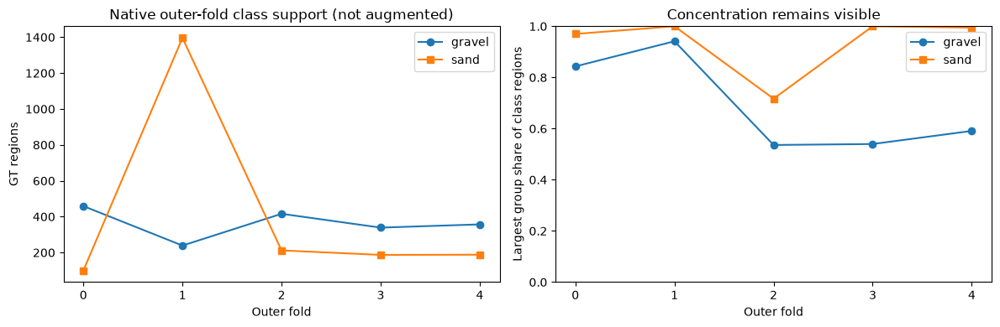

Audited CV handoff: /home/supawich/Desktop/Aggregate_Project/experiment/results/nb00_audit/20261014T075628792047Z/cv_handoff.json
Next: notebook 16 audit + explicitly enabled bounded smoke; STOP before full CV training.


In [9]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
held=CV_SUMMARY[CV_SUMMARY.role=='heldout']
for cn,marker in zip(['gravel','sand'],['o','s']):
    sub=held[held.cls==cn]
    axes[0].plot(sub.fold,sub.instances,marker=marker,label=cn)
    axes[1].plot(sub.fold,sub.largest_group_instance_share,marker=marker,label=cn)
axes[0].set(xlabel='Outer fold',ylabel='GT regions',title='Native outer-fold class support (not augmented)')
axes[1].set(xlabel='Outer fold',ylabel='Largest group share of class regions',ylim=(0,1),title='Concentration remains visible')
for ax in axes: ax.legend(); ax.set_xticks(range(CV_K))
plt.tight_layout(); audit_fig('cv_fold_support_and_concentration')
if CV_LINEAGE is not None:
    CV_HANDOFF=dict(schema='nb00-groupcv-v2',status='PASS',source_dataset_id=FINAL_ID,source_code_id=CV_SOURCE_CODE_ID,cv_id=CV_ID,cv_root=str(CV_ROOT.resolve()),manifest_sha=audit_sha(CV_ROOT/'manifest.json'),folds=CV_K,geometry_status=GEOMETRY_STATUS,split_before_augmentation=True,original_source_preserved=True,outer_evaluation='not authorized for audit/smoke phase',full_cv_training=False,scope=CV_SPEC['evaluation_scope'],protocol=CV_SPEC)
    audit_json(AUDIT_OUT/'cv_handoff.json',CV_HANDOFF)
    print('Audited CV handoff:',AUDIT_OUT/'cv_handoff.json')
    print('Next: notebook 16 audit + explicitly enabled bounded smoke; STOP before full CV training.')
else: print('CV handoff not published: materialization/audit pending.')